# Termal Görüntülerde Uç Cihaz Odaklı Nesne Tespiti

**Lisans Bitirme Projesi** · Feritcan Obuz · Eskişehir Osmangazi Üniversitesi, İstatistik Bölümü

Bu notebook, FLIR ADAS termal veri seti üzerinde YOLO11 ile nesne tespiti yaptığım bitirme projemin tüm çalışma akışını içeriyor. Veriyi ilk açtığım andan, son modeli TensorRT INT8'e çevirip bir video üzerinde çalıştırdığım ana kadar ne yaptıysam sırasıyla burada.

Projenin çıkış sorusu şuydu: gece, sis veya düşük ışıkta RGB kameranın göremediği yayaları, bisikletlileri ve araçları termal kamerayla tespit edebilir miyiz, ve bunu bir araca takılabilecek kadar hafif ve hızlı bir modelle yapabilir miyiz?

### Akış

| Bölüm | İçerik |
|---|---|
| 1 | Ortam kurulumu ve dosya yapısı |
| 2 | Görüntülerin teknik profili ve kontrast analizi |
| 3 | Etiket analizi: sınıf dengesizliği, kutu boyutları, en-boy oranları |
| 4 | COCO JSON'dan YOLO formatına dönüşüm ve doğrulama |
| 5 | V1 baseline (YOLO11n) ve detaylı hata analizi |
| 6 | İyileştirme denemeleri: augmentation, büyük model, CLAHE, oversampling, 3 sınıfa geçiş (V2-V6) |
| 7 | Modellerin karşılaştırılması |
| 8 | Quantization: PyTorch FP32, ONNX FP32/INT8, TensorRT INT8 |
| 9 | Test videosu üzerinde çıkarım |
| 10 | Sonuç, sınırlılıklar ve sonraki adımlar |

### Kısaca sonuçlar

Final model V6 (YOLO11s, 3 sınıf) doğrulama setinde **mAP@50 = 0.796** verdi. TensorRT INT8'e çevrildiğinde mAP@50 0.760'a indi, buna karşılık T4 GPU üzerinde **103 FPS'ten 229 FPS'e** çıktı.

FLIR'ın kendi README dosyasında verdiği RefineDet512 baseline'ı ile sınıf bazında karşılaştırınca (değerlendirme araçları farklı olduğu için yaklaşık bir kıyas):

| Sınıf | FLIR baseline (RefineDet512) | V6 FP32 | V6 TensorRT INT8 |
|---|---:|---:|---:|
| Person | 0.794 | 0.844 | 0.798 |
| Bicycle | 0.580 | 0.639 | 0.598 |
| Car | 0.856 | 0.905 | 0.885 |

INT8 model bile üç sınıfta da FLIR baseline'ının üzerinde kalıyor.

> Not: Notebook Google Colab'da (Tesla T4) çalıştırıldı ve veri Drive'dan okunuyor. Birkaç kez oturum düştüğü için bazı bölümlerin başında kütüphaneleri tekrar yüklediğim hücreler var. Veri seti lisans gereği repoda yok, nasıl indirileceği README'de anlatılıyor.

## 1. Ortam ve Dosya Yapısı

### 1.1 Proje klasörü

İlk iş Drive'daki klasör yapısına bakmak. FLIR veri seti `train`, `val` ve `video` olmak üzere üç parçadan oluşuyor, her birinin içinde de 8-bit termal, 16-bit termal, RGB ve etiketli görüntü klasörleri var.

In [ ]:
import os
from pathlib import Path

def generate_tree(dir_path, prefix="", max_depth=3, current_depth=0):
    if current_depth > max_depth:
        return

    path_obj = Path(dir_path)
    if not path_obj.exists():
        return

    try:
        # Filter hidden files and sort directories first for better visibility
        items = [p for p in path_obj.iterdir() if not p.name.startswith('.')]
        items.sort(key=lambda x: (not x.is_dir(), x.name.lower()))
    except PermissionError:
        return

    total_items = len(items)
    for index, item in enumerate(items):
        is_last = (index == total_items - 1)
        connector = "└── " if is_last else "├── "

        if item.is_dir():
            print(f"{prefix}{connector}{item.name}")
            extension = "    " if is_last else "│   "
            generate_tree(item, prefix + extension, max_depth, current_depth + 1)
        else:
            # Calculate size in MB for file analysis
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"{prefix}{connector}{item.name} ({size_mb:.2f} MB)")

# Configuration
BASE_PATH = "/content/drive/MyDrive/tez"

# Execution
print(f"Project Root: {BASE_PATH}")
generate_tree(BASE_PATH, max_depth=2)

Project Root: /content/drive/MyDrive/tez
├── data
│   ├── train
│   │   ├── Annotated_thermal_8_bit
│   │   ├── images
│   │   ├── labels
│   │   ├── RGB
│   │   ├── thermal_16_bit
│   │   ├── labels.cache (5.38 MB)
│   │   └── thermal_annotations.json (29.03 MB)
│   ├── train_3class
│   │   ├── images
│   │   ├── labels
│   │   └── labels.cache (5.43 MB)
│   ├── train_clahe
│   │   ├── images
│   │   ├── labels
│   │   └── labels.cache (5.48 MB)
│   ├── train_weighted
│   │   ├── images
│   │   ├── labels
│   │   └── labels.cache (14.69 MB)
│   ├── val
│   │   ├── Annotated_thermal_8_bit
│   │   ├── images
│   │   ├── labels
│   │   ├── RGB
│   │   ├── thermal_16_bit
│   │   ├── labels.cache (0.43 MB)
│   │   └── thermal_annotations.json (4.97 MB)
│   ├── val_3class
│   │   ├── images
│   │   ├── labels
│   │   └── labels.cache (0.44 MB)
│   ├── video
│   │   ├── Annotated_thermal_8_bit
│   │   ├── RGB
│   │   ├── thermal_16_bit
│   │   ├── thermal_8_bit
│   │   └── thermal_annotation

### 1.2 Donanım kontrolü ve seed

Deneyleri birbiriyle karşılaştırabilmek için seed'i sabitledim ve cuDNN'i deterministik moda aldım. Eğitimler saatler sürdüğü için GPU'nun gerçekten atanmış olduğunu da en başta kontrol ediyorum.

In [ ]:
import torch
import numpy as np
import random

# Tez sonuclarinin tutarli olmasi ve her egitimde ayni degerleri almak icin seed sabitliyorum.
def setup_environment(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # GPU varsa donanimsal rastgeleligi de kapatiyorum ki sonuclar sasmasin.
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    print("System Diagnostics:")

    # Egitim uzun surecegi icin GPU'nun aktif oldugundan ve belleginden emin olmam lazim.
    if torch.cuda.is_available():
        gpu_name = torch.cuda.get_device_name(0)
        gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f"GPU: {gpu_name} | VRAM: {gpu_mem:.2f} GB")
    else:
        print("WARNING: GPU not detected! Change runtime to GPU.")

    # Veri setini Drive uzerinden okuyacagim icin baglantiyi kontrol ediyorum.
    drive_path = "/content/drive"
    if not os.path.exists(drive_path):
        print("WARNING: Google Drive not mounted!")
        from google.colab import drive
        drive.mount('/content/drive')
    else:
        print(f"Google Drive: Mounted")

setup_environment()

System Diagnostics:
GPU: Tesla T4 | VRAM: 14.56 GB
Google Drive: Mounted


## 2. Görüntülerin Teknik Profili

### 2.1 Boyut, kanal ve piksel aralığı

Etiketlere geçmeden önce ham görüntülerin kendisine bakmak istedim: hepsi aynı boyutta mı, kaç kanallı, bozuk dosya var mı. 100 rastgele görüntü bu kontroller için yeterli.

In [ ]:
import cv2
from pathlib import Path
import random

TRAIN_IMG_PATH = "/content/drive/MyDrive/tez/data/train/thermal_8_bit"

# Klasördeki tüm JPEG dosyalarını buluyorum
image_files = list(Path(TRAIN_IMG_PATH).glob("*.jpeg"))

# Hız için rastgele 100 tanesini seçiyorum
sample_files = random.sample(image_files, min(100, len(image_files)))

# Her görüntünün özelliklerini saklayacağım listeler
shapes = []
channels = []
dtypes = []
min_vals = []
max_vals = []
corrupt_count = 0

print(f"Taranan Dosya Sayısı: {len(sample_files)}\n")

for img_path in sample_files:
    try:
        # Görüntüyü olduğu gibi okuyorum, manipülasyon yapmadan
        img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)

        # Dosya bozuksa None döner
        if img is None:
            corrupt_count += 1
            continue

        shapes.append(img.shape)
        dtypes.append(img.dtype)
        min_vals.append(img.min())
        max_vals.append(img.max())

        # Tek kanallı mı yoksa RGB formatında mı kaydedilmiş kontrol ediyorum
        if len(img.shape) == 2:
            channels.append(1)
        else:
            channels.append(img.shape[2])

    except Exception as e:
        corrupt_count += 1

# Farklı boyut ve format var mı diye tekil değerlere bakıyorum
unique_shapes = set(shapes)
unique_channels = set(channels)
unique_dtypes = set(dtypes)

print(f"Tekil Boyutlar: {unique_shapes}")
print(f"Kanal Sayıları: {unique_channels}")
print(f"Veri Tipleri: {unique_dtypes}")
print(f"\nMin Piksel Değeri: {min(min_vals)}")
print(f"Max Piksel Değeri: {max(max_vals)}")
print(f"Min-Max Orta Noktası: {np.mean([np.mean(min_vals), np.mean(max_vals)]):.2f}")
print(f"\nBozuk Dosya Sayısı: {corrupt_count}")

Taranan Dosya Sayısı: 100

Tekil Boyutlar: {(512, 640)}
Kanal Sayıları: {1}
Veri Tipleri: {dtype('uint8')}

Min Piksel Değeri: 0
Max Piksel Değeri: 255
Min-Max Orta Noktası: 127.67

Bozuk Dosya Sayısı: 0


Sonuçlar:

- Tüm görüntüler 640x512. Boyut tutarlı olduğu için resize sırasında farklı oranlarla uğraşmam gerekmeyecek.
- OpenCV dosyaları tek kanal (grayscale) olarak okuyor. YOLO 3 kanal bekliyor ama Ultralytics görüntüyü okurken zaten 3 kanala çeviriyor, ayrıca bir ayar yapmam gerekmiyor.
- Bozuk dosya yok.
- Burada yazdırdığım 127.67 değeri gerçek bir ortalama değil, min ve max değerlerinin orta noktası. Gerçek piksel ortalamasını 2.3'te hesapladım (135.35).

### 2.2 Dört formatın karşılaştırması

Her görüntünün `thermal_8_bit`, `thermal_16_bit`, `RGB` ve `Annotated_thermal_8_bit` olmak üzere dört hali var. Hangisiyle çalışacağıma karar vermek için aynı kareyi dört formatta yan yana koydum. Önce dosya isimlerinin klasörler arasında eşleşip eşleşmediğine bakıyorum.

In [ ]:
BASE_PATH = "/content/drive/MyDrive/tez/data/train"

# Her klasörden ilk 5 dosya ismini görelim
folders = ['thermal_8_bit', 'thermal_16_bit', 'RGB', 'Annotated_thermal_8_bit']

for folder in folders:
    folder_path = Path(f"{BASE_PATH}/{folder}")
    if folder_path.exists():
        files = list(folder_path.glob("*"))[:5]
        print(f"\n{folder}:")
        for f in files:
            print(f"  {f.name}")
    else:
        print(f"\n{folder}: Klasör bulunamadı")


thermal_8_bit:
  FLIR_07846.jpeg
  FLIR_07839.jpeg
  FLIR_07828.jpeg
  FLIR_07896.jpeg
  FLIR_07845.jpeg

thermal_16_bit:
  FLIR_07880.tiff
  FLIR_07909.tiff
  FLIR_07863.tiff
  FLIR_07911.tiff
  FLIR_07871.tiff

RGB:
  FLIR_07864.jpg
  FLIR_07889.jpg
  FLIR_07887.jpg
  FLIR_07863.jpg
  FLIR_07866.jpg

Annotated_thermal_8_bit:
  FLIR_07857.jpeg
  FLIR_07878.jpeg
  FLIR_07953.jpeg
  FLIR_07925.jpeg
  FLIR_07927.jpeg


In [ ]:
from pathlib import Path

BASE_PATH = "/content/drive/MyDrive/tez/data/train"

# Her klasördeki tüm dosya isimlerini alıyorum (uzantısız)
thermal_8bit_ids = {f.stem for f in Path(f"{BASE_PATH}/thermal_8_bit").glob("*")}
thermal_16bit_ids = {f.stem for f in Path(f"{BASE_PATH}/thermal_16_bit").glob("*")}
rgb_ids = {f.stem for f in Path(f"{BASE_PATH}/RGB").glob("*")}
annotated_ids = {f.stem for f in Path(f"{BASE_PATH}/Annotated_thermal_8_bit").glob("*")}

# 4 klasörde de ortak olan ID'leri buluyorum
common_ids = thermal_8bit_ids & thermal_16bit_ids & rgb_ids & annotated_ids

print(f"4 klasörde de ortak olan görüntü sayısı: {len(common_ids)}")
print(f"Örnek ortak ID'ler: {list(common_ids)[:5]}")

# İlk ortak ID'yi seçiyorum
if common_ids:
    selected_id = list(common_ids)[0]
    print(f"\nSeçilen ID: {selected_id}")

4 klasörde de ortak olan görüntü sayısı: 8363
Örnek ortak ID'ler: ['FLIR_08482', 'FLIR_03815', 'FLIR_02562', 'FLIR_08059', 'FLIR_08320']

Seçilen ID: FLIR_08482


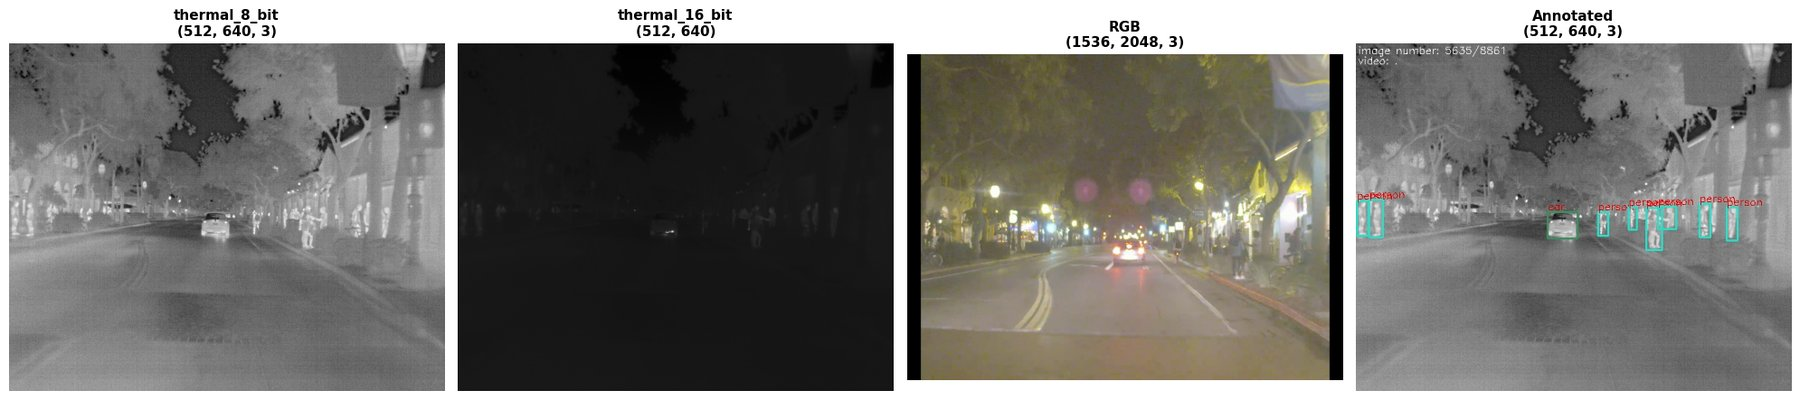

In [ ]:
import matplotlib.pyplot as plt
BASE_PATH = "/content/drive/MyDrive/tez/data/train"
sample_id = "FLIR_05636"

# 4 farklı formattaki yolları hazırlıyorum
paths = {
    'thermal_8_bit': f"{BASE_PATH}/thermal_8_bit/{sample_id}.jpeg",
    'thermal_16_bit': f"{BASE_PATH}/thermal_16_bit/{sample_id}.tiff",
    'RGB': f"{BASE_PATH}/RGB/{sample_id}.jpg",
    'Annotated': f"{BASE_PATH}/Annotated_thermal_8_bit/{sample_id}.jpeg"
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, (format_name, img_path) in enumerate(paths.items()):
    if Path(img_path).exists():
        # 16-bit TIFF için özel okuma yapıyorum
        if format_name == 'thermal_16_bit':
            img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
            # 16-bit ham veriyi görselleştirmek için normalize ediyorum
            img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
            img = img.astype('uint8')
        else:
            img = cv2.imread(img_path)
            # RGB formatındaysa BGR'den RGB'ye çeviriyorum
            if len(img.shape) == 3 and format_name == 'RGB':
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(img, cmap='gray' if format_name != 'RGB' else None)
        axes[idx].set_title(f'{format_name}\n{img.shape}', fontsize=11, fontweight='bold')
        axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, 'Dosya Yok', ha='center', va='center')
        axes[idx].set_title(format_name, fontsize=11, fontweight='bold')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

Görselde formatlar arasındaki fark net görülüyor:

- **thermal_8_bit:** AGC (otomatik kazanç kontrolü) uygulanmış hali. Kontrast iyi, nesneler kolay seçiliyor. `cv2.imread` varsayılan olarak 3 kanal okuduğu için başlıkta (512, 640, 3) yazıyor ama içerik grayscale.
- **thermal_16_bit:** Sensörden gelen ham 14-bit veri. Min-max normalize etmeme rağmen çok karanlık, çünkü değerlerin çoğu dar bir aralıkta toplanmış ve birkaç sıcak nokta skalayı germiş. Kullanmak için ayrı bir ön işleme gerekir.
- **RGB:** Çözünürlük ve bakış açısı farklı. README'de de yazdığı gibi iki kamera aynı noktada değil, bu yüzden termal etiketler RGB'ye doğrudan aktarılamıyor.
- **Annotated:** 8-bit görüntünün üzerine kutular çizilmiş hali, sadece kontrol amaçlı.

Bu yüzden tüm çalışmada `thermal_8_bit` kullandım.

### 2.3 Piksel yoğunluğu ve kontrast

Termal görüntülerde renk bilgisi olmadığı için modelin elindeki tek şey yoğunluk farkı. Kontrastın ne durumda olduğunu görmek için önce 100 görüntünün birleşik histogramına, sonra tek tek en kötü örneklere baktım.

#### 2.3.1 Genel dağılım (100 görüntü)

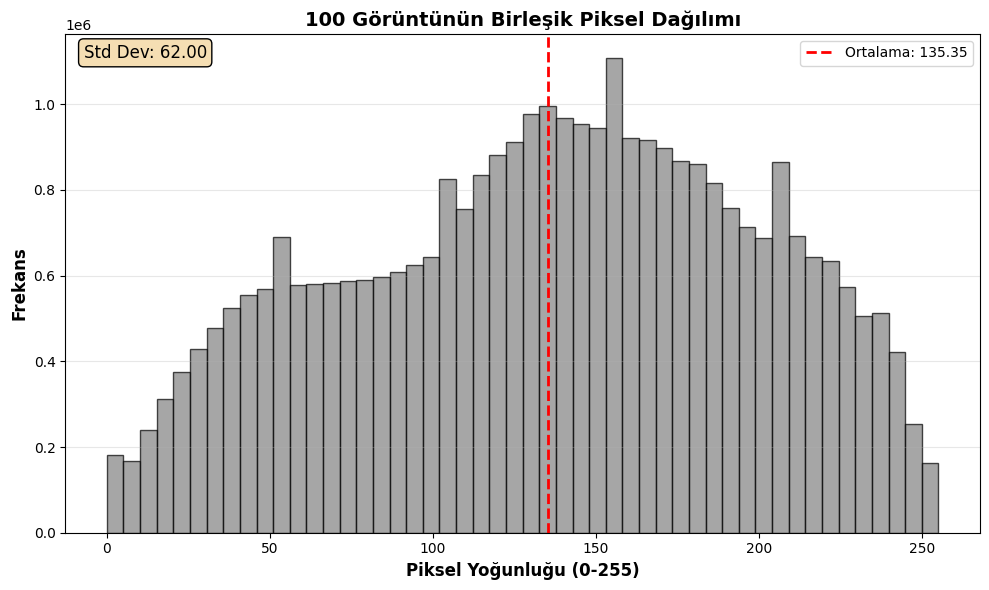

Ortalama Piksel Değeri: 135.35
Standart Sapma: 62.00


In [ ]:
sample_files = random.sample(image_files, 100)
all_pixels = []

# 100 görüntüyü okuyup tüm pikselleri topluyorum
for img_path in sample_files:
    img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        all_pixels.extend(img.flatten())

all_pixels = np.array(all_pixels)

# İstatistikleri hesapliyorum
mean_val = np.mean(all_pixels)
std_val = np.std(all_pixels)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(all_pixels, bins=50, color='gray', edgecolor='black', alpha=0.7)
ax.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Ortalama: {mean_val:.2f}')
ax.set_xlabel('Piksel Yoğunluğu (0-255)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frekans', fontsize=12, fontweight='bold')
ax.set_title('100 Görüntünün Birleşik Piksel Dağılımı', fontsize=14, fontweight='bold')
ax.text(0.02, 0.98, f'Std Dev: {std_val:.2f}', transform=ax.transAxes,
        fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat'))
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Ortalama Piksel Değeri: {mean_val:.2f}")
print(f"Standart Sapma: {std_val:.2f}")

#### 2.3.2 En düşük kontrastlı örnekler

Genel histogram iyi görünüyor (ortalama 135, standart sapma 62) ama model her görüntüyü ayrı ayrı işliyor. Ortalama iyi olsa bile tek tek görüntülerde kontrast çok düşük olabilir. Bu yüzden 500 görüntü içinden standart sapması en düşük dört görüntüyü buldum.

500 goruntu taranarak dusuk kontrastli ornekler araniyor...


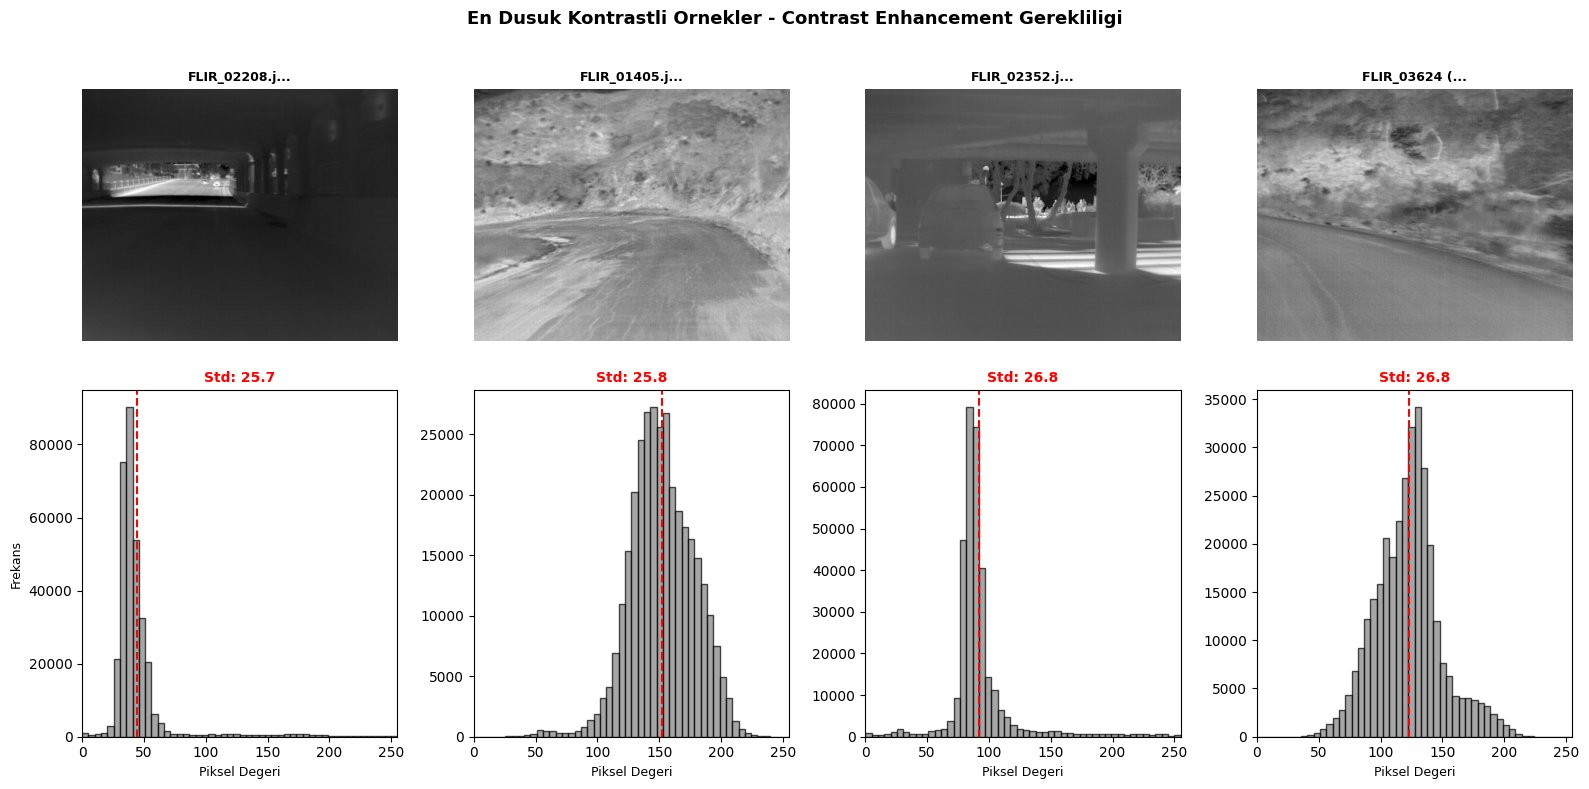


En dusuk std: 25.74 | Genel ortalama std: 62.00


In [ ]:
search_pool = random.sample(image_files, min(500, len(image_files)))
results = []

print("500 goruntu taranarak dusuk kontrastli ornekler araniyor...")

for img_path in search_pool:
    img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        std_val = np.std(img)
        results.append((std_val, img, img_path.name))

results.sort(key=lambda x: x[0])
worst_4 = results[:4]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, (std_val, img, name) in enumerate(worst_4):
    axes[0, idx].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0, idx].set_title(f'{name[:12]}...', fontsize=9, fontweight='bold')
    axes[0, idx].axis('off')

    pixels = img.flatten()
    mean_val = np.mean(pixels)

    axes[1, idx].hist(pixels, bins=50, range=(0,255), color='gray', edgecolor='black', alpha=0.7)
    axes[1, idx].axvline(mean_val, color='red', linestyle='--', linewidth=1.5)
    axes[1, idx].set_xlim(0, 255)
    axes[1, idx].set_title(f'Std: {std_val:.1f}', fontsize=10, fontweight='bold', color='red')
    axes[1, idx].set_xlabel('Piksel Degeri', fontsize=9)

    if idx == 0:
        axes[1, idx].set_ylabel('Frekans', fontsize=9)

plt.suptitle("En Dusuk Kontrastli Ornekler - Contrast Enhancement Gerekliligi", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nEn dusuk std: {worst_4[0][0]:.2f} | Genel ortalama std: 62.00")


En düşük standart sapma 25.7 çıktı, yani genel değerin (62) yarısından az. İlk görüntü neredeyse tamamen karanlık, histogram 0-50 aralığına sıkışmış. İkinci ve üçüncüde her yer aynı gri tonda, detay çok az. Dördüncü biraz daha iyi ama o da 26.8'de kalıyor.

Genel istatistikler bu tür örnekleri saklıyor. Veri setinde kontrastı ortalamanın 2.5 kat altına düşen görüntüler var ve bu görüntülerde küçük nesnelerin arka plandan ayrışması zor olacak. İleride CLAHE ile kontrast iyileştirmeyi denememin (V4) sebebi bu bulgu.

## 3. Etiket Analizi

### 3.1 JSON yapısı

Etiketler COCO formatında bir JSON dosyasında. Kaç görüntü, kaç etiket ve hangi sınıflar olduğuna bakıyorum.

In [ ]:
import json

ANNOTATION_PATH = "/content/drive/MyDrive/tez/data/train/thermal_annotations.json"

with open(ANNOTATION_PATH, 'r') as f:
    coco_data = json.load(f)

# JSON'daki ana yapıyı kontrol ediyorum
print("JSON Anahtarlari:", list(coco_data.keys()))
print(f"\nToplam Goruntu: {len(coco_data['images'])}")
print(f"Toplam Annotation: {len(coco_data['annotations'])}")
print(f"Kategori Sayisi: {len(coco_data['categories'])}")

# README'de bahsedilen kategori ID'lerinin dogru olup olmadigini kontrol ediyorum
print("\nKategoriler:")
for cat in coco_data['categories']:
    print(f"  ID {cat['id']}: {cat['name']}")

JSON Anahtarlari: ['info', 'categories', 'licenses', 'annotations', 'images']

Toplam Goruntu: 8862
Toplam Annotation: 67844
Kategori Sayisi: 81

Kategoriler:
  ID 1: person
  ID 2: bicycle
  ID 3: car
  ID 4: motorcycle
  ID 5: airplane
  ID 6: bus
  ID 7: train
  ID 8: truck
  ID 9: boat
  ID 10: traffic light
  ID 11: fire hydrant
  ID 12: stop sign
  ID 13: parking meter
  ID 14: bench
  ID 15: bird
  ID 16: cat
  ID 17: dog
  ID 18: horse
  ID 19: sheep
  ID 20: cow
  ID 21: elephant
  ID 22: bear
  ID 23: zebra
  ID 24: giraffe
  ID 25: backpack
  ID 26: umbrella
  ID 27: handbag
  ID 28: tie
  ID 29: suitcase
  ID 30: frisbee
  ID 31: skis
  ID 32: snowboard
  ID 33: sports ball
  ID 34: kite
  ID 35: baseball bat
  ID 36: baseball glove
  ID 37: skateboard
  ID 38: surfboard
  ID 39: tennis racket
  ID 40: bottle
  ID 41: wine glass
  ID 42: cup
  ID 43: fork
  ID 44: knife
  ID 45: spoon
  ID 46: bowl
  ID 47: banana
  ID 48: apple
  ID 49: sandwich
  ID 50: orange
  ID 51: br

JSON'da 81 kategori tanımlı. FLIR, COCO'nun etiket listesini olduğu gibi kullanmış ve üstüne birkaç kendi kategorisini eklemiş. README ise sadece birkaç sınıftan bahsediyor. Hangilerinin gerçekten kullanıldığını görmek için etiketleri saymam lazım.

### 3.2 Gerçekte kullanılan sınıflar

In [ ]:
from collections import Counter

# Tum annotation'lardaki category_id'leri topluyorum
category_ids = [ann['category_id'] for ann in coco_data['annotations']]
category_counts = Counter(category_ids)

# ID'den isme mapping olusturuyorum
id_to_name = {cat['id']: cat['name'] for cat in coco_data['categories']}

print("Gercekte Etiketlenen Siniflar:\n")
for cat_id, count in category_counts.most_common():
    cat_name = id_to_name.get(cat_id, 'Unknown')
    percentage = (count / len(category_ids)) * 100
    print(f"ID {cat_id:2d} ({cat_name:8s}): {count:6d} adet ({percentage:5.2f}%)")

print(f"\nToplam Annotation: {len(category_ids)}")
print(f"Aktif Sinif Sayisi: {len(category_counts)}")

Gercekte Etiketlenen Siniflar:

ID  3 (car     ):  41260 adet (60.82%)
ID  1 (person  ):  22372 adet (32.98%)
ID  2 (bicycle ):   3986 adet ( 5.88%)
ID 17 (dog     ):    226 adet ( 0.33%)

Toplam Annotation: 67844
Aktif Sinif Sayisi: 4


81 kategoriden sadece dördü kullanılmış: car, person, bicycle ve dog. Bir detay: README köpek için ID 18 diyor ama JSON'da köpeğin ID'si 17. Dönüşüm aşamasında 17'yi kullandım.

### 3.3 Sınıf dengesizliği

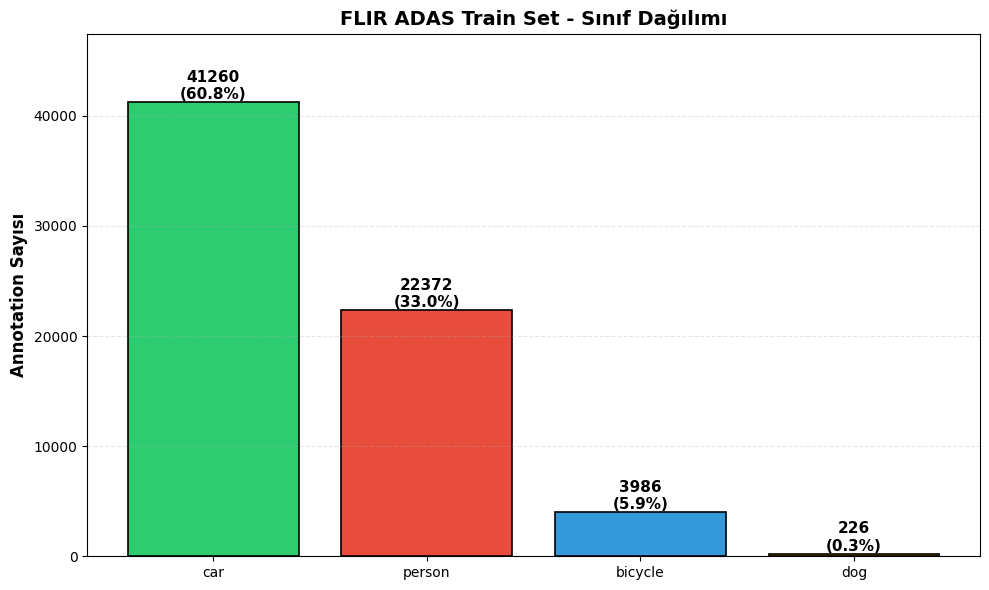

Dengesizlik Oranı (Car vs Dog): 182.6 kat fark var.


In [ ]:
import matplotlib.pyplot as plt

# Veriler
class_names = ['car', 'person', 'bicycle', 'dog']
class_counts = [41260, 22372, 3986, 226]
class_colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(class_names, class_counts, color=class_colors, edgecolor='black', linewidth=1.2)

# EN ONEMLI KISIM: Y eksenini en yuksek degerin %15 fazlasina ayarliyorum.
# Bu sayede tepedeki yazi cerceveye yapismaz, grafik ferahlar.
y_limit = max(class_counts) * 1.15
ax.set_ylim(0, y_limit)

# Cubuklarin uzerine yazi ekleme
for bar, count in zip(bars, class_counts):
    height = bar.get_height()
    percentage = (count / sum(class_counts)) * 100
    # Text konumunu bar'in biraz ustune koyuyorum
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{count}\n({percentage:.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Annotation Sayısı', fontsize=12, fontweight='bold')
ax.set_title('FLIR ADAS Train Set - Sınıf Dağılımı', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

# Hangi sinifin ne kadar az oldugunu loga da basiyorum
print(f"Dengesizlik Oranı (Car vs Dog): {class_counts[0]/class_counts[3]:.1f} kat fark var.")

Dengesizlik çok ciddi. Car tüm etiketlerin %60.8'i, dog ise sadece %0.3'ü. Car ile dog arasında 182 kat fark var.

- **Car (41,260):** Baskın sınıf. Model büyük ihtimalle en iyi bu sınıfı öğrenecek.
- **Person (22,372):** Car'ın yaklaşık yarısı, yine de yeterli miktarda.
- **Bicycle (3,986):** Azınlık sınıfı, performansın düşük kalmasını bekliyorum.
- **Dog (226):** Öğrenilmesi çok zor. Kayıp fonksiyonuna katkısı diğer sınıfların yanında neredeyse görünmez kalacak.

Bu tablo, sonraki bölümlerde dog ve bicycle için augmentation ve oversampling denememin çıkış noktası oldu.

### 3.4 Kutu boyutları ve en-boy oranları

Termal kameradan uzaktaki bir insan birkaç piksel genişliğinde görünüyor. Küçük nesnelerin ne kadar baskın olduğunu görmek için tüm kutuların alanını COCO'nun boyut tanımına göre gruplayacağım:

- Küçük: alan < 32² piksel
- Orta: 32² ile 96² arası
- Büyük: alan > 96² piksel

Ayrıca sınıf bazında en-boy oranına (genişlik / yükseklik) bakacağım. İnsanlar dar ve uzun, araçlar geniş olmalı.

In [ ]:
import json

# Dosya yolunu tanımlıyorum
ANNOTATION_PATH = "/content/drive/MyDrive/tez/data/train/thermal_annotations.json"

print("JSON dosyası yükleniyor, biraz zaman alabilir...")

# JSON dosyasını belleğe yüklüyorum
with open(ANNOTATION_PATH, 'r') as f:
    coco_data = json.load(f)

bbox_data = []

# Hedef sınıflarımız: İnsan(1), Bisiklet(2), Araba(3), Köpek(17)
target_ids = [1, 2, 3, 17]

print("Veriler ayıklanıyor ve hesaplamalar yapılıyor...")

for ann in coco_data['annotations']:
    cat_id = ann['category_id']

    # Sadece belirlediğimiz sınıfları filtreliyorum
    if cat_id in target_ids:
        x, y, w, h = ann['bbox']

        # Alan (Area) ve En-Boy Oranı (Aspect Ratio) hesaplıyorum
        area = w * h
        # Sıfıra bölme hatası olmasın diye kontrol ediyorum
        aspect_ratio = w / h if h > 0 else 0

        bbox_data.append({
            'category_id': cat_id,
            'width': w,
            'height': h,
            'area': area,
            'aspect_ratio': aspect_ratio
        })

print(f"\nİşlem Tamam! Toplam hedef bbox sayısı: {len(bbox_data)}")

# İlk 3 örneği ekrana basıp kontrol ediyorum (Sağlama yapıyorum)
print("\nÖrnek ilk 3 veri:")
for i in range(3):
    item = bbox_data[i]
    print(f"Sınıf: {item['category_id']} | Boyut: {item['width']:.1f}x{item['height']:.1f} | Alan: {item['area']:.0f} px² | Oran: {item['aspect_ratio']:.2f}")

JSON dosyası yükleniyor, biraz zaman alabilir...
Veriler ayıklanıyor ve hesaplamalar yapılıyor...

İşlem Tamam! Toplam hedef bbox sayısı: 67844

Örnek ilk 3 veri:
Sınıf: 3 | Boyut: 132.0x122.0 | Alan: 16104 px² | Oran: 1.08
Sınıf: 3 | Boyut: 88.0x77.0 | Alan: 6776 px² | Oran: 1.14
Sınıf: 3 | Boyut: 48.0x28.0 | Alan: 1344 px² | Oran: 1.71


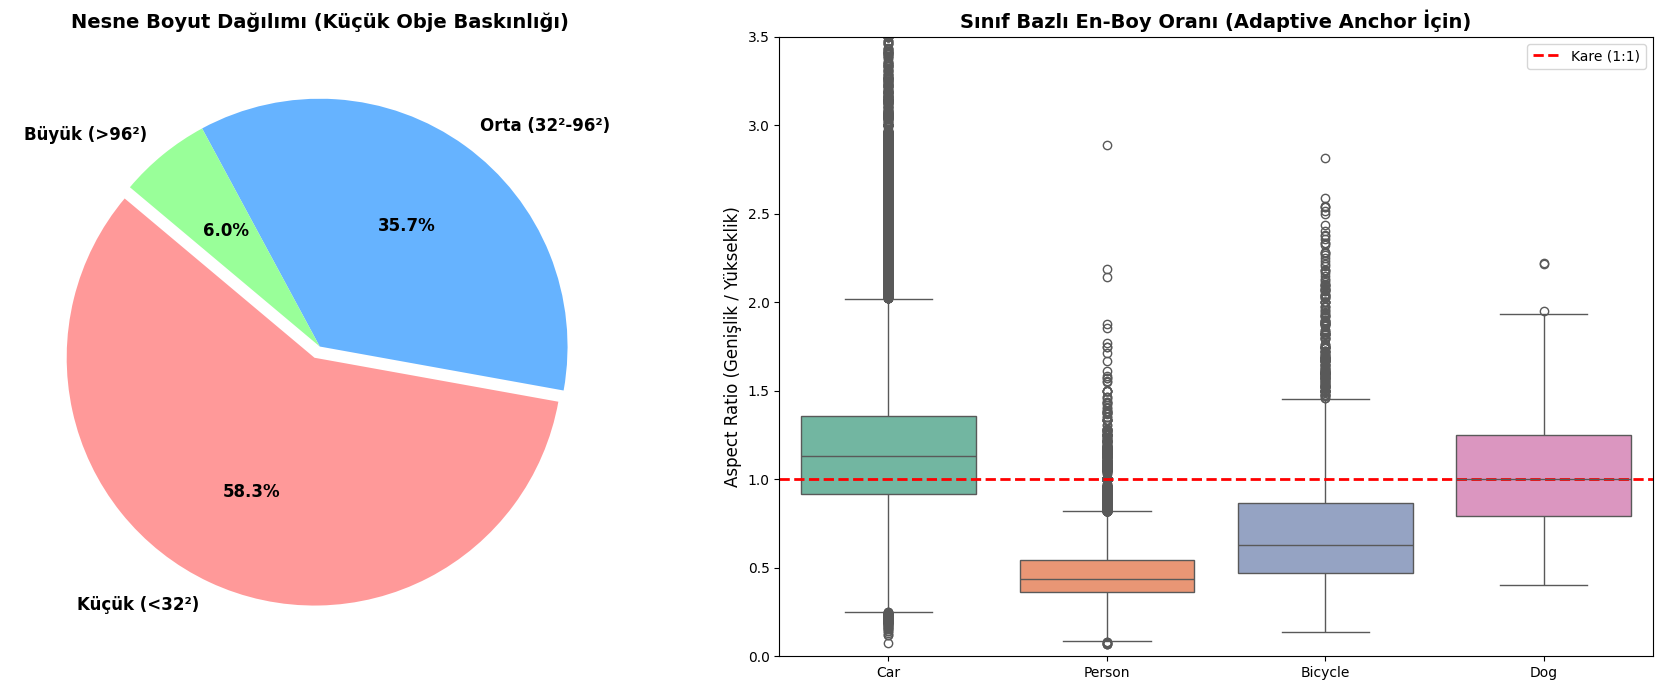

In [ ]:
import pandas as pd
import seaborn as sns

# Eğer bbox_data listesi hafızada yoksa önceki adımı çalıştırıp oluşturman lazım.
# Veriyi işlemek için Pandas DataFrame'e çeviriyorum
df = pd.DataFrame(bbox_data)

# Okunabilirlik için ID'leri isme çeviriyorum
id_map = {1: 'Person', 2: 'Bicycle', 3: 'Car', 17: 'Dog'}
df['class_name'] = df['category_id'].map(id_map)

# --- 1. Analiz: Nesne Boyutlandırma (COCO Standardı) ---
# Küçük: < 1024 px² (32x32)
# Orta: 1024 - 9216 px² (32x32 - 96x96)
# Büyük: > 9216 px² (96x96)

def get_size_category(area):
    if area < 1024: return 'Küçük (<32²)'
    elif area < 9216: return 'Orta (32²-96²)'
    else: return 'Büyük (>96²)'

df['size_cat'] = df['area'].apply(get_size_category)

# --- 2. Görselleştirme (Dashboard Yaklaşımı) ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# SOL GRAFİK: Boyut Dağılımı (Pie Chart) -> Baskınlığı görmek için
size_counts = df['size_cat'].value_counts()
# Renkler: Kırmızı (Küçük/Zor), Mavi (Orta), Yeşil (Büyük/Kolay)
colors = ['#ff9999', '#66b3ff', '#99ff99']

axes[0].pie(size_counts, labels=size_counts.index, autopct='%1.1f%%',
            startangle=140, colors=colors, explode=(0.05, 0, 0), # Küçük dilimi biraz ayırıp vurguluyorum
            textprops={'fontsize': 12, 'weight': 'bold'})
axes[0].set_title('Nesne Boyut Dağılımı (Küçük Obje Baskınlığı)', fontsize=14, fontweight='bold')

# SAĞ GRAFİK: En-Boy Oranı Analizi (Box Plot) -> Anchor ayarı için
sns.boxplot(x='class_name', y='aspect_ratio', hue='class_name', data=df, ax=axes[1], palette="Set2", legend=False)

# Referans Çizgisi: Kare (1.0)
axes[1].axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Kare (1:1)')
axes[1].set_ylim(0, 3.5) # Grafiği bozan aşırı uç değerleri kırpıyorum
axes[1].set_title('Sınıf Bazlı En-Boy Oranı (Adaptive Anchor İçin)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Aspect Ratio (Genişlik / Yükseklik)', fontsize=12)
axes[1].set_xlabel('')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

small_ratio = (len(df[df['size_cat'] == 'Küçük (<32²)']) / len(df)) * 100

**Boyut dağılımı:** Kutuların %58.3'ü küçük, %35.7'si orta, sadece %6.0'ı büyük. Küçük nesneler YOLO tarzı dedektörlerin en çok zorlandığı grup, çünkü ağın derin katmanlarına inildikçe çözünürlük düşüyor ve 20 piksellik bir insan birkaç hücreye sığıyor. Baseline modelin en çok hatayı burada yapacağını bekliyorum.

**En-boy oranları:**

| Sınıf | Medyan oran | Şekil |
|---|---:|---|
| Person | ~0.44 | Dar ve dikey |
| Bicycle | ~0.55 | Dar |
| Car | ~1.13 | Yatay |
| Dog | ~1.0 | Kareye yakın |

YOLO11 anchor-free bir mimari olduğu için eski YOLO sürümlerindeki gibi anchor'ları veri setine göre ayarlamam gerekmiyor, model kutu boyutunu doğrudan tahmin ediyor. Yine de bu tablo önemli: sınıflar arasındaki şekil farkı büyük ve küçük, dar bir insan kutusunda birkaç piksellik hata IoU'yu hızla düşürüyor. mAP@50-95'te person'ın car'dan geride kalmasını bekliyorum.

### 3.5 Sınıf bazlı istatistikler

In [ ]:
for cat_id, cat_name in id_map.items():
    class_df = df[df['category_id'] == cat_id]

    print(f"{cat_name}:")
    print(f"  Toplam: {len(class_df)} adet")
    print(f"  Ortalama Alan: {class_df['area'].mean():.1f} px²")
    print(f"  Ortalama Genislik: {class_df['width'].mean():.1f} px")
    print(f"  Ortalama Yukseklik: {class_df['height'].mean():.1f} px")
    print(f"  Ortalama Aspect Ratio: {class_df['aspect_ratio'].mean():.2f}")

    # Alan bazinda direkt hesapliyorum, string karsilastirmasi yapmiyorum
    small_count = len(class_df[class_df['area'] < 1024])
    small_pct = (small_count / len(class_df)) * 100
    print(f"  Kucuk Obje Sayisi: {small_count} ({small_pct:.1f}%)\n")

Person:
  Toplam: 22372 adet
  Ortalama Alan: 1305.4 px²
  Ortalama Genislik: 19.2 px
  Ortalama Yukseklik: 45.7 px
  Ortalama Aspect Ratio: 0.48
  Kucuk Obje Sayisi: 16300 (72.9%)

Bicycle:
  Toplam: 3986 adet
  Ortalama Alan: 1500.2 px²
  Ortalama Genislik: 28.4 px
  Ortalama Yukseklik: 41.9 px
  Ortalama Aspect Ratio: 0.72
  Kucuk Obje Sayisi: 2415 (60.6%)

Car:
  Toplam: 41260 adet
  Ortalama Alan: 3198.8 px²
  Ortalama Genislik: 48.0 px
  Ortalama Yukseklik: 42.0 px
  Ortalama Aspect Ratio: 1.19
  Kucuk Obje Sayisi: 20642 (50.0%)

Dog:
  Toplam: 226 adet
  Ortalama Alan: 936.1 px²
  Ortalama Genislik: 27.0 px
  Ortalama Yukseklik: 26.2 px
  Ortalama Aspect Ratio: 1.05
  Kucuk Obje Sayisi: 177 (78.3%)



Küçük nesne oranı her sınıfta yüksek ama özellikle dog (%78.3) ve person (%72.9) sınıflarında kritik. Dog sınıfı hem en az örneğe sahip hem de en küçük ortalama alana (936 px²). Yani bu sınıf iki ayrı zorluğu aynı anda taşıyor.

### 3.6 Görsel kontrol

Sayılar tamam ama etiketlerin gerçekten nesnelerin üzerine oturduğunu kendi gözümle görmek istedim. Rastgele 6 görüntüye JSON'daki kutuları çizdim.

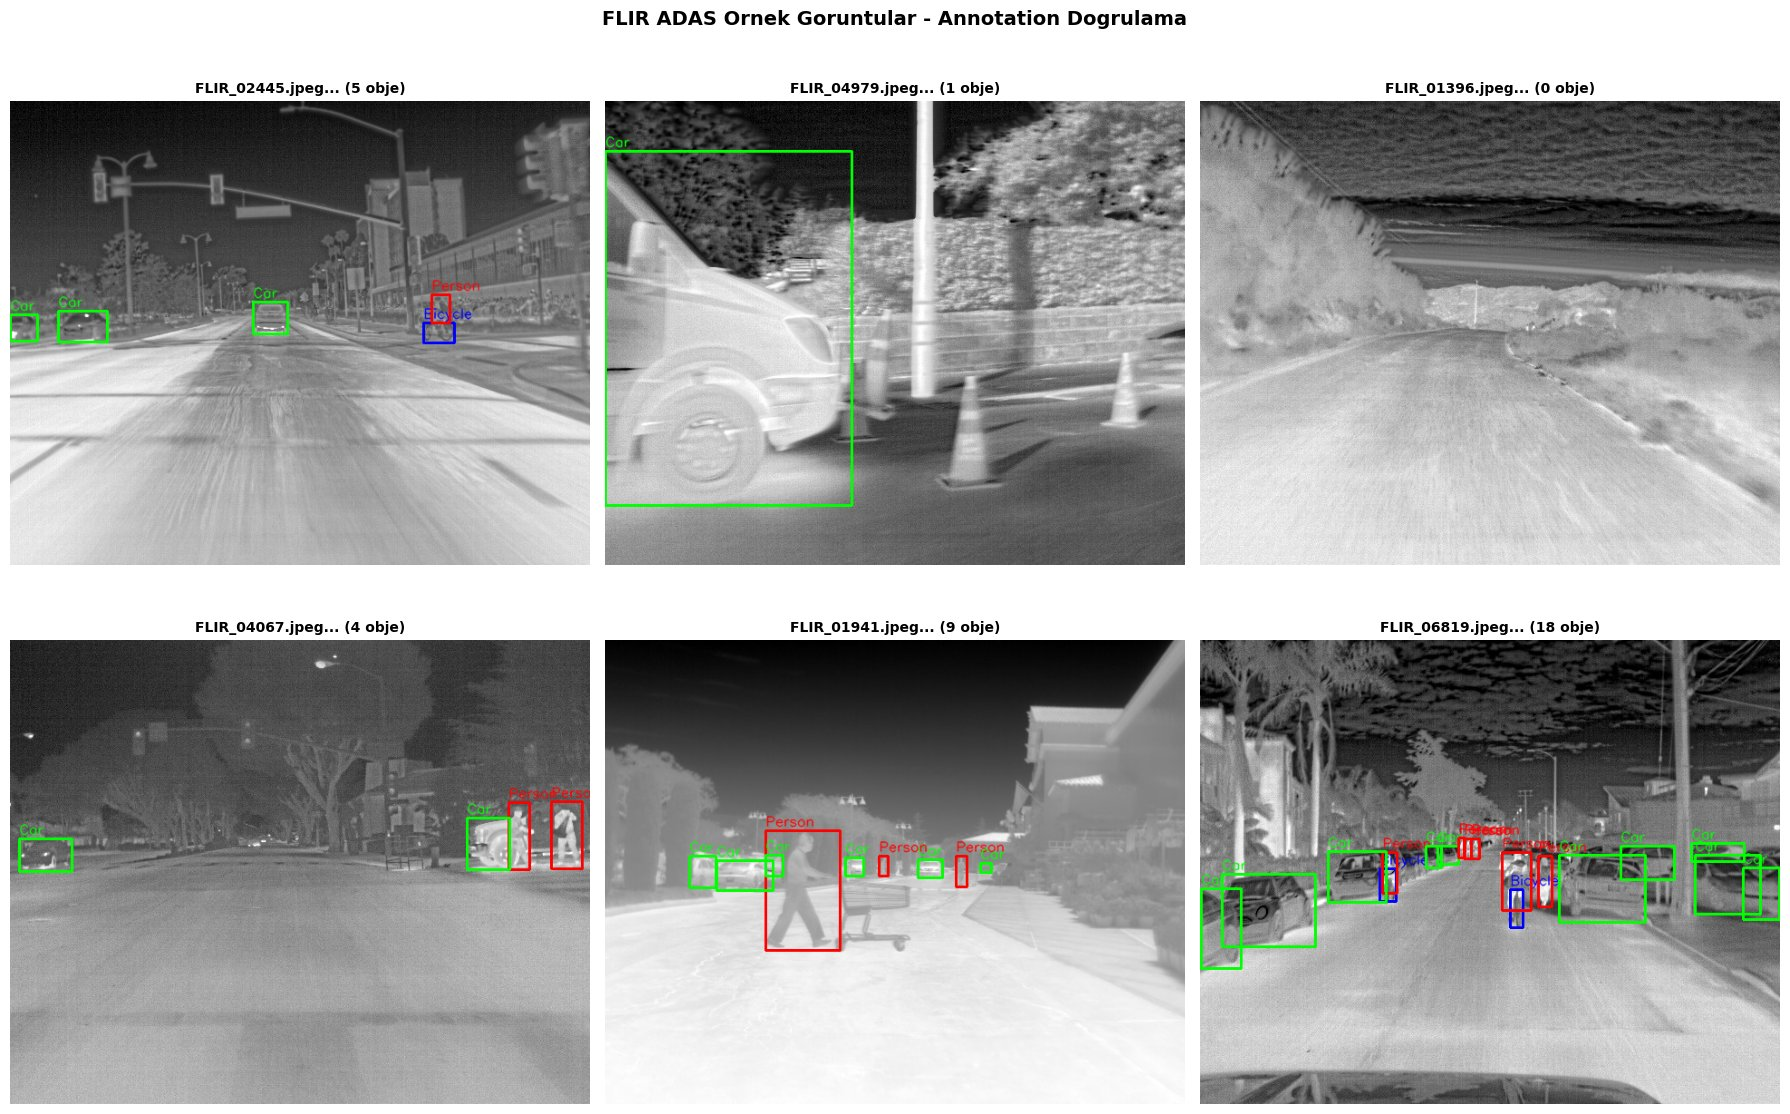

In [ ]:
selected_images = random.sample(list(coco_data['images']), 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

class_colors = {1: (255, 0, 0), 2: (0, 0, 255), 3: (0, 255, 0), 17: (255, 255, 0)}
class_names = {1: 'Person', 2: 'Bicycle', 3: 'Car', 17: 'Dog'}

valid_count = 0

for img_info in selected_images:
    if valid_count >= 6:
        break

    img_id = img_info['id']
    img_name = img_info['file_name'].split('/')[-1]
    img_path = f"{BASE_PATH}/thermal_8_bit/{img_name}"

    if not Path(img_path).exists():
        continue

    img = cv2.imread(img_path)
    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_anns = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]

    for ann in img_anns:
        cat_id = ann['category_id']
        if cat_id in [1, 2, 3, 17]:
            x, y, w, h = [int(v) for v in ann['bbox']]
            color = class_colors[cat_id]

            cv2.rectangle(img, (x, y), (x+w, y+h), color, 2)
            label = class_names[cat_id]
            cv2.putText(img, label, (x, y-5), cv2.FONT_HERSHEY_SIMPLEX,
                       0.5, color, 1, cv2.LINE_AA)

    axes[valid_count].imshow(img)
    axes[valid_count].set_title(f'{img_name[:15]}... ({len(img_anns)} obje)',
                                fontsize=10, fontweight='bold')
    axes[valid_count].axis('off')
    valid_count += 1

plt.suptitle('FLIR ADAS Ornek Goruntular - Annotation Dogrulama',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Kutular nesnelere sıkı oturuyor, README'deki "mümkün olduğunca dar kutu" kuralına uyulmuş. Etiket kalitesinde bir sorun görmedim.

## 4. YOLO Formatına Dönüşüm

Ultralytics her görüntü için ayrı bir `.txt` etiket dosyası bekliyor. Her satırda `sınıf x_merkez y_merkez genişlik yükseklik` var ve koordinatlar görüntü boyutuna göre 0-1 aralığına normalize edilmiş. COCO'da ise kutular `[x_sol, y_üst, genişlik, yükseklik]` olarak piksel cinsinden tutuluyor.

### 4.1 Yardımcı fonksiyonlar

İlk denememde her görüntü için tüm annotation listesini baştan tarıyordum ve dönüşüm saatler sürecekti. Etiketleri önce `image_id`'ye göre bir sözlükte grupladım, böylece her görüntünün etiketlerine doğrudan erişebiliyorum.

In [ ]:
from tqdm import tqdm

def build_annotation_index(annotations):
    # Her goruntu icin annotation'lari onceden grupluyorum
    # Boylece her seferinde tum listeyi taramak yerine O(1) hizda erisiyorum
    img_to_anns = {}

    for ann in annotations:
        # Sadece kullanacagim 4 sinifi aliyorum
        if ann['category_id'] in [1, 2, 3, 17]:
            img_id = ann['image_id']

            # Eger bu image_id ilk defa goruluyorsa bos liste olustur
            if img_id not in img_to_anns:
                img_to_anns[img_id] = []

            img_to_anns[img_id].append(ann)

    return img_to_anns


# FLIR kategori ID'lerinden YOLO sinif indekslerine (README dog icin 18 diyor ama JSON'da 17)
coco_to_yolo_class = {1: 0, 2: 1, 3: 2, 17: 3}

def coco_to_yolo(bbox, img_w, img_h):
    # COCO: [x_sol, y_ust, genislik, yukseklik] piksel
    # YOLO: [x_merkez, y_merkez, genislik, yukseklik] 0-1 araliginda
    x, y, w, h = bbox
    return (x + w / 2) / img_w, (y + h / 2) / img_h, w / img_w, h / img_h


### 4.2 Ana dönüşüm fonksiyonu

Etiketi olmayan görüntüler için de boş bir `.txt` oluşturuyorum. Bu görüntüler eğitimde arka plan örneği olarak kullanılıyor ve modelin boş sahnede nesne uydurmasını (false positive) azaltıyor.

In [ ]:
def convert_coco_to_yolo_optimized(json_path, output_dir, split_name):
    # JSON dosyasini yukluyorum
    with open(json_path, 'r') as f:
        data = json.load(f)

    # Annotation'lari image_id'ye gore indeksliyorum (hizlandirma icin)
    img_to_anns = build_annotation_index(data['annotations'])

    # Label dosyalarini kaydedecegim klasoru olusturuyorum
    label_dir = Path(f"{output_dir}/{split_name}/labels")
    label_dir.mkdir(parents=True, exist_ok=True)

    converted = 0
    empty = 0

    # Her goruntu icin label dosyasi olusturuyorum
    for img_info in tqdm(data['images'], desc=f"{split_name} donusuyor"):
        img_id = img_info['id']
        img_w = img_info['width']
        img_h = img_info['height']
        img_name = img_info['file_name'].split('/')[-1]

        # Label dosyasinin yolunu hazirliyorum
        label_file = label_dir / img_name.replace('.jpeg', '.txt')

        # Bu goruntunun annotation'larini O(1) hizinda aliyorum
        img_anns = img_to_anns.get(img_id, [])

        # Bos goruntu olsa bile txt dosyasi olusturuyorum (false positive icin)
        with open(label_file, 'w') as f:
            if len(img_anns) == 0:
                empty += 1
            else:
                # Her bbox'i YOLO formatina cevirip yaziyorum
                for ann in img_anns:
                    yolo_class = coco_to_yolo_class[ann['category_id']]
                    x_c, y_c, w_n, h_n = coco_to_yolo(ann['bbox'], img_w, img_h)
                    f.write(f"{yolo_class} {x_c:.6f} {y_c:.6f} {w_n:.6f} {h_n:.6f}\n")

        converted += 1

    print(f"{split_name}: {converted} label olusturuldu ({empty} bos)\n")

In [ ]:
# BASE_PATH'i dogru sekilde tanimliyorum
BASE_PATH = "/content/drive/MyDrive/tez/data"

# Kontrol ediyorum
train_json = f"{BASE_PATH}/train/thermal_annotations.json"
val_json = f"{BASE_PATH}/val/thermal_annotations.json"

print(f"BASE_PATH: {BASE_PATH}")
print(f"\nTrain JSON var mi? {Path(train_json).exists()}")
print(f"Val JSON var mi? {Path(val_json).exists()}")

BASE_PATH: /content/drive/MyDrive/tez/data

Train JSON var mi? True
Val JSON var mi? True


### 4.3 Train ve val dönüşümü

In [ ]:
# Train setini donusturuyorum
convert_coco_to_yolo_optimized(
    json_path=f"{BASE_PATH}/train/thermal_annotations.json",
    output_dir=BASE_PATH,
    split_name="train"
)

# Validation setini donusturuyorum
convert_coco_to_yolo_optimized(
    json_path=f"{BASE_PATH}/val/thermal_annotations.json",
    output_dir=BASE_PATH,
    split_name="val"
)

train donusuyor: 100%|██████████| 8862/8862 [00:42<00:00, 209.06it/s]


train: 8862 label olusturuldu (1002 bos)



val donusuyor: 100%|██████████| 1366/1366 [00:06<00:00, 204.17it/s]

val: 1366 label olusturuldu (6 bos)



Dönüşüm sorunsuz tamamlandı. Train için 8,862, val için 1,366 etiket dosyası oluştu. İndeksleme sayesinde işlem yaklaşık 50 saniye sürdü. Train'de 1,002, val'de 6 görüntünün hiç etiketi yok, bunlar arka plan örneği olarak kalıyor.

### 4.4 Dönüşümün doğrulanması (train)

Koordinat dönüşümünde yapılacak küçük bir hata (örneğin merkez yerine sol üst köşe kullanmak) tüm eğitimi boşa çıkarır. Bunu yakalamanın en kolay yolu YOLO dosyalarını tekrar piksele çevirip görüntünün üzerine çizmek.

In [ ]:
def parse_yolo_annotations(label_path, img_width, img_height):
    """Convert normalized YOLO coordinates to pixel space bounding boxes"""
    boxes = []

    with open(label_path, 'r') as f:
        for line in f:
            class_id, x_c, y_c, w, h = map(float, line.strip().split())

            x_center, y_center = int(x_c * img_width), int(y_c * img_height)
            box_w, box_h = int(w * img_width), int(h * img_height)

            x1 = int(x_center - box_w / 2)
            y1 = int(y_center - box_h / 2)
            x2 = int(x_center + box_w / 2)
            y2 = int(y_center + box_h / 2)

            boxes.append((int(class_id), (x1, y1, x2, y2)))

    return boxes

def render_detections(image, boxes, class_map, color_map):
    """Overlay bounding boxes and class labels on image"""
    for class_id, (x1, y1, x2, y2) in boxes:
        color = color_map[class_id]
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(image, class_map[class_id], (x1, y1-5),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
    return image

def find_image_file(img_dir, base_name):
    """Locate image file with either .jpeg or .jpg extension"""
    for ext in ['.jpeg', '.jpg']:
        candidate = Path(img_dir) / f"{base_name}{ext}"
        if candidate.exists():
            return candidate
    return None

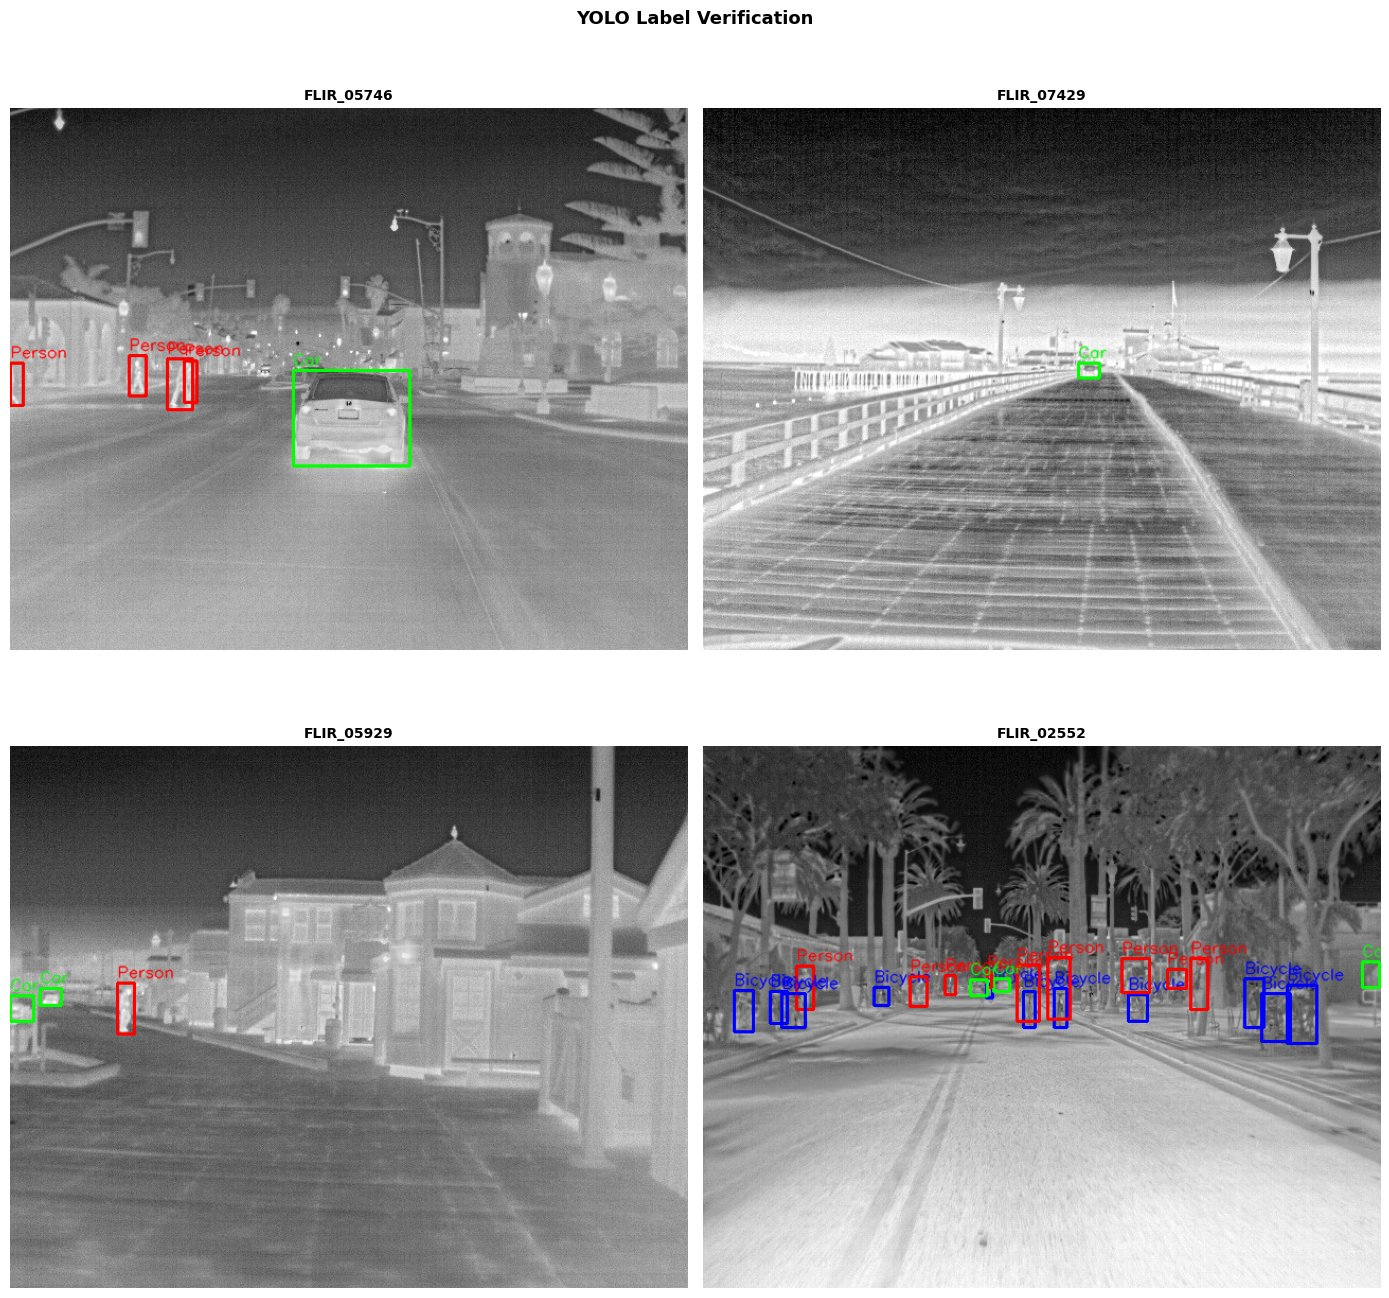

In [ ]:
IMG_DIR = f"{BASE_PATH}/train/thermal_8_bit"
LABEL_DIR = f"{BASE_PATH}/train/labels"
CLASS_MAP = {0: 'Person', 1: 'Bicycle', 2: 'Car', 3: 'Dog'}
COLOR_MAP = {0: (255,0,0), 1: (0,0,255), 2: (0,255,0), 3: (255,255,0)}

label_files = [f for f in Path(LABEL_DIR).glob("*.txt") if f.stat().st_size > 0]
samples = random.sample(label_files, 4)

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, label_path in enumerate(samples):
    img_path = find_image_file(IMG_DIR, label_path.stem)

    if img_path is None:
        continue

    img = cv2.imread(str(img_path))
    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    boxes = parse_yolo_annotations(label_path, w, h)
    img = render_detections(img, boxes, CLASS_MAP, COLOR_MAP)

    axes[idx].imshow(img)
    axes[idx].set_title(label_path.stem, fontsize=10, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('YOLO Label Verification', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Kutular doğru yerde. FLIR_02552 gibi kalabalık sahnelerde çok sayıda küçük kutu görülüyor, bu da 3.4'teki küçük nesne bulgusuyla uyumlu.

### 4.5 Dönüşümün doğrulanması (val)

Aynı kontrolü validation seti için de yaptım. İki split ayrı JSON dosyalarından geliyor, birinde doğru olan diğerinde de doğrudur diye varsaymak istemedim.

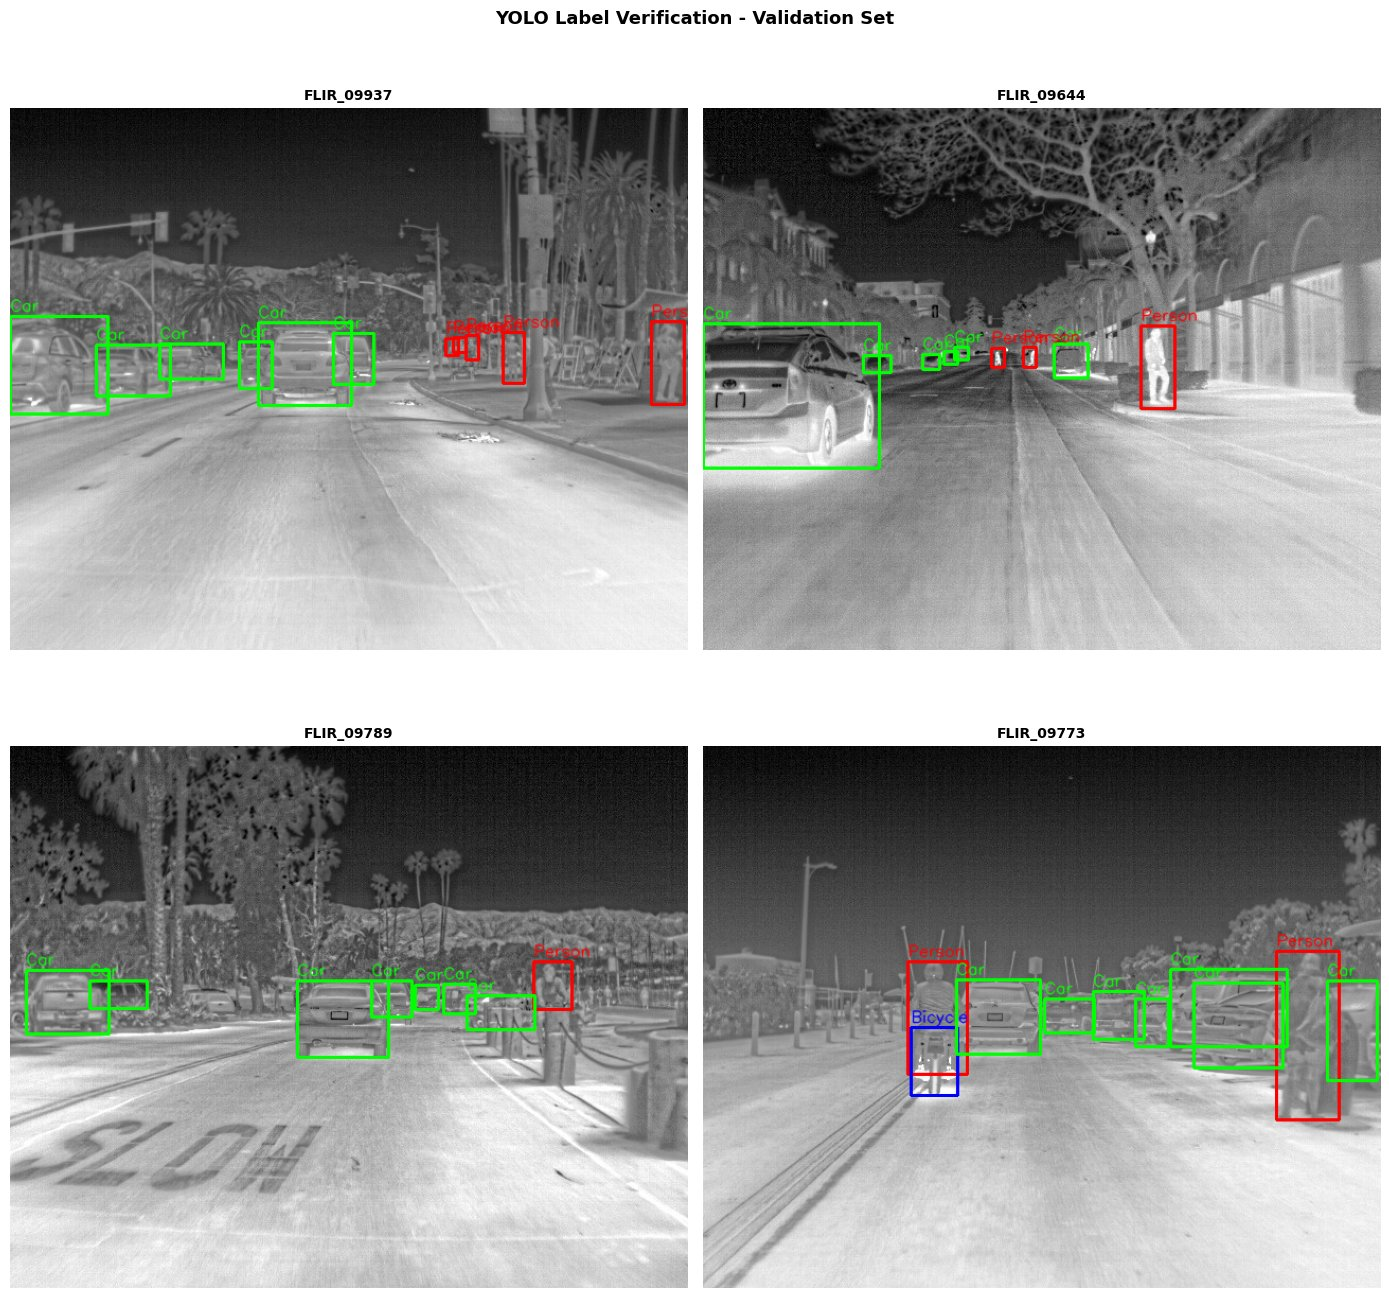

In [ ]:
# Validation setinden ornekler seciyorum
label_files_val = [f for f in Path(f"{BASE_PATH}/val/labels").glob("*.txt") if f.stat().st_size > 0]
samples_val = random.sample(label_files_val, 4)

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, label_path in enumerate(samples_val):
    img_path = find_image_file(f"{BASE_PATH}/val/thermal_8_bit", label_path.stem)

    if img_path is None:
        continue

    img = cv2.imread(str(img_path))
    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    boxes = parse_yolo_annotations(label_path, w, h)
    img = render_detections(img, boxes, CLASS_MAP, COLOR_MAP)

    axes[idx].imshow(img)
    axes[idx].set_title(label_path.stem, fontsize=10, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('YOLO Label Verification - Validation Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.6 Klasör yapısı ve data.yaml

Ultralytics, `images` klasörünün yanında `labels` adında bir klasör arıyor. FLIR'da görüntü klasörünün adı `thermal_8_bit` olduğu için ilk denemede model etiketleri bulamadı. Klasörleri yeniden adlandıran, eski cache dosyalarını temizleyen ve `data.yaml` dosyasını yazan bir fonksiyon hazırladım.

In [ ]:
!pip -q install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.7 MB/s eta 0:00:00


In [ ]:
import os
import shutil
import yaml
from pathlib import Path

# --- KONFIGURASYON ---
BASE_PATH = Path("/content/drive/MyDrive/tez/data")
SPLITS = ['train', 'val']

def standardize_dataset_structure(base_path, splits):
    """
    YOLOv11 egitimi icin klasor yapisini onarir, cache dosyalarini temizler
    ve data.yaml dosyasini gunceller.
    """
    print(f"[INFO] Veri seti onarim islemi baslatildi: {base_path}")

    for split in splits:
        split_dir = base_path / split

        # Hedeflenen klasor isimleri
        target_images_dir = split_dir / "images"
        old_source_dir = split_dir / "thermal_8_bit"
        labels_dir = split_dir / "labels"

        # 1. Sembolik Link Temizligi
        # Olası hatali sembolik linkleri kaldir
        if target_images_dir.is_symlink():
            target_images_dir.unlink()
            print(f"[INFO] {split}: Sembolik link temizlendi.")
        elif target_images_dir.exists() and not target_images_dir.is_dir():
            os.remove(target_images_dir)

        # 2. Klasor Isimlendirme (thermal_8_bit -> images)
        # YOLO standartlarina uyum icin isim degisikligi
        if old_source_dir.exists():
            old_source_dir.rename(target_images_dir)
            print(f"[INFO] {split}: Klasor ismi guncellendi (images).")

        # 3. Cache Temizligi
        # YOLO'nun hatali yollari unutmasi icin .cache dosyalari silinmeli
        cache_files = list(split_dir.rglob("*.cache"))
        for cache_file in cache_files:
            try:
                os.remove(cache_file)
                print(f"[INFO] {split}: Cache dosyasi silindi.")
            except OSError as e:
                print(f"[ERROR] Cache silinemedi: {e}")

        # 4. Label Kontrolu
        if labels_dir.exists():
            count = len(list(labels_dir.glob("*.txt")))
            if count == 0:
                print(f"[WARNING] {split}: Label klasoru bos!")
        else:
            print(f"[ERROR] {split}: Labels klasoru bulunamadi.")

    # 5. data.yaml Guncelleme
    # Mutlak yollar (absolute paths) kullanilarak hata riski sifirlanir
    yaml_config = {
        'path': str(base_path),
        'train': 'train/images',
        'val': 'val/images',
        'nc': 4,
        'names': ['Person', 'Bicycle', 'Car', 'Dog']
    }

    yaml_path = base_path / "thermal_dataset.yaml"
    try:
        with open(yaml_path, 'w') as f:
            yaml.dump(yaml_config, f, sort_keys=False, default_flow_style=False)
        print(f"[INFO] data.yaml basariyla guncellendi.")
    except Exception as e:
        print(f"[ERROR] data.yaml olusturulurken hata: {e}")

    print("[INFO] Islem tamamlandi. Egitime hazir.")

# --- ISLEMI BASLAT ---
if __name__ == "__main__":
    if BASE_PATH.exists():
        standardize_dataset_structure(BASE_PATH, SPLITS)
    else:
        print(f"[ERROR] Ana dizin bulunamadi: {BASE_PATH}")

[INFO] Veri seti onarim islemi baslatildi: /content/drive/MyDrive/tez/data
[INFO] train: Sembolik link temizlendi.
[INFO] train: Klasor ismi guncellendi (images).
[INFO] train: Cache dosyasi silindi.
[INFO] val: Sembolik link temizlendi.
[INFO] val: Klasor ismi guncellendi (images).
[INFO] val: Cache dosyasi silindi.
[INFO] data.yaml basariyla guncellendi.
[INFO] Islem tamamlandi. Egitime hazir.


Son durumda klasör yapısı şöyle:

```
data/
├── train/
│   ├── images/   (eski adı thermal_8_bit)
│   └── labels/
├── val/
│   ├── images/
│   └── labels/
└── thermal_dataset.yaml
```

## 5. V1: Baseline Model (YOLO11n)

### 5.1 Eğitim

İlk modeli bilerek hiçbir özel ayar yapmadan eğittim. Amacım iyileştirme denemelerini karşılaştıracağım bir referans noktası elde etmekti. COCO üzerinde önceden eğitilmiş en küçük model olan YOLO11n'yi (2.6M parametre) seçtim.

| Parametre | Değer |
|---|---|
| Model | yolo11n.pt |
| Epoch | 50 (patience 10) |
| Batch | 32 |
| Görüntü boyutu | 640 |
| Augmentation | Ultralytics varsayılanları (mosaic, flip, HSV) |

In [ ]:
from ultralytics import YOLO
from pathlib import Path

# Önceki hücredeki BASE_PATH'i kullanarak runs dizinini ayarla
# data klasörünün bir üstüne çıkıp runs klasörü oluşturur
runs_dir = Path(BASE_PATH).parent / "runs"
runs_dir.mkdir(parents=True, exist_ok=True)

model = YOLO('yolo11n.pt')

training_args = {
    'data': str(Path(BASE_PATH) / "thermal_dataset.yaml"),
    'epochs': 50,
    'batch': 32,
    'imgsz': 640,
    'project': str(runs_dir),
    'name': 'baseline_yolo11n',
    'patience': 10,
    'save': True,
    'save_period': 5,
    'device': 0,
    'workers': 8,
    'exist_ok': True,
    'cache': True,
    'verbose': True
}

print("Eğitim parametreleri:")
for key, val in training_args.items():
    print(f"  {key}: {val}")
print("\nEğitim başlatılıyor...\n")

results = model.train(**training_args)

Eğitim parametreleri:
  data: /content/drive/MyDrive/tez/data/thermal_dataset.yaml
  epochs: 50
  batch: 32
  imgsz: 640
  project: /content/drive/MyDrive/tez/runs
  name: baseline_yolo11n
  patience: 10
  save: True
  save_period: 5
  device: 0
  workers: 8
  exist_ok: True
  cache: True
  verbose: True

Eğitim başlatılıyor...

Ultralytics 8.3.239 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/tez/data/thermal_dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, 

### 5.2 Modelin yüklenmesi

Eğitim uzun sürdüğü için Colab oturumu arada yenilendi, kütüphaneleri ve en iyi ağırlıkları tekrar yüklüyorum.

In [ ]:
# kütüphaneleri tekrar import ediyorum çünkü tüm satırları en baştan çalıştıramam
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ultralytics import YOLO

# Model ve sonuc dosyalarinin yollarini tanimliyorum
BASE_PATH = Path("/content/drive/MyDrive/tez/data")
RUNS_DIR = Path("/content/drive/MyDrive/tez/runs/baseline_yolo11n")

# En iyi modeli yukluyorum (12. epoch)
model = YOLO(str(RUNS_DIR / "weights/best.pt"))

print(f"Model yuklendi: {RUNS_DIR / 'weights/best.pt'}")
print(f"Model metrikleri: {RUNS_DIR}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Model yuklendi: /content/drive/MyDrive/tez/runs/baseline_yolo11n/weights/best.pt
Model metrikleri: /content/drive/MyDrive/tez/runs/baseline_yolo11n


### 5.3 Eğitim metrikleri

In [ ]:
results_csv = RUNS_DIR / "results.csv"

if results_csv.exists():
    df_metrics = pd.read_csv(results_csv)
    # Sütun isimlerindeki boşlukları temizle
    df_metrics.columns = df_metrics.columns.str.strip()

    # Başlık ve Genel Bilgi
    print("-" * 80)
    print(f"EĞİTİM ÖZETİ | Toplam Epoch Sayısı: {len(df_metrics)}")
    print("-" * 80)

    # Metrik Listesi
    print("Mevcut Metrikler:")
    print(", ".join(df_metrics.columns.tolist()))
    print("-" * 80)

    # İlk 5 Satır (Tablo Formatında)
    print("\nİlk 5 Epoch Verisi:")

    # Sayıları virgülden sonra 4 basamak olacak şekilde formatla
    format_mapping = {col: "{:.4f}".format for col in df_metrics.select_dtypes(include='float').columns}

    # İndex olmadan, hizalı tablo bas
    print(df_metrics.head().to_string(index=False, formatters=format_mapping))

--------------------------------------------------------------------------------
EĞİTİM ÖZETİ | Toplam Epoch Sayısı: 22
--------------------------------------------------------------------------------
Mevcut Metrikler:
epoch, time, train/box_loss, train/cls_loss, train/dfl_loss, metrics/precision(B), metrics/recall(B), metrics/mAP50(B), metrics/mAP50-95(B), val/box_loss, val/cls_loss, val/dfl_loss, lr/pg0, lr/pg1, lr/pg2
--------------------------------------------------------------------------------

İlk 5 Epoch Verisi:
 epoch     time train/box_loss train/cls_loss train/dfl_loss metrics/precision(B) metrics/recall(B) metrics/mAP50(B) metrics/mAP50-95(B) val/box_loss val/cls_loss val/dfl_loss lr/pg0 lr/pg1 lr/pg2
     1 108.2280         1.6408         1.8721         1.1512               0.7333            0.3638           0.4009              0.2063       1.5892       1.2461       1.1594 0.0004 0.0004 0.0004
     2 202.9270         1.5378         1.1395         1.1187               0.77

Model 22 epoch eğitildi. Ultralytics en iyi modeli mAP@50 ve mAP@50-95'in ağırlıklı birleşimine göre seçiyor ve bu ölçüte göre en iyi epoch 12 oldu. Sonraki 10 epoch'ta iyileşme olmayınca eğitim erken durdu.

İlk 5 epoch'a bakınca:

- **Loss:** Box loss 1.64'ten 1.48'e, classification loss 1.87'den 0.95'e indi. Classification loss'taki hızlı düşüş, COCO'dan gelen önceden eğitilmiş ağırlıkların termal görüntülere de büyük ölçüde aktarılabildiğini gösteriyor.
- **mAP@50:** İlk epoch'ta 0.40'tan 5. epoch'ta 0.50'ye çıktı. Artış düzgün değil, 3. ve 5. epoch'larda küçük düşüşler var.
- **Validation loss:** 1.59'dan 1.52'ye indi, train loss ile birlikte hareket ediyor. Ezberleme belirtisi yok.
- **Learning rate:** İlk epoch'larda warmup nedeniyle yükseliyor.

### 5.4 Loss ve mAP eğrileri

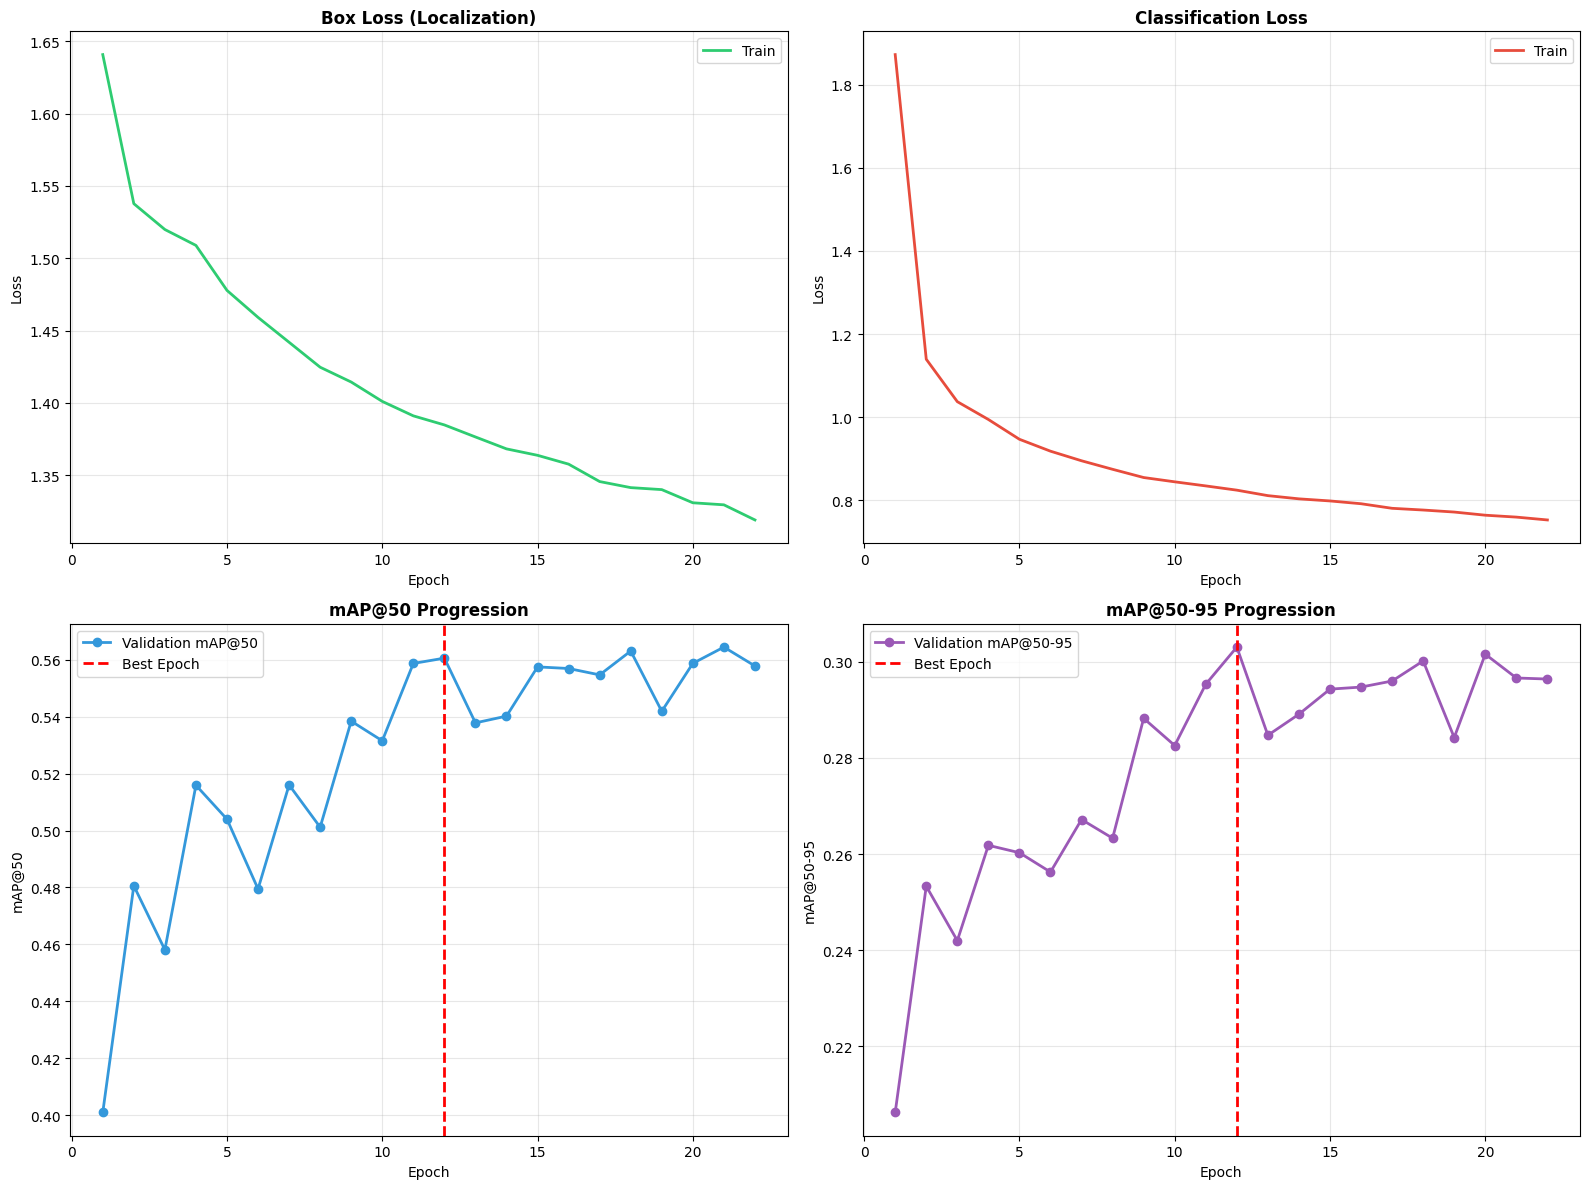

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Box Loss
axes[0, 0].plot(df_metrics['epoch'], df_metrics['train/box_loss'],
               label='Train', linewidth=2, color='#2ecc71')
axes[0, 0].set_title('Box Loss (Localization)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Classification Loss
axes[0, 1].plot(df_metrics['epoch'], df_metrics['train/cls_loss'],
               label='Train', linewidth=2, color='#e74c3c')
axes[0, 1].set_title('Classification Loss', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# mAP@50
axes[1, 0].plot(df_metrics['epoch'], df_metrics['metrics/mAP50(B)'],
               label='Validation mAP@50', linewidth=2, color='#3498db', marker='o')
axes[1, 0].axvline(x=12, color='red', linestyle='--', linewidth=2, label='Best Epoch')
axes[1, 0].set_title('mAP@50 Progression', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('mAP@50')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# mAP@50-95
axes[1, 1].plot(df_metrics['epoch'], df_metrics['metrics/mAP50-95(B)'],
               label='Validation mAP@50-95', linewidth=2, color='#9b59b6', marker='o')
axes[1, 1].axvline(x=12, color='red', linestyle='--', linewidth=2, label='Best Epoch')
axes[1, 1].set_title('mAP@50-95 Progression', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('mAP@50-95')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Box loss:** İlk 10 epoch'ta 1.64'ten 1.40'a hızlı bir düşüş var, sonra yavaşlayarak 22. epoch'ta 1.32'ye iniyor. Eğri düzgün ve sürekli azalıyor.

**Classification loss:** 1.87'den 0.76'ya iniyor. İlk 5 epoch'taki düşüş çok sert, sonrası daha sakin. Yalnız bu düşüşün büyük kısmı car ve person'dan geliyor olabilir, çünkü loss'u bu iki sınıf domine ediyor.

**mAP@50:** En önemli grafik bu. İlk 12 epoch'ta 0.40'tan 0.56'ya çıkıyor, sonra 0.54-0.56 bandında gidip geliyor ve 0.57'yi geçemiyor. Loss inmeye devam ederken validation performansının yerinde sayması modelin kapasitesinin sınırına geldiğini düşündürüyor.

**mAP@50-95:** Daha sıkı bir metrik (IoU eşiği 0.5'ten 0.95'e kadar). 12. epoch'ta 0.30 ile zirve yapıyor. Dalgalanma burada daha belirgin, yani model nesneyi bulsa da kutuyu tam oturtmakta zorlanıyor.

Özetle eğitim sağlıklı ama model 0.56 civarında bir tavana çarpmış durumda. Dog sınıfının AP'si 0.0005, yani sıfır. Bu, diğer üç sınıfın ortalaması içinde kaybolduğu için eğrilerde görünmüyor.

### 5.5 Sınıf bazlı performans

Genel mAP dört sınıfın ortalaması olduğu için tek başına yanıltıcı olabilir. Her sınıfa ayrı ayrı baktım.

In [ ]:
# Validation sonuçlarından sınıf bazlı metrikleri çekiyorum
val_results = model.val()

class_names = ['Person', 'Bicycle', 'Car', 'Dog']
class_metrics = {
    'Class': class_names,
    'Precision': [],
    'Recall': [],
    'mAP@50': [],
    'mAP@50-95': []
}

# Her sınıf için metrikleri topluyorum
for idx, class_name in enumerate(class_names):
    class_metrics['Precision'].append(val_results.box.p[idx])
    class_metrics['Recall'].append(val_results.box.r[idx])
    class_metrics['mAP@50'].append(val_results.box.ap50[idx])
    class_metrics['mAP@50-95'].append(val_results.box.ap[idx])

df_class = pd.DataFrame(class_metrics)

print("=" * 70)
print("SINIF BAZLI PERFORMANS ANALİZİ")
print("=" * 70)
for idx, row in df_class.iterrows():
    print(f"\n{row['Class']:10s} | P: {row['Precision']:.3f} | R: {row['Recall']:.3f} | "
          f"mAP@50: {row['mAP@50']:.3f} | mAP@50-95: {row['mAP@50-95']:.3f}")

Ultralytics 8.3.239 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 57.3±17.3 MB/s, size: 108.8 KB)
val: Scanning /content/drive/MyDrive/tez/data/val/labels.cache... 1366 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1366/1366 1.8Mit/s 0.0s
val: /content/drive/MyDrive/tez/data/val/images/FLIR_09042.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val/images/FLIR_09055.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val/images/FLIR_09653.jpeg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 86/86 7.4it/s 11.6s
                   all       1366      11693      0.569      0.512      0.562      0.303
                Person       1206       5778        0.8      0.697      0.798      0.412
               Bicycle        338        470      0.669      0.519      0.567      0.224
                 

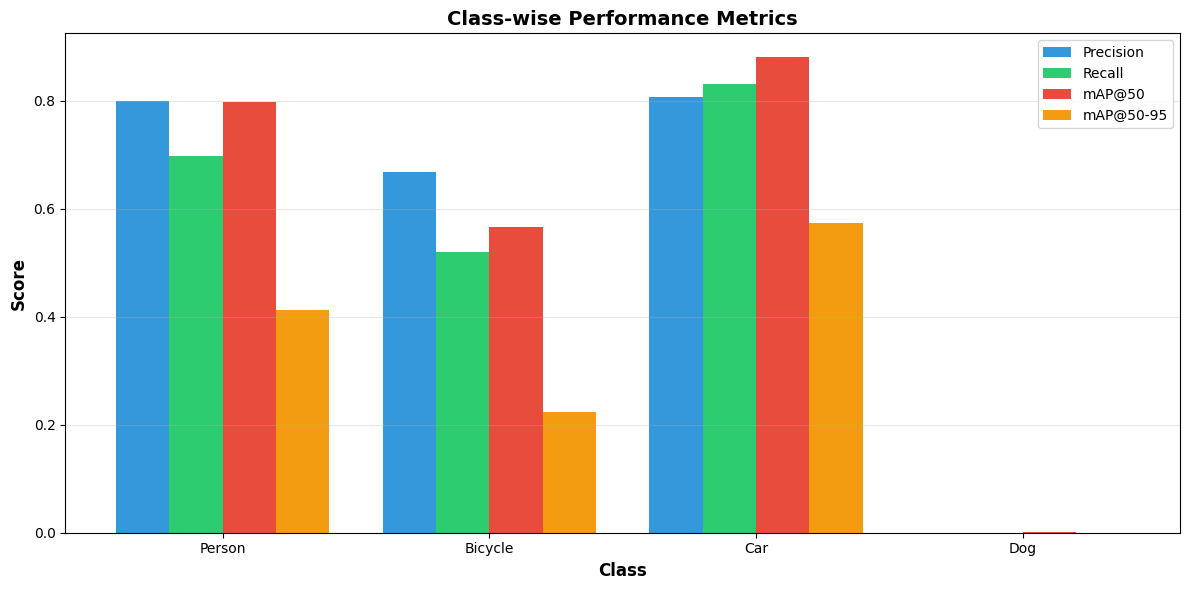

In [ ]:
# Görselleştirme
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(class_names))
width = 0.2

bars1 = ax.bar(x - 1.5*width, df_class['Precision'], width, label='Precision', color='#3498db')
bars2 = ax.bar(x - 0.5*width, df_class['Recall'], width, label='Recall', color='#2ecc71')
bars3 = ax.bar(x + 0.5*width, df_class['mAP@50'], width, label='mAP@50', color='#e74c3c')
bars4 = ax.bar(x + 1.5*width, df_class['mAP@50-95'], width, label='mAP@50-95', color='#f39c12')

ax.set_xlabel('Class', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Class-wise Performance Metrics', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Sınıf bazında tablo şöyle:

| Sınıf | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---:|---:|---:|---:|
| Car | 0.808 | 0.830 | 0.881 | 0.575 |
| Person | 0.800 | 0.697 | 0.798 | 0.412 |
| Bicycle | 0.669 | 0.519 | 0.567 | 0.224 |
| Dog | 0.000 | 0.000 | 0.000 | 0.000 |

**Car** en iyi sınıf. Hem az kaçırıyor hem az yanlış alarm veriyor. Verinin %60'ı car, kutular görece büyük ve şekil olarak standart.

**Person** precision açısından iyi ama recall 0.70'te kalıyor, yani her 10 kişiden 3'ü kaçırılıyor. Person kutularının %72.9'unun küçük olduğunu düşünürsek kaçırılanların çoğunun uzaktaki insanlar olması beklenir. mAP@50-95'in 0.41'e düşmesi de kutuların tam oturmadığını gösteriyor.

**Bicycle** hem precision hem recall tarafında zayıf. Az örnek (3,986), dar en-boy oranı ve bisikletlinin ayrıca person olarak etiketlenmesi bu sınıfı zorlaştırıyor.

**Dog** sınıfında tüm metrikler sıfır. 226 örnek modelin bu sınıfı öğrenmesine yetmemiş. Ancak 5.7'deki görsellerde görüleceği gibi model köpeklerin yakınına "dog" kutusu çizebiliyor. Sorun kutuların gerçek köpekle yeterince örtüşmemesi.

Baseline dominant sınıflarda iyi, azınlık sınıflarında yetersiz. Bu, 3. bölümdeki veri analizinden beklediğim tabloyla birebir örtüşüyor.

### 5.6 Confusion matrix

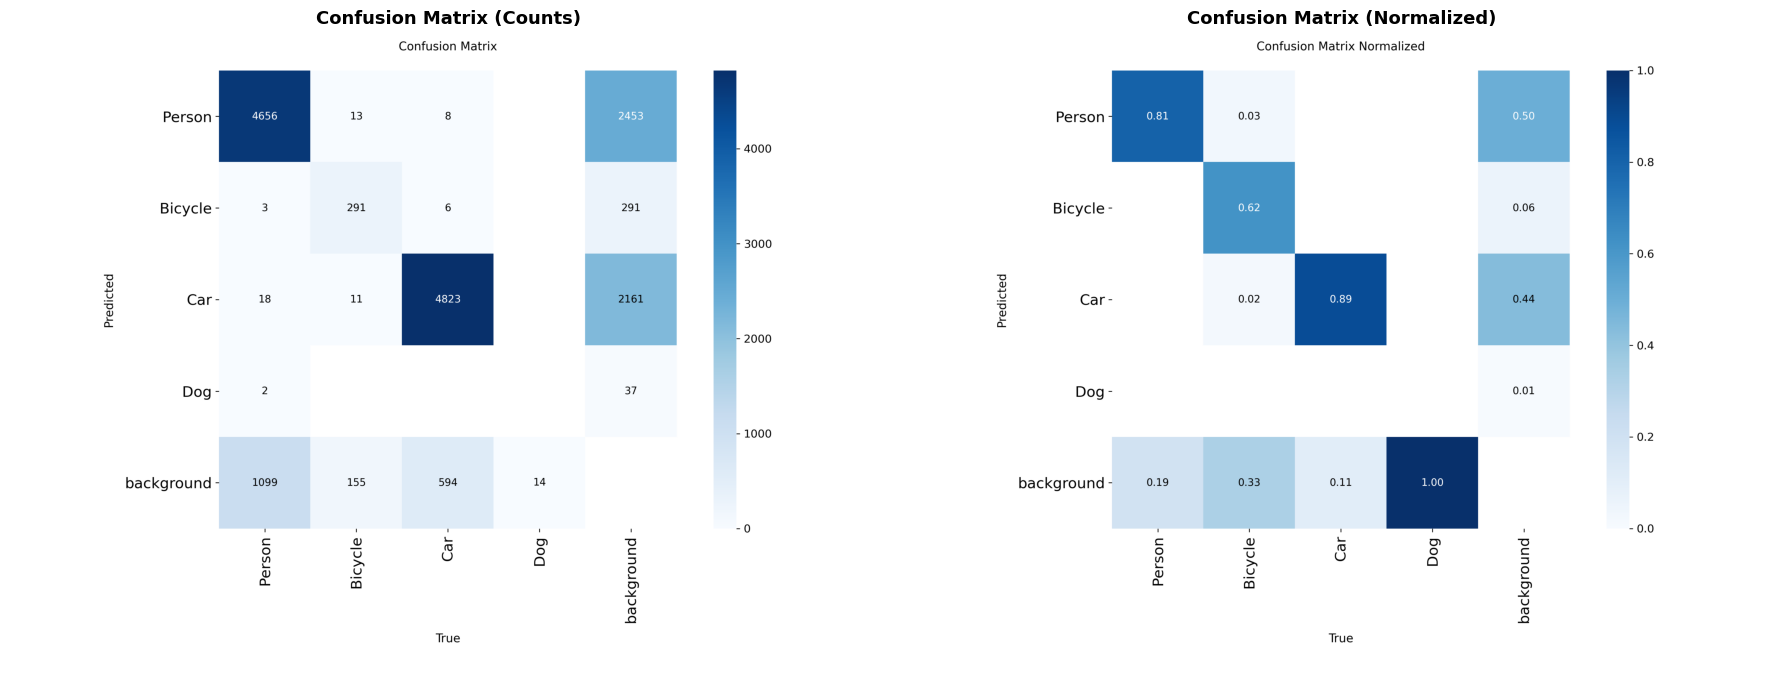

In [ ]:
from PIL import Image

# YOLO'nun otomatik olusturduğu confusion matrix'leri gösteriyorum
conf_matrix_path = RUNS_DIR / "confusion_matrix.png"
conf_matrix_norm_path = RUNS_DIR / "confusion_matrix_normalized.png"

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Normal confusion matrix
if conf_matrix_path.exists():
    img1 = Image.open(conf_matrix_path)
    axes[0].imshow(img1)
    axes[0].set_title('Confusion Matrix (Counts)', fontsize=13, fontweight='bold')
    axes[0].axis('off')
else:
    axes[0].text(0.5, 0.5, 'Matrix bulunamadi', ha='center', va='center')
    axes[0].axis('off')

# Normalized confusion matrix
if conf_matrix_norm_path.exists():
    img2 = Image.open(conf_matrix_norm_path)
    axes[1].imshow(img2)
    axes[1].set_title('Confusion Matrix (Normalized)', fontsize=13, fontweight='bold')
    axes[1].axis('off')
else:
    axes[1].text(0.5, 0.5, 'Normalized matrix bulunamadi', ha='center', va='center')
    axes[1].axis('off')

plt.tight_layout()
plt.show()

Person sınıfında doğru tespit oranı fena değil ama gerçek person'ların önemli bir kısmı hiç tespit edilmemiş ve background sütununa düşmüş. Bicycle'da bu kaçırma oranı daha da yüksek. Car en iyi öğrenilen sınıf, yine de veri çok olduğu için kaçırılan car sayısı mutlak olarak yüksek. Dog'da gerçek köpeklerin neredeyse tamamı background'a gitmiş.

Background satırına bakınca model, gerçekte nesne olmayan yerlerde de person, bicycle ve car tahmini üretiyor. Yani iki tür hata birlikte var: nesneyi kaçırmak (false negative) ve olmayan nesne görmek (false positive). İlki recall'u, ikincisi precision'ı düşürüyor. Sayılara bakınca kaçırma tarafı daha baskın.

Bir not: Nesne tespitinde background gerçek bir sınıf değil, "eşleşmeyen kutu" anlamına geliyor. Bu yüzden normalize matriste bazı sütunların toplamı 1'i geçebiliyor.

### 5.7 Validation tahminleri

Metriklerin görselde neye karşılık geldiğini görmek için validation setinden 12 kare seçip modelin tahminlerini çizdim (conf > 0.25).

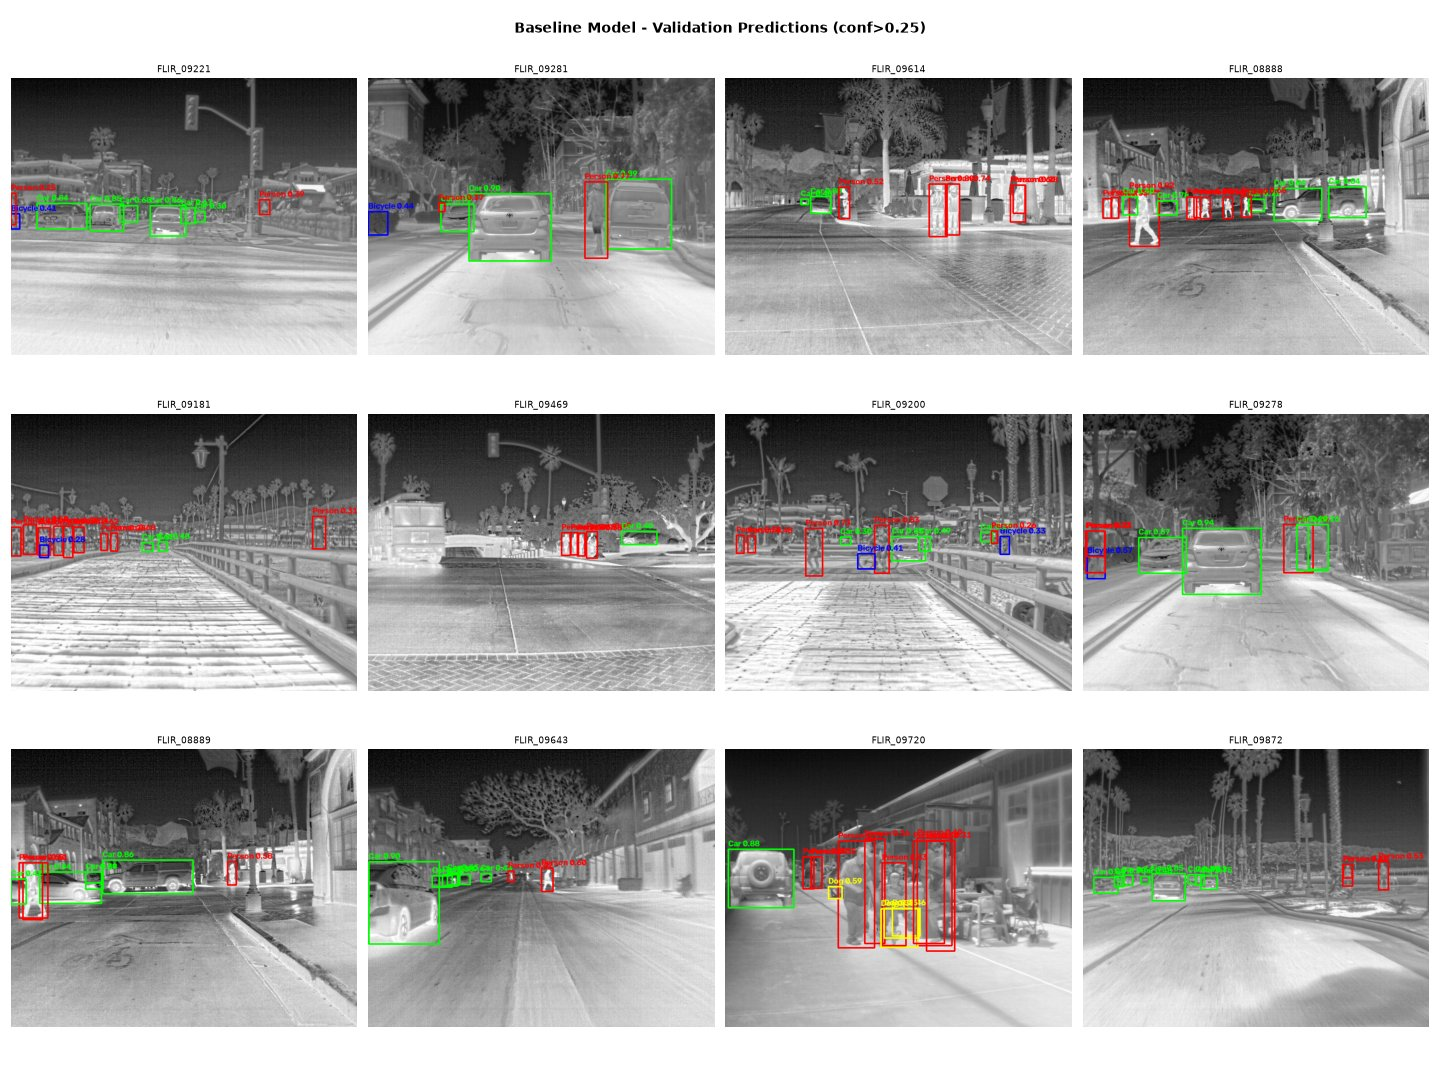

In [ ]:
import random

# Validation setinden rastgele görüntüler seciyorum
val_img_dir = BASE_PATH / "val/images"
val_images = list(val_img_dir.glob("*.jpeg"))
selected = random.sample(val_images, 12)

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

class_names = ['Person', 'Bicycle', 'Car', 'Dog']
class_colors = [(255, 0, 0), (0, 0, 255), (0, 255, 0), (255, 255, 0)]

for idx, img_path in enumerate(selected):
    # Görüntüyü okuyorum
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Model inference yapiyorum
    results = model.predict(str(img_path), conf=0.25, verbose=False)

    # Tahminleri ciziyorum
    for result in results:
        boxes = result.boxes
        for box in boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
            conf = box.conf[0].cpu().numpy()
            cls = int(box.cls[0].cpu().numpy())

            color = class_colors[cls]
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

            label = f'{class_names[cls]} {conf:.2f}'
            cv2.putText(img, label, (x1, y1-5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    axes[idx].imshow(img)
    axes[idx].set_title(img_path.stem, fontsize=9)
    axes[idx].axis('off')

plt.suptitle('Baseline Model - Validation Predictions (conf>0.25)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Car (yeşil):** Neredeyse her karede doğru. Uzaktaki araçları bile yakalıyor (FLIR_09221, FLIR_09643, FLIR_09872) ve yakındaki araçlarda confidence 0.85'in üzerinde.

**Person (kırmızı):** Çoğu karede tespit var ama sorunlar da var:

- FLIR_09614 ve FLIR_09200'de birbirine yakın duran insanlar ayrılamıyor, kutular üst üste biniyor.
- FLIR_08888 ve FLIR_09181'de uzaktaki küçük insanlar yakalanmış ama confidence düşük.
- FLIR_09720'deki kalabalıkta aynı kişi için birden fazla kutu çizilmiş.

**Bicycle (mavi):** Sadece birkaç karede ve düşük confidence ile görünüyor (FLIR_09200, FLIR_09278, FLIR_09221). Sayısal sonuçlardaki düşük recall burada da görülüyor.

**Dog (sarı):** FLIR_09720'de gerçekten bir köpek var ve model o bölgeye dört ayrı "dog" kutusu çiziyor (en yüksek confidence 0.59). Ama bu kutuların hiçbiri köpeğin gerçek kutusuyla yeterince örtüşmüyor. Etiketle karşılaştırdığımda en iyi kutunun IoU değeri yaklaşık 0.24 çıktı, mAP@50'nin istediği 0.5'in çok altında. Yani model köpeği tamamen görmezden gelmiyor. Bir şey olduğunu fark ediyor ama yerini doğru bulamıyor. Bu yüzden AP sıfır çıkıyor.

Genel olarak gördüğüm sorunlar:

- **Kalabalık sahneler:** Üst üste binen nesneler ayrılamıyor.
- **Küçük nesneler:** Uzaktaki insanlar düşük confidence ile tespit ediliyor.
- **Tekrarlı kutular:** Kalabalıkta aynı kişiye birden fazla kutu düşebiliyor.

Görseller sayısal sonuçları doğruluyor: car çok iyi, person orta, bicycle zayıf, dog başarısız.

### 5.8 Precision-Recall ve F1 eğrileri

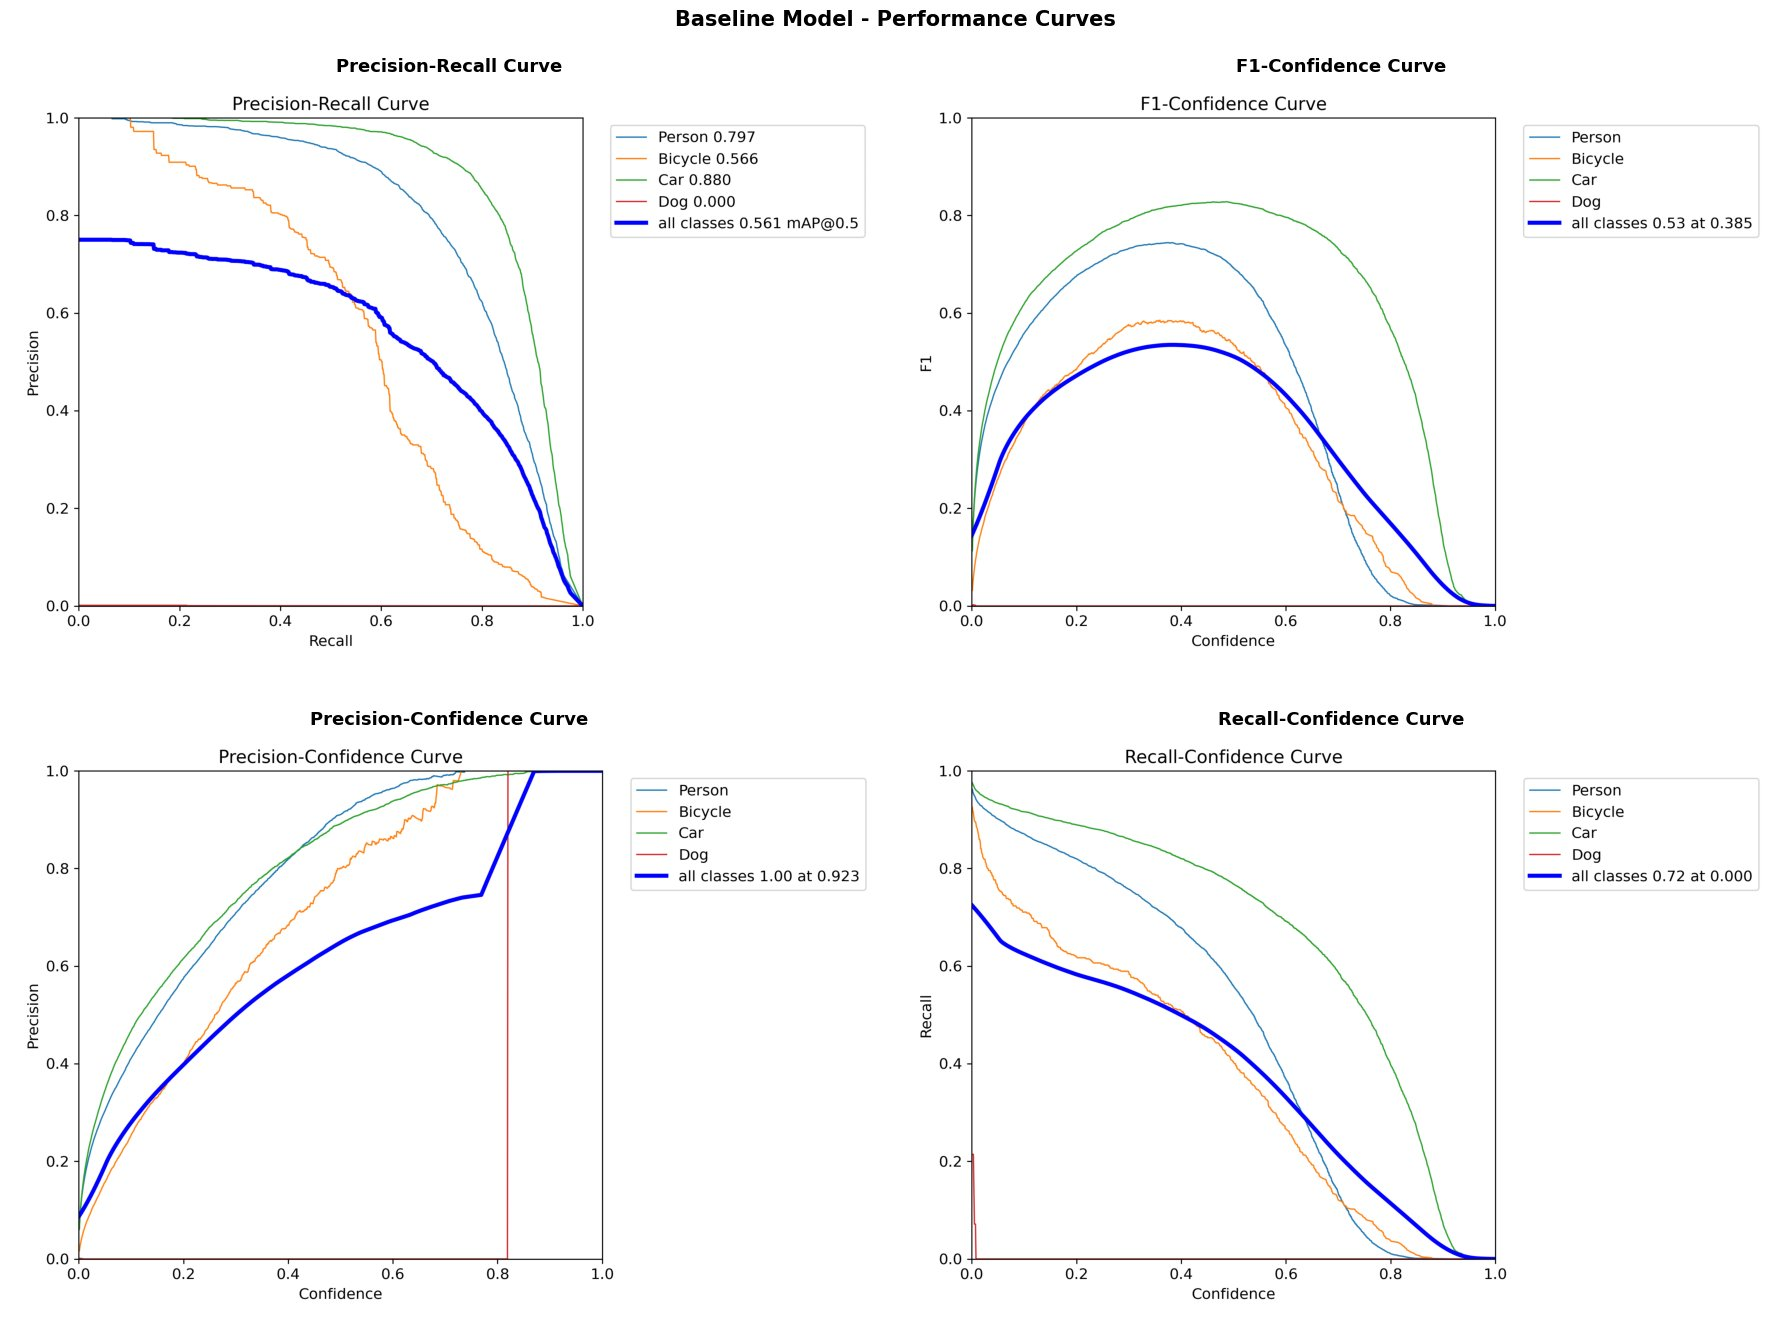

In [ ]:
from PIL import Image

# Doğru dosya isimlerini kullanıyorum (Box prefix'i var)
curves = {
    'BoxPR_curve.png': 'Precision-Recall Curve',
    'BoxF1_curve.png': 'F1-Confidence Curve',
    'BoxP_curve.png': 'Precision-Confidence Curve',
    'BoxR_curve.png': 'Recall-Confidence Curve'
}

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for idx, (filename, title) in enumerate(curves.items()):
    curve_path = RUNS_DIR / filename

    if curve_path.exists():
        img = Image.open(curve_path)
        axes[idx].imshow(img)
        axes[idx].set_title(title, fontsize=13, fontweight='bold')
        axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, f'{filename} bulunamadi',
                      ha='center', va='center', fontsize=12)
        axes[idx].axis('off')

plt.suptitle('Baseline Model - Performance Curves', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

**Precision-Recall eğrisi**

- **Car (0.880):** Eğri sağ üst köşeye yakın. Yüksek recall'a çıkarken precision'ı uzun süre koruyor.
- **Person (0.797):** İyi ama car kadar değil. Recall 0.8 civarına gelince precision düşmeye başlıyor. Daha fazla insan yakalamak istersek yanlış alarm artacak.
- **Bicycle (0.566):** Recall 0.6'ya ulaşmadan precision sert düşüyor.
- **Dog (0.000):** Eğri yok.
- **Tüm sınıflar (0.561):** Car'ın yüksek değeri dog'un sıfırını dengelemeye çalışıyor.

**F1-Confidence eğrisi**

Confidence eşiğini seçmek için bu grafik kullanılıyor. Tüm sınıflar için F1 en yüksek 0.53 değerine confidence 0.385'te ulaşıyor. Car'ın platosu geniş (0.4-0.5 arası), yani eşik seçimine pek duyarlı değil. Person'da tepe daha dar, bicycle'da ise F1 0.57'yi geçmiyor. Eşik ne olursa olsun bicycle'ı kurtarmak mümkün değil.

**Precision-Confidence eğrisi**

Confidence 0.9'a yaklaştıkça tüm sınıflarda precision 1.0'a çıkıyor, yani model çok emin olduğu tahminlerde neredeyse hiç yanılmıyor. Bicycle en yavaş yükselen eğri, confidence 0.6'da bile precision 0.9'a zor ulaşıyor.

**Recall-Confidence eğrisi**

Confidence 0'dayken bile (tüm tahminler kabul edilse) toplam recall 0.72 civarında. Yani eşikten bağımsız olarak nesnelerin yaklaşık %28'i hiç tespit edilmiyor. Bu kısım eşik ayarıyla çözülemez, modelin kendisinin daha iyi olması gerekiyor.

Optimal eşik 0.385 ama bu eşikte bile bicycle ve dog için kabul edilebilir bir sonuç yok.

### 5.9 Baseline hakkında genel değerlendirme

Standart YOLO11n ile 22 epoch eğitim yaptım. En iyi sonuç 12. epoch'ta geldi.

| Metrik | Değer |
|---|---:|
| mAP@50 | 0.561 |
| mAP@50-95 | 0.303 |
| Precision | 0.569 |
| Recall | 0.512 |

Bu değerler ilk bakışta orta seviye görünüyor ama aslında sınıf dengesizliğinin ürettiği bir ortalama. Car'ın 0.88'lik değeri ortalamayı yukarı çekerken dog'un sıfırı aşağı çekiyor.

**Neden bu sonuçlar?** Veri analizinde tespit ettiğim sorunlar modelin performansına doğrudan yansımış:

1. **Sınıf dengesizliği (182:1):** Kayıp fonksiyonu car ve person tarafından domine ediliyor, dog neredeyse hiç sinyal üretmiyor.
2. **Küçük nesne baskınlığı (%58.3):** Uzaktaki insanlar ve bisikletler kaçırılıyor. Recall-confidence eğrisindeki %28'lik kayıp büyük ölçüde buradan geliyor.
3. **Şekil farkları:** Dar person kutularında birkaç piksellik hata IoU'yu düşürüyor, mAP@50-95 bu yüzden düşük.
4. **Düşük kontrast:** Baseline'da kontrastla ilgili hiçbir ön işleme yapmadım. Düşük kontrastlı karelerde performansın daha da kötü olduğunu tahmin ediyorum.

Sonraki bölümde bu sorunları tek tek ele almaya çalıştım. Her denemede tek bir şeyi değiştirdim ki farkın neden geldiğini söyleyebileyim.

## 6. İyileştirme Denemeleri

> Bu bölümde Colab oturumu yenilendiği için kütüphaneleri ve yolları tekrar tanımlıyorum.

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 23.1 MB/s eta 0:00:00


In [ ]:
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ultralytics import YOLO
import json
import random
from collections import Counter
from sklearn.cluster import KMeans

# Seed sabitleme (reproducibility icin)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Ana yollari tanimliyorum
BASE_PATH = Path("/content/drive/MyDrive/tez/data")
RUNS_DIR = Path("/content/drive/MyDrive/tez/runs")

# GPU kontrolu
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"GPU: {gpu_name} | VRAM: {gpu_mem:.2f} GB")
else:
    print("WARNING: GPU bulunamadi!")

# Google Drive mount kontrolu
if not BASE_PATH.exists():
    print("WARNING: Google Drive mount edilmemis!")
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print(f"Drive baglanti: OK")
    print(f"Veri yolu: {BASE_PATH}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU: Tesla T4 | VRAM: 14.74 GB
Drive baglanti: OK
Veri yolu: /content/drive/MyDrive/tez/data


### 6.1 Dog ve bicycle için offline augmentation

Ultralytics eğitim sırasında zaten mosaic, flip ve HSV değişimi gibi online augmentation'lar yapıyor. Ama bunlar her sınıfa eşit uygulanıyor, azınlık sınıflarının görülme sıklığını artırmıyor. Bu yüzden dog veya bicycle içeren görüntülerden yeni kopyalar üretip diske yazdım (offline augmentation).

Albumentations kullanmamın sebebi kutuları görüntüyle birlikte otomatik dönüştürmesi. Görüntü döndürülünce veya aynalanınca kutu koordinatları da ona göre güncelleniyor.

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import shutil

# Albumentations kurulumu (Colab'da genelde yuklu ama kontrol edelim)
try:
    import albumentations
    print(f"Albumentations version: {albumentations.__version__}")
except:
    print("Albumentations yukleniyor...")
    !pip install albumentations --quiet
    import albumentations as A

# Augmentation pipeline tanimliyorum (bbox-aware)
# Albumentations otomatik olarak bbox koordinatlarini donusturuyor
aug_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.CLAHE(clip_limit=2.0, p=0.3)
], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels']))

Albumentations version: 2.0.8


Pipeline'daki dönüşümler ve neden seçtiğim:

| Dönüşüm | Olasılık | Amaç |
|---|---:|---|
| HorizontalFlip | 0.5 | Sol-sağ çeşitliliği |
| Rotate (±15°) | 0.5 | Kamera açısı ve yol eğimi farkları |
| RandomBrightnessContrast | 0.5 | Farklı sıcaklık ve AGC koşulları |
| GaussNoise | 0.3 | Termal sensör gürültüsü |
| GaussianBlur | 0.3 | Hareket bulanıklığı, odak dışı nesneler |
| CLAHE | 0.3 | Düşük kontrastlı kareler |

### 6.2 Augmentation fonksiyonu

Fonksiyon, verilen sınıfı içeren görüntüleri buluyor ve hedef sayıya ulaşana kadar her birinden birkaç augmented kopya üretiyor. Dönüşümden sonra görüntü dışına taşan veya çok küçülen kutuları atıyorum.

In [ ]:
def augment_class_data(class_id, class_name, target_count, output_suffix="aug"):
    """
    Belirli bir sinif icin offline augmentation uygular
    Bbox koordinatlarini otomatik olarak transform eder ve 0-1 araliginda tutar
    """

    train_img_dir = BASE_PATH / "train/images"
    train_label_dir = BASE_PATH / "train/labels"

    # Bu sinifa ait tum label dosyalarini buluyorum
    all_labels = list(train_label_dir.glob("*.txt"))
    class_samples = []

    for label_file in all_labels:
        with open(label_file, 'r') as f:
            lines = f.readlines()
            for line in lines:
                if line.strip():
                    try:
                        # Class ID'yi once float'a sonra int'e ceviriyorum
                        cls = int(float(line.split()[0]))
                        if cls == class_id:
                            class_samples.append(label_file.stem)
                            break
                    except:
                        continue

    original_count = len(class_samples)
    aug_needed = target_count - original_count
    aug_per_image = max(1, aug_needed // original_count)

    print(f"\n{'='*60}")
    print(f"{class_name} Sinifi Augmentation")
    print(f"{'='*60}")
    print(f"Mevcut ornek sayisi: {original_count}")
    print(f"Hedef ornek sayisi: {target_count}")
    print(f"Olusturulacak augmented ornek: {aug_needed}")
    print(f"Her ornek icin augmentation sayisi: {aug_per_image}")
    print(f"{'='*60}\n")

    created_count = 0

    for sample_name in class_samples[:]:
        img_path = train_img_dir / f"{sample_name}.jpeg"
        label_path = train_label_dir / f"{sample_name}.txt"

        if not img_path.exists():
            continue

        # Goruntu ve bbox'lari yukle
        image = cv2.imread(str(img_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        # YOLO formatindaki bbox'lari oku
        bboxes = []
        class_labels = []

        with open(label_path, 'r') as f:
            for line in f:
                if not line.strip():
                    continue
                parts = line.strip().split()
                cls = int(float(parts[0]))
                x_c, y_c, w_n, h_n = map(float, parts[1:5])

                # Koordinatlari 0-1 araliginda tut
                x_c = max(0.0, min(1.0, x_c))
                y_c = max(0.0, min(1.0, y_c))
                w_n = max(0.0, min(1.0, w_n))
                h_n = max(0.0, min(1.0, h_n))

                bboxes.append([x_c, y_c, w_n, h_n])
                class_labels.append(cls)

        # Her ornek icin belirlenen sayida augmentation uygula
        for aug_idx in range(aug_per_image):
            if created_count >= aug_needed:
                break

            try:
                # Augmentation uygula
                augmented = aug_transform(image=image, bboxes=bboxes, class_labels=class_labels)
                aug_image = augmented['image']
                aug_bboxes = augmented['bboxes']
                aug_labels = augmented['class_labels']

                # Augmented bbox'lari temizle
                cleaned_bboxes = []
                cleaned_labels = []
                for bbox, label in zip(aug_bboxes, aug_labels):
                    x_c_clean = max(0.0, min(1.0, bbox[0]))
                    y_c_clean = max(0.0, min(1.0, bbox[1]))
                    w_clean = max(0.0, min(1.0, bbox[2]))
                    h_clean = max(0.0, min(1.0, bbox[3]))

                    # Gecerli bbox ise kaydet
                    if w_clean > 0.001 and h_clean > 0.001:
                        cleaned_bboxes.append([x_c_clean, y_c_clean, w_clean, h_clean])
                        cleaned_labels.append(label)

                # Eger hic gecerli bbox kalmadiysa bu augmentation'i atla
                if len(cleaned_bboxes) == 0:
                    continue

                # Yeni dosya adlari
                new_img_name = f"{sample_name}_{output_suffix}_{aug_idx}.jpeg"
                new_label_name = f"{sample_name}_{output_suffix}_{aug_idx}.txt"

                # Augmented gorseli kaydet
                aug_image_bgr = cv2.cvtColor(aug_image, cv2.COLOR_RGB2BGR)
                cv2.imwrite(str(train_img_dir / new_img_name), aug_image_bgr)

                # Augmented label'i kaydet
                with open(train_label_dir / new_label_name, 'w') as f:
                    for bbox, label in zip(cleaned_bboxes, cleaned_labels):
                        f.write(f"{label} {bbox[0]:.6f} {bbox[1]:.6f} {bbox[2]:.6f} {bbox[3]:.6f}\n")

                created_count += 1

                if created_count % 100 == 0:
                    print(f"  Ilerleme: {created_count}/{aug_needed} ornek olusturuldu")

            except Exception as e:
                continue

        if created_count >= aug_needed:
            break

    print(f"\n{class_name}: {created_count} yeni augmented ornek olusturuldu")
    print(f"  Toplam: {original_count} (original) + {created_count} (augmented) = {original_count + created_count}")

    return original_count, created_count

print("Augmentation fonksiyonu yuklendi")

Augmentation fonksiyonu yuklendi


### 6.3 Augmentation'ın uygulanması

Hedef, dog içeren görüntü sayısını yaklaşık 2,000'e, bicycle içerenleri yaklaşık 8,000'e çıkarmaktı. Buradaki sayılar etiket değil görüntü sayısı. Bir görüntüde birden fazla köpek veya bisiklet olabiliyor.

In [ ]:
# Dog sinifini augment ediyoruz (226 -> 2000)
dog_original, dog_augmented = augment_class_data(
    class_id=3,
    class_name="Dog",
    target_count=2000,
    output_suffix="aug_dog"
)

# Bicycle sinifini augment ediyoruz (3986 -> 8000)
bicycle_original, bicycle_augmented = augment_class_data(
    class_id=1,
    class_name="Bicycle",
    target_count=8000,
    output_suffix="aug_bicycle"
)

# Ozet rapor
print("\n" + "="*70)
print("AUGMENTATION OZET RAPORU")
print("="*70)
print(f"\nDog:")
print(f"  Onceki: {dog_original} ornek")
print(f"  Eklenen: {dog_augmented} augmented ornek")
print(f"  Sonraki: {dog_original + dog_augmented} ornek")
print(f"  Artis orani: {((dog_augmented/dog_original)*100):.1f}%")

print(f"\nBicycle:")
print(f"  Onceki: {bicycle_original} ornek")
print(f"  Eklenen: {bicycle_augmented} augmented ornek")
print(f"  Sonraki: {bicycle_original + bicycle_augmented} ornek")
print(f"  Artis orani: {((bicycle_augmented/bicycle_original)*100):.1f}%")

print("\n" + "="*70)
print("Augmentation tamamlandi! Yeni veri seti egitime hazir.")
print("="*70)


Dog Sinifi Augmentation
Mevcut ornek sayisi: 202
Hedef ornek sayisi: 2000
Olusturulacak augmented ornek: 1798
Her ornek icin augmentation sayisi: 8

  Ilerleme: 100/1798 ornek olusturuldu
  Ilerleme: 200/1798 ornek olusturuldu
  Ilerleme: 300/1798 ornek olusturuldu
  Ilerleme: 400/1798 ornek olusturuldu
  Ilerleme: 500/1798 ornek olusturuldu
  Ilerleme: 600/1798 ornek olusturuldu
  Ilerleme: 700/1798 ornek olusturuldu
  Ilerleme: 800/1798 ornek olusturuldu
  Ilerleme: 900/1798 ornek olusturuldu
  Ilerleme: 1000/1798 ornek olusturuldu
  Ilerleme: 1100/1798 ornek olusturuldu
  Ilerleme: 1200/1798 ornek olusturuldu
  Ilerleme: 1300/1798 ornek olusturuldu
  Ilerleme: 1400/1798 ornek olusturuldu
  Ilerleme: 1500/1798 ornek olusturuldu

Dog: 1520 yeni augmented ornek olusturuldu
  Toplam: 202 (original) + 1520 (augmented) = 1722

Bicycle Sinifi Augmentation
Mevcut ornek sayisi: 1970
Hedef ornek sayisi: 8000
Olusturulacak augmented ornek: 6030
Her ornek icin augmentation sayisi: 3

  Ilerlem

Sonuçlar:

| Sınıf | Orijinal görüntü | Eklenen | Toplam |
|---|---:|---:|---:|
| Dog | 202 | 1,520 | 1,722 |
| Bicycle | 1,970 | 5,577 | 7,547 |

Dog'da hedef olan 1,798'e ulaşılamadı. Her görüntüden en fazla 8 kopya üretiliyor ve dönüşüm sonrası kutusu geçersiz kalan örnekler atlanıyor. Yine de dog içeren görüntü sayısı yaklaşık 8.5 katına çıktı.

Burada sonradan fark ettiğim iki önemli nokta var:

1. **Augmented görüntüler doğrudan `train/images` klasörüne yazıldı.** Bu yüzden train seti 8,862'den 15,961 görüntüye çıktı ve sonraki tüm modeller (V2-V6) bu genişletilmiş set üzerinde eğitildi.
2. **Dengesizlik etiket düzeyinde beklediğim kadar azalmadı.** Dog içeren görüntülerin çoğunda araçlar ve insanlar da var. Görüntüyü kopyalayınca o araçlar ve insanlar da kopyalanıyor. Ayrıca bicycle augmentation'ı klasörü tararken önceki adımda üretilen dog kopyalarını da kaynak olarak kullanmış, bazı dosyalar iki kez augment edilmiş (`..._aug_dog_6_aug_bicycle_0` gibi).

### 6.4 Augmented örneklerin görsel kontrolü

Rotation ve flip'in kutuları doğru güncelleyip güncellemediğini ve görüntü kalitesinin bozulup bozulmadığını görmek için her sınıftan 6 rastgele augmented örnek çizdim.

Dog sinifi augmented ornekleri kontrol ediliyor...



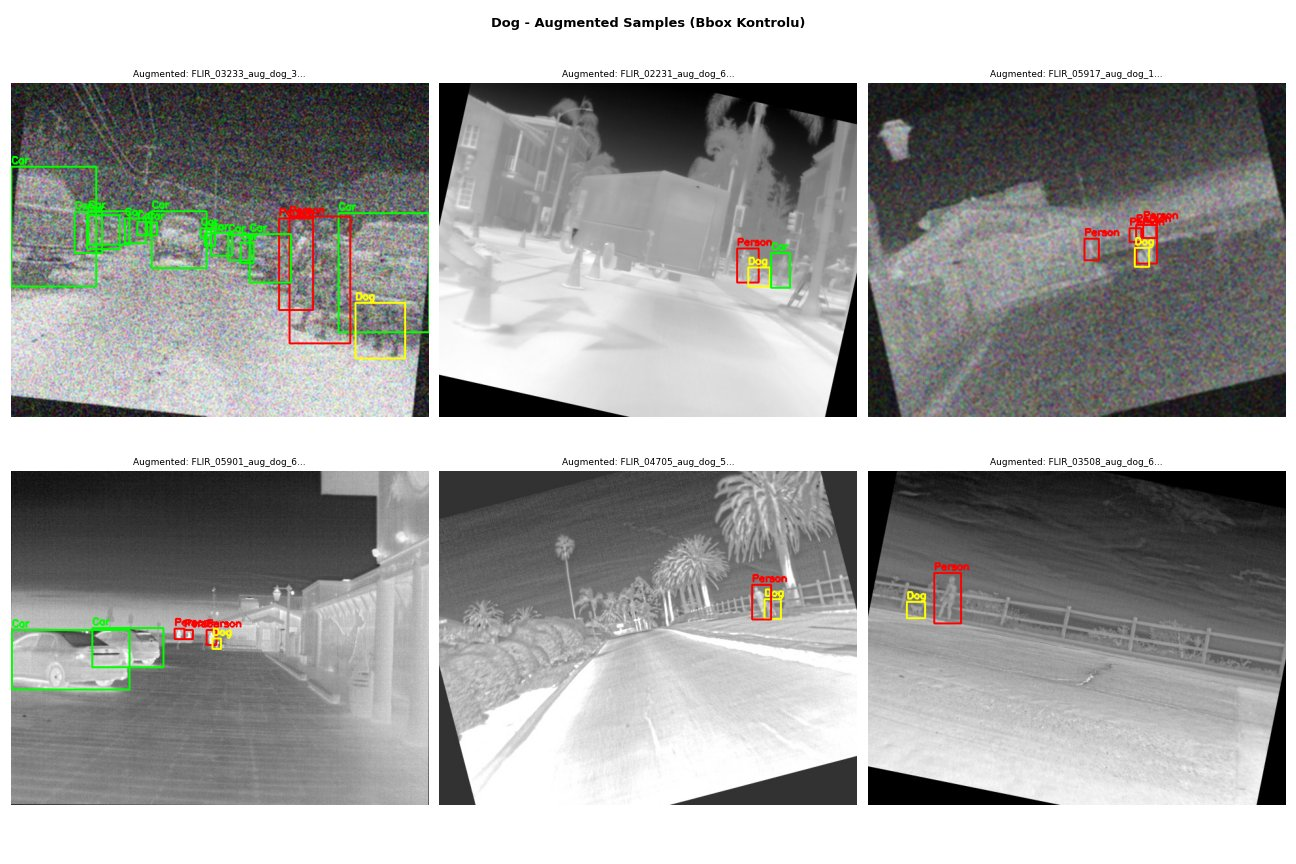


Bicycle sinifi augmented ornekleri kontrol ediliyor...



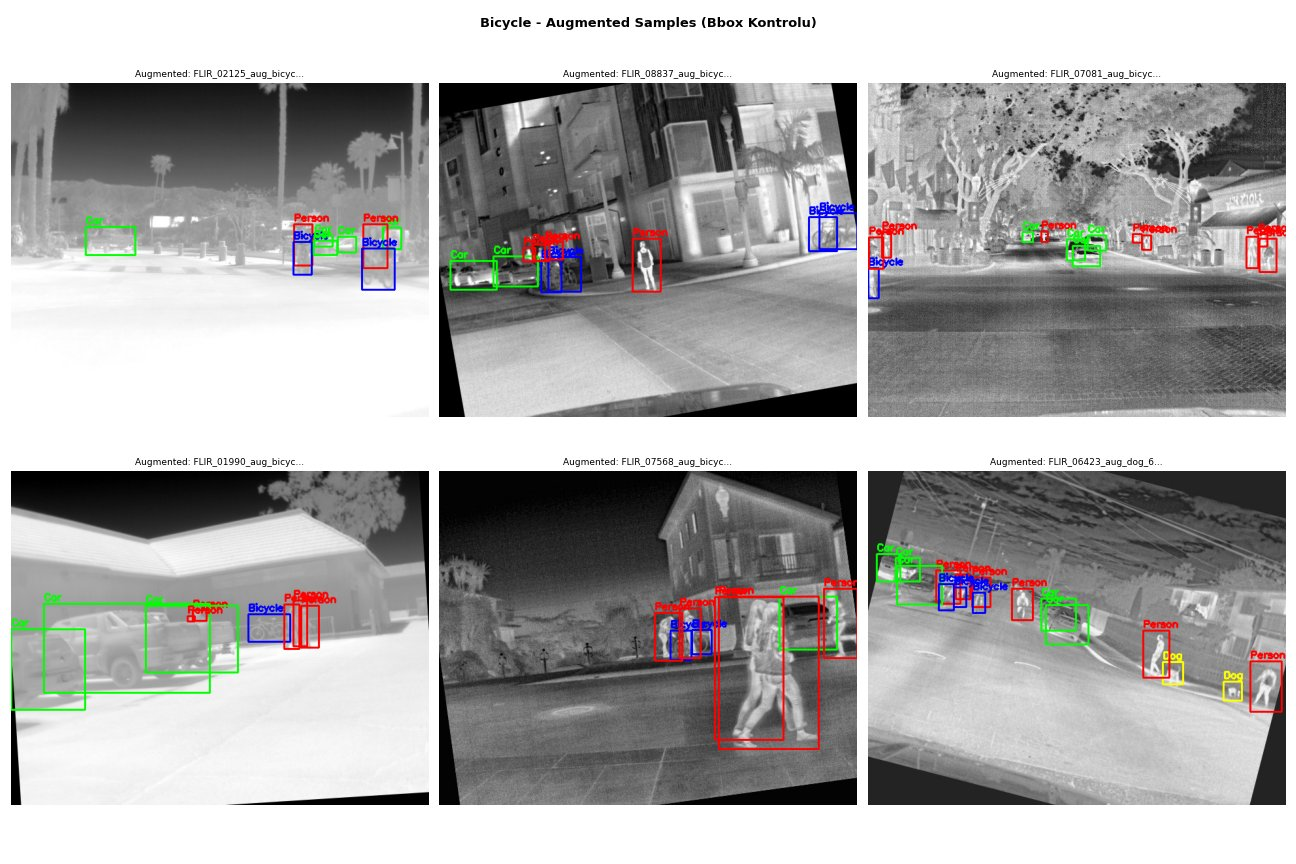

In [ ]:
# Augmented dog ve bicycle orneklerini gorselleştiriyorum
def visualize_augmented_samples(class_id, class_name, num_samples=6):
    """
    Orijinal ve augmented ornekleri yan yana gosterir
    """
    train_img_dir = BASE_PATH / "train/images"
    train_label_dir = BASE_PATH / "train/labels"

    # Bu sinifin augmented dosyalarini buluyorum
    aug_pattern = f"*aug_{class_name.lower()}*.jpeg"
    aug_files = list(train_img_dir.glob(aug_pattern))

    if len(aug_files) == 0:
        print(f"HATA: {class_name} icin augmented dosya bulunamadi!")
        return

    # Rastgele ornekler seciyorum
    selected = random.sample(aug_files, min(num_samples, len(aug_files)))

    class_names = ['Person', 'Bicycle', 'Car', 'Dog']
    class_colors = [(255, 0, 0), (0, 0, 255), (0, 255, 0), (255, 255, 0)]

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    for idx, img_path in enumerate(selected):
        label_path = train_label_dir / f"{img_path.stem}.txt"

        # Gorseli oku
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        # Bbox'lari oku ve ciz
        if label_path.exists():
            with open(label_path, 'r') as f:
                for line in f:
                    if not line.strip():
                        continue
                    parts = line.strip().split()
                    cls = int(float(parts[0]))
                    x_c, y_c, w_n, h_n = map(float, parts[1:5])

                    # YOLO formatindan piksel koordinatlarina donusturuyorum
                    x_center = int(x_c * w)
                    y_center = int(y_c * h)
                    box_w = int(w_n * w)
                    box_h = int(h_n * h)

                    x1 = int(x_center - box_w / 2)
                    y1 = int(y_center - box_h / 2)
                    x2 = int(x_center + box_w / 2)
                    y2 = int(y_center + box_h / 2)

                    color = class_colors[cls]
                    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                    cv2.putText(img, class_names[cls], (x1, y1-5),
                               cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

        axes[idx].imshow(img)
        axes[idx].set_title(f"Augmented: {img_path.stem[:20]}...", fontsize=9)
        axes[idx].axis('off')

    plt.suptitle(f'{class_name} - Augmented Samples (Bbox Kontrolu)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Dog orneklerini kontrol ediyorum
print("Dog sinifi augmented ornekleri kontrol ediliyor...\n")
visualize_augmented_samples(class_id=3, class_name="Dog", num_samples=6)

# Bicycle orneklerini kontrol ediyorum
print("\nBicycle sinifi augmented ornekleri kontrol ediliyor...\n")
visualize_augmented_samples(class_id=1, class_name="Bicycle", num_samples=6)

**Kutular:** Flip ve rotation sonrasında kutular nesnelerin üzerinde kalıyor, koordinat dönüşümü doğru çalışmış. Yalnız döndürülmüş görüntülerde kutular biraz genişliyor. Albumentations dönmüş kutuyu kapsayan yeni bir dikdörtgen çizdiği için bu beklenen bir durum, ama özellikle küçük nesnelerde kutuyu gevşetiyor.

**Gürültü:** GaussNoise bazı örneklerde çok baskın. Dog örneklerinde 1. ve 3. görüntü neredeyse karlı bir televizyon ekranı gibi ve küçük köpekleri seçmek zorlaşıyor. Gerçek termal sensör gürültüsü bu kadar yoğun değil. Bu örneklerin modele faydadan çok zarar vermesi mümkün.

**Siyah köşeler:** Rotation görüntünün köşelerinde siyah alanlar bırakıyor. Gerçek termal görüntülerde böyle bir desen yok.

**Zincirleme augmentation:** Bicycle örneklerinden sonuncusu (`FLIR_06423_aug_dog_6_aug_bicycle_0`) önce dog, sonra bicycle için augment edilmiş. Yani iki kez döndürülmüş ve iki kez gürültü eklenmiş olabilir.

Bu haliyle devam etmeye karar verdim. Örneklerin çoğu temiz ve gürültülü örneklerin modele dayanıklılık kazandırma ihtimali de var. Ama V2'nin sonuçlarını yorumlarken bu noktaları akılda tutmak gerekiyor. Tekrar yapsaydım GaussNoise'ın olasılığını 0.1'e düşürür ve augmentation'ı ayrı bir klasöre yazardım.

### 6.5 V2: Augmented veri ile YOLO11n

V1 ile aynı model (YOLO11n) ve aynı hiperparametreleri kullandım. Tek değişken augmented veri, böylece farkın augmentation'dan geldiğini söyleyebilirim.

In [ ]:
from ultralytics import YOLO

# V2 eğitimi için yolları tanimliyorum
yaml_path = BASE_PATH / "thermal_dataset.yaml"
runs_dir = BASE_PATH.parent / "runs"

# YOLOv11n modelini yukluyorum (baseline ile ayni model)
model = YOLO('yolo11n.pt')

print("="*70)
print("MODEL V2 EĞİTİMİ BAŞLIYOR")
print("="*70)
print(f"Model: YOLOv11n (Baseline ile ayni)")
print(f"Veri: Augmented (Dog: 1722, Bicycle: 7547)")
print(f"Tek degisken: Veri artirma")
print("="*70 + "\n")

# Baseline ile ayni hiperparametrelerle egitim baslatiyorum
results = model.train(
    data=str(yaml_path),
    epochs=50,
    batch=32,
    imgsz=640,
    project=str(runs_dir),
    name='v2_augmented_nano',
    patience=10,
    save=True,
    save_period=5,
    device=0,
    workers=8,
    exist_ok=True,
    cache=True,
    verbose=True
)

print("\n" + "="*70)
print("V2 EĞİTİMİ TAMAMLANDI")
print("="*70)

MODEL V2 EĞİTİMİ BAŞLIYOR
Model: YOLOv11n (Baseline ile ayni)
Veri: Augmented (Dog: 1722, Bicycle: 7547)
Tek degisken: Veri artirma

Ultralytics 8.3.242 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/tez/data/thermal_dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scal

V2 41 epoch'ta erken durdu ve 1.8 saat sürdü.

| Sınıf | V1 mAP@50 | V2 mAP@50 | Fark |
|---|---:|---:|---:|
| Person | 0.798 | 0.814 | +0.016 |
| Car | 0.880 | 0.894 | +0.014 |
| Bicycle | 0.567 | 0.540 | -0.027 |
| Dog | 0.000 | 0.001 | +0.001 |
| **Genel** | **0.561** | **0.562** | **+0.001** |

Genel mAP neredeyse hiç değişmedi. Dog sınıfı 1,722 görüntüye rağmen hâlâ sıfırda. Bicycle ise geriledi. 6.4'te gördüğüm aşırı gürültülü örnekler bunun bir sebebi olabilir. Person ve car'daki küçük artış ise büyük ihtimalle augmented görüntülerdeki ek insan ve araç örneklerinden geliyor.

Augmentation tek başına işe yaramadı. Neden?

1. **Dengesizlik etiket düzeyinde hâlâ büyük.** Köpekli görüntüler kopyalanırken içlerindeki araçlar da kopyalandı. Loss'u hâlâ car domine ediyor.
2. **Aynı 202 köpeğin varyasyonları.** 1,722 görüntü var ama altında sadece 202 farklı köpek görüntüsü yatıyor. Model yeni bir köpek görmüyor, aynı köpeği farklı açılardan görüyor.
3. **Model kapasitesi.** YOLO11n çok küçük bir model ve az örnekli bir sınıfı ayırt edecek özellikleri öğrenemiyor olabilir.

Üçüncü ihtimali test etmek için bir sonraki adımda daha büyük bir modele geçtim.

### 6.6 V3: Daha büyük model (YOLO11s)

YOLO11s yaklaşık 9.4M parametreyle YOLO11n'nin (2.6M) 3.5 katı kapasiteye sahip. Veri V2 ile aynı, değişen tek şey model. Small model daha fazla bellek kullandığı için batch'i 16'ya düşürmem gerekti.

Small model de başarısız olursa sorunun kapasite değil veri ve loss dengesizliği olduğunu söyleyebileceğim. Önce önceki modelden kalan GPU belleğini temizliyorum.

In [ ]:
import gc
import torch
from ultralytics import YOLO

# --- 1. HAFIZA TEMİZLİĞİ (GÜVENLİK ÖNLEMİ) ---
print("Hafıza temizleniyor...")

# Önceki model değişkenlerini siliyoruz (varsa)
try:
    del model
    del results
except NameError:
    pass

# Python'un çöp toplayıcısını (Garbage Collector) çalıştır
gc.collect()

# GPU belleğini boşalt
torch.cuda.empty_cache()

print(f"Hafıza temizlendi. GPU Bellek: {torch.cuda.memory_allocated()/1024**2:.2f} MB")
print("="*70)

Hafıza temizleniyor...
Hafıza temizlendi. GPU Bellek: 104.30 MB


In [ ]:
from ultralytics import YOLO

# YOLLAR
yaml_path = BASE_PATH / "thermal_dataset.yaml"
runs_dir = BASE_PATH.parent / "runs"

model = YOLO('yolo11s.pt')

results = model.train(
    data=str(yaml_path),
    epochs=50,
    batch=16,  # Small daha ağır, batch düşürdük
    imgsz=640,
    project=str(runs_dir),
    name='v3_augmented_small1',
    patience=10,
    device=0,
    workers=8,
    exist_ok=True,
    cache=False
)

Ultralytics 8.3.243 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/tez/data/thermal_dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=v3_augmented_small1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, pe

Sonuçlar ilk bakışta umut verici:

- Genel mAP@50: V1 0.561, V2 0.562, **V3 0.623**
- Dog mAP@50: V1 0.000, V2 0.001, **V3 0.185**
- Person, bicycle ve car'da da artış var.

Dog ilk kez sıfırdan farklı bir değer aldı. Ama eğitim sürecinde bir tuhaflık var: **en iyi sonuç 1. epoch'ta** geldi, sonraki 10 epoch'ta iyileşme olmadı ve eğitim 11. epoch'ta durdu.

`results.csv`'ye bakınca ne olduğu anlaşılıyor:

| Epoch | mAP@50 |
|---:|---:|
| 1 | 0.622 |
| 2 | 0.583 |
| 3 | 0.500 |
| 6 | 0.562 |
| 11 | 0.577 |

mAP 3. epoch'ta dibe vurup sonra tekrar toparlanmaya başlıyor. Bunun sebebi büyük ihtimalle learning rate warmup'ı. Ultralytics ilk 3 epoch boyunca learning rate'i kademeli olarak artırıyor. 1. epoch'ta düşük learning rate ile COCO ağırlıkları neredeyse korunuyor ve model iyi bir başlangıç değeri veriyor. Learning rate yükseldikçe ağırlıklar bu noktadan uzaklaşıyor ve performans geçici olarak düşüyor. Aynı desen V4 ve V6'da da var (her ikisinde de 3. epoch'ta düşüş, sonra toparlanma). V6'nın logunda learning rate'in 1. epoch'ta 0.010'dan 3. epoch'ta 0.029'a çıktığı görülüyor.

Sorun şu ki patience=10 olduğu için model toparlanma bitmeden durduruldu. 11. epoch'ta mAP hâlâ yükseliyordu. Dolayısıyla V3'ün 0.623'lük değeri eğitilmiş bir modelin değil, neredeyse hiç adapte olmamış bir başlangıç noktasının değeri.

Dog'daki 0.185 için de dikkatli olmak gerekiyor. Validation setinde sadece 14 köpek var ve model bunların 3'ünü yakaladı (recall 0.214). 14 örnekle bu oranın %95 güven aralığı yaklaşık %8 ile %48 arası (Wilson aralığı). Yani bu değer tek başına bir şey kanıtlamıyor, bir sonraki epoch'ta 1 köpeğin daha kaçırılması AP'yi ciddi şekilde değiştirebilir.

Bu deneyden çıkardığım ders: sonraki eğitimlerde patience'ı 15'e çıkardım.

### 6.7 V4: CLAHE ön işleme

2.3'te bazı görüntülerde kontrastın çok düşük olduğunu (std 25-26) görmüştüm. Küçük nesnelerin arka plandan ayrışmasına yardım etmesi için tüm train görüntülerine CLAHE (Contrast Limited Adaptive Histogram Equalization) uyguladım.

CLAHE, görüntüyü küçük karelere bölüp her karede ayrı histogram eşitleme yapıyor. Böylece görüntünün genel parlaklığı bozulmadan yerel kontrast artıyor. `clipLimit` değeri gürültünün de aşırı güçlenmesini engelliyor. Termal görüntüler için 3.0 ve 8x8'lik ızgara kullandım.

Veri Drive'dan okunduğu için 15,961 görüntünün işlenmesi 2 saat 40 dakika sürdü.

In [ ]:
import cv2
import os
from pathlib import Path
from tqdm import tqdm
import shutil

# Yollari tanimliyorum
INPUT_DIR = Path('/content/drive/MyDrive/tez/data/train/images')
LABEL_DIR = Path('/content/drive/MyDrive/tez/data/train/labels')

OUTPUT_DIR = Path('/content/drive/MyDrive/tez/data/train_clahe/images')
OUTPUT_LABEL_DIR = Path('/content/drive/MyDrive/tez/data/train_clahe/labels')

# Klasorleri olustur
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_LABEL_DIR.mkdir(parents=True, exist_ok=True)

print("="*70)
print("TERMAL GÖRÜNTÜ İYİLEŞTİRME (CLAHE) BAŞLIYOR")
print("="*70)
print(f"Input: {INPUT_DIR}")
print(f"Output: {OUTPUT_DIR}")
print("="*70 + "\n")

# CLAHE nesnesi olustur (clipLimit 3.0 termal icin optimal)
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))

# Tum goruntuleri bul
image_files = list(INPUT_DIR.glob('*.jpeg')) + list(INPUT_DIR.glob('*.jpg')) + list(INPUT_DIR.glob('*.png'))

print(f"Toplam {len(image_files)} goruntu bulundu\n")

processed_count = 0
error_count = 0

for img_path in tqdm(image_files, desc="CLAHE uygulaniyor"):
    try:
        # Goruntuyu grayscale oku (termal goruntular zaten tek kanal)
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

        if img is None:
            error_count += 1
            continue

        # CLAHE uygula
        enhanced_img = clahe.apply(img)

        # Kaydet
        cv2.imwrite(str(OUTPUT_DIR / img_path.name), enhanced_img)

        # Label dosyasini kopyala (koordinatlar degismez)
        label_path = LABEL_DIR / (img_path.stem + ".txt")
        if label_path.exists():
            shutil.copy(label_path, OUTPUT_LABEL_DIR / label_path.name)

        processed_count += 1

    except Exception as e:
        error_count += 1
        print(f"\nHATA: {img_path.name} - {e}")

print("\n" + "="*70)
print("İŞLEM TAMAMLANDI")
print("="*70)
print(f"Başarılı: {processed_count} görüntü")
print(f"Hata: {error_count} görüntü")
print(f"Çıktı: {OUTPUT_DIR}")
print("="*70)

TERMAL GÖRÜNTÜ İYİLEŞTİRME (CLAHE) BAŞLIYOR
Input: /content/drive/MyDrive/tez/data/train/images
Output: /content/drive/MyDrive/tez/data/train_clahe/images

Toplam 15961 goruntu bulundu



CLAHE uygulaniyor: 100%|██████████| 15961/15961 [2:40:12<00:00,  1.66it/s]


İŞLEM TAMAMLANDI
Başarılı: 15961 görüntü
Hata: 0 görüntü
Çıktı: /content/drive/MyDrive/tez/data/train_clahe/images


Önce ve sonra karşılaştırması:

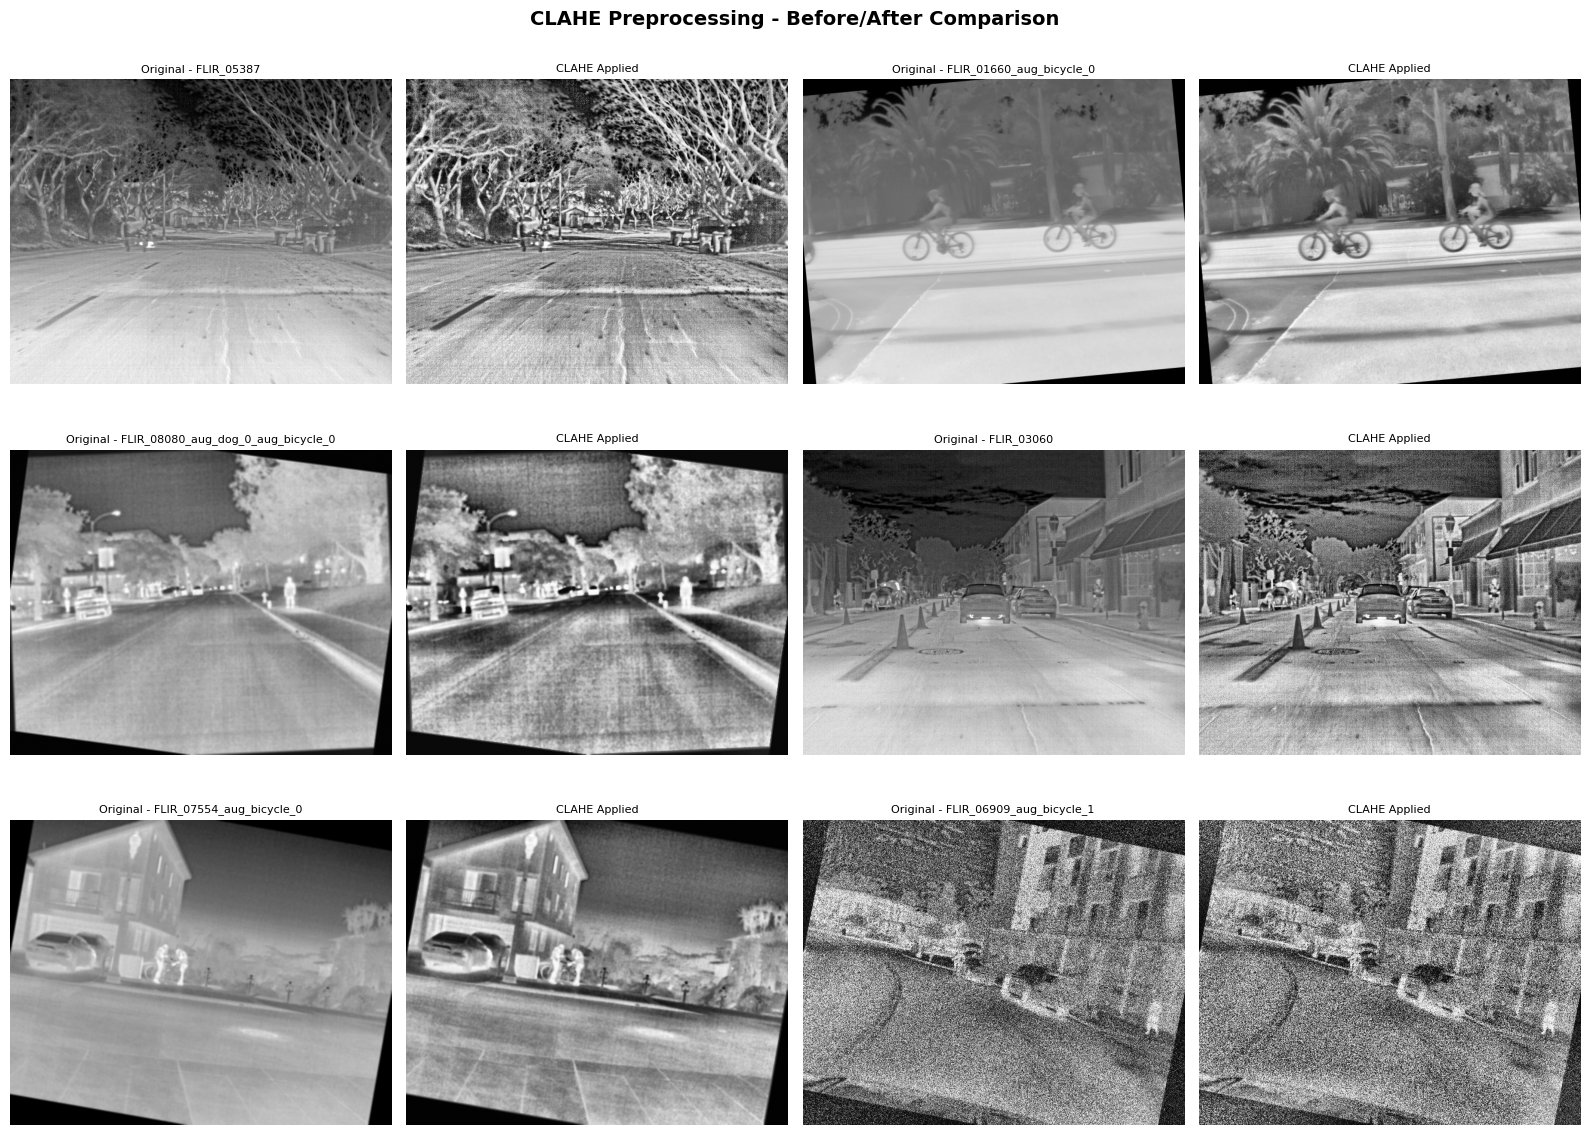

Karşılaştırma görseli kaydedildi: /content/drive/MyDrive/tez/runs/clahe_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import random

# Rastgele 6 goruntu sec ve onc/sonra karsilastirmasi yap
sample_images = random.sample(list(INPUT_DIR.glob('*.jpeg')), 6)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for idx, img_path in enumerate(sample_images):
    # Orijinal
    orig = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

    # CLAHE uygulanmis
    clahe_obj = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe_obj.apply(orig)

    # Orijinal goster
    axes[idx*2].imshow(orig, cmap='gray')
    axes[idx*2].set_title(f'Original - {img_path.stem}', fontsize=8)
    axes[idx*2].axis('off')

    # CLAHE goster
    axes[idx*2+1].imshow(enhanced, cmap='gray')
    axes[idx*2+1].set_title(f'CLAHE Applied', fontsize=8)
    axes[idx*2+1].axis('off')

plt.suptitle('CLAHE Preprocessing - Before/After Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/tez/runs/clahe_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("Karşılaştırma görseli kaydedildi: /content/drive/MyDrive/tez/runs/clahe_comparison.png")

CLAHE sonrası özellikle arka plandaki detaylar (ağaçlar, binalar, yol çizgileri) çok daha belirgin hale geliyor. İnsanlar ve araçlar daha net seçiliyor. Buna karşılık bazı görüntülerde gürültü de belirginleşiyor ve gökyüzü gibi düz alanlarda doku oluşuyor.

Şimdi aynı YOLO11s modelini bu görüntülerle eğitiyorum. Patience'ı 15'e çıkardım.

In [ ]:
from ultralytics import YOLO

# YAML yolu
yaml_path = '/content/drive/MyDrive/tez/data/thermal_clahe.yaml'
runs_dir = Path('/content/drive/MyDrive/tez/runs')

# Model yukle
model = YOLO('yolo11s.pt')

print("="*70)
print("V4 EĞİTİMİ BAŞLIYOR - CLAHE PREPROCESSING")
print("="*70)
print("Yöntem: CLAHE (Contrast Limited Adaptive Histogram Equalization)")
print("Model: YOLOv11s")
print("Veri: CLAHE iyileştirilmiş termal görüntüler")
print("="*70 + "\n")

results = model.train(
    data=yaml_path,
    epochs=50,
    batch=16,
    imgsz=640,
    project=str(runs_dir),
    name='v4_small_clahe',
    patience=15,
    save=True,
    device=0,
    workers=8,
    exist_ok=True,
    cache=False,
    verbose=True
)

print("\n" + "="*70)
print("V4 EĞİTİMİ TAMAMLANDI")
print("="*70)

V4 EĞİTİMİ BAŞLIYOR - CLAHE PREPROCESSING
Yöntem: CLAHE (Contrast Limited Adaptive Histogram Equalization)
Model: YOLOv11s
Veri: CLAHE iyileştirilmiş termal görüntüler

Ultralytics 8.3.243 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/tez/data/thermal_clahe.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, mom

V4 43 epoch sürdü (3.5 saat), en iyi sonuç 24. epoch'ta geldi.

| Sınıf | V3 | V4 (CLAHE) |
|---|---:|---:|
| Person | 0.823 | **0.841** |
| Bicycle | 0.594 | **0.648** |
| Car | 0.890 | **0.909** |
| Dog | 0.185 | ~0.01 |
| Genel | 0.623 | 0.603 |

Genel mAP V3'ün biraz altında kaldı ama bu tamamen dog'dan kaynaklanıyor. **Person, bicycle ve car'da V4 o ana kadarki en iyi model.** Bicycle'da artış özellikle belirgin (+0.054). Düşük kontrast bisiklet gibi ince yapılı nesneleri en çok etkileyen sorundu, CLAHE tam da burada işe yaramış görünüyor.

Burada önemli bir sınırlılık var: `thermal_clahe.yaml` dosyasında val seti hâlâ orijinal görüntüleri gösteriyor. Yani model CLAHE'li görüntülerle eğitildi ama CLAHE'siz görüntülerle test edildi. Buna rağmen iyi sonuç vermesi, CLAHE'nin bir çeşit augmentation gibi davranıp modelin kontrasta daha az bağımlı hale gelmesini sağladığını düşündürüyor. Val setine de CLAHE uygulansaydı sonuç muhtemelen daha da iyi olurdu. Bunu sonraki çalışmalara bıraktım.

Dog ise V4'te tekrar sıfıra yakın. V3'teki 0.185'in gerçek bir öğrenme değil, 6.6'da tartıştığım istatistiksel bir dalgalanma olduğunu bu da destekliyor.

### 6.8 V5: Dog sınıfı için oversampling

Dog sınıfı için son bir deneme olarak köpek içeren her görüntüyü 10 kez kopyaladım. Bu, kayıp fonksiyonunda sınıf ağırlığı vermenin kaba bir karşılığı: model her epoch'ta köpekleri 11 kat daha sık görüyor.

Kaynak olarak augmented train setini kullandığım için köpekli görüntü sayısı 2,391 (orijinal + augmented). Her biri 10 kez kopyalanınca train seti yaklaşık 40 bin görüntüye çıktı.

In [ ]:
import os
import shutil
from pathlib import Path
from tqdm import tqdm

# --- AYARLAR ---
INPUT_IMAGES_DIR = Path('/content/drive/MyDrive/tez/data/train/images')
INPUT_LABELS_DIR = Path('/content/drive/MyDrive/tez/data/train/labels')

OUTPUT_IMAGES_DIR = Path('/content/drive/MyDrive/tez/data/train_weighted/images')
OUTPUT_LABELS_DIR = Path('/content/drive/MyDrive/tez/data/train_weighted/labels')

# Klasorleri olustur
OUTPUT_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_LABELS_DIR.mkdir(parents=True, exist_ok=True)

DOG_CLASS_ID = 3
MULTIPLIER = 10

print("="*70)
print(f"VERİ SETİ AĞIRLIKLANDIRMA BAŞLIYOR (Dog x{MULTIPLIER})")
print("="*70 + "\n")

# 1. Tum dosyalari kopyala
print("Orijinal veriler kopyalaniyor...")
for f in tqdm(list(INPUT_IMAGES_DIR.glob('*.*')), desc="Resimler"):
    shutil.copy(f, OUTPUT_IMAGES_DIR / f.name)

for f in tqdm(list(INPUT_LABELS_DIR.glob('*.txt')), desc="Labellar"):
    shutil.copy(f, OUTPUT_LABELS_DIR / f.name)

# 2. Dog iceren dosyalari bul ve cogalt
print("\nKopekler cogaltiliyor...")
label_files = list(OUTPUT_LABELS_DIR.glob('*.txt'))
dog_files = []

for label_path in label_files:
    has_dog = False
    try:
        with open(label_path, 'r') as f:
            for line in f:
                if line.strip():
                    # Float olabilir, int'e cevir
                    class_id = int(float(line.split()[0]))  # <-- DÜZELTME
                    if class_id == DOG_CLASS_ID:
                        has_dog = True
                        break
    except Exception as e:
        print(f"\nHATA: {label_path.name} - {e}")
        continue

    if has_dog:
        dog_files.append(label_path)

print(f"\nToplam {len(dog_files)} kopekli gorsel bulundu")

for label_path in tqdm(dog_files, desc="Dog kopyalaniyor"):
    img_name = label_path.stem

    # Resim dosyasini bul
    img_files = list(OUTPUT_IMAGES_DIR.glob(f"{img_name}.*"))
    if not img_files:
        continue

    img_file = img_files[0]

    # MULTIPLIER kadar kopyala
    for i in range(MULTIPLIER):
        new_name = f"{img_name}_weighted_{i}"

        # Resim kopyala
        shutil.copy(img_file, OUTPUT_IMAGES_DIR / f"{new_name}{img_file.suffix}")

        # Label kopyala
        shutil.copy(label_path, OUTPUT_LABELS_DIR / f"{new_name}.txt")

print("\n" + "="*70)
print("İŞLEM TAMAMLANDI")
print("="*70)
print(f"Orijinal dog dosyasi: {len(dog_files)}")
print(f"Eklenen kopya: {len(dog_files) * MULTIPLIER}")
print(f"Toplam dog: {len(dog_files) * (MULTIPLIER + 1)}")
print(f"Cikti: {OUTPUT_IMAGES_DIR}")
print("="*70)

VERİ SETİ AĞIRLIKLANDIRMA BAŞLIYOR (Dog x10)

Orijinal veriler kopyalaniyor...


Labellar: 100%|██████████| 15959/15959 [03:58<00:00, 66.98it/s] 



Kopekler cogaltiliyor...

Toplam 2391 kopekli gorsel bulundu


Dog kopyalaniyor: 100%|██████████| 2391/2391 [4:45:52<00:00,  7.17s/it]


İŞLEM TAMAMLANDI
Orijinal dog dosyasi: 2391
Eklenen kopya: 23910
Toplam dog: 26301
Cikti: /content/drive/MyDrive/tez/data/train_weighted/images


In [ ]:
# YAML dosyasını Python ile oluştur (syntax hatası olmaz)
import yaml

yaml_data = {
    'path': '/content/drive/MyDrive/tez/data',
    'train': 'train_weighted/images',
    'val': 'val/images',
    'names': {
        0: 'Person',
        1: 'Bicycle',
        2: 'Car',
        3: 'Dog'
    }
}

yaml_path = '/content/drive/MyDrive/tez/data/thermal_weighted.yaml'

with open(yaml_path, 'w') as f:
    yaml.dump(yaml_data, f, default_flow_style=False, sort_keys=False)

print(f"YAML dosyası oluşturuldu: {yaml_path}")

# Kontrol et
with open(yaml_path, 'r') as f:
    print("\nDosya içeriği:")
    print(f.read())

YAML dosyası oluşturuldu: /content/drive/MyDrive/tez/data/thermal_weighted.yaml

Dosya içeriği:
path: /content/drive/MyDrive/tez/data
train: train_weighted/images
val: val/images
names:
  0: Person
  1: Bicycle
  2: Car
  3: Dog



In [ ]:
from ultralytics import YOLO
from pathlib import Path

runs_dir = Path('/content/drive/MyDrive/tez/runs')
model = YOLO('yolo11s.pt')

print("="*70)
print("V5 EĞİTİMİ BAŞLIYOR - OVERSAMPLING (Dog x10)")
print("="*70 + "\n")

results = model.train(
    data='/content/drive/MyDrive/tez/data/thermal_weighted.yaml',
    epochs=50,
    batch=16,
    imgsz=640,
    project=str(runs_dir),
    name='v5_small_weighted',
    patience=15,
    save=True,
    device=0,
    workers=8,
    exist_ok=True,
    cache=False,
    verbose=True
)

print("\n" + "="*70)
print("V5 EĞİTİMİ TAMAMLANDI")
print("="*70)

V5 EĞİTİMİ BAŞLIYOR - OVERSAMPLING (Dog x10)

New https://pypi.org/project/ultralytics/8.3.244 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.243 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/tez/data/thermal_weighted.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosai

V5 beklediğim sonucu vermedi:

| | V4 (CLAHE) | V5 (Oversample) |
|---|---:|---:|
| Genel mAP@50 | 0.603 | 0.558 |
| Person | 0.841 | 0.810 |
| Bicycle | 0.648 | 0.580 |
| Car | 0.909 | 0.875 |
| Dog | ~0.01 | ~0 |

Dog sınıfı hâlâ sıfırda ve diğer üç sınıf da geriledi.

Eğitim loglarında neden olduğu açıkça görülüyor. V5'te train box loss eğitim sonunda 0.67'ye kadar indi, diğer YOLO11s modellerinde bu değer 1.1-1.2 civarındaydı. Buna karşılık validation box loss 1.42'de sabit kaldı. Train loss'un bu kadar hızlı düşüp validation loss'un yerinde sayması tipik bir ezberleme işareti. Aynı görüntüleri 11 kez gören model, o görüntüleri öğreniyor ama yeni görüntülere genelleyemiyor. Üstelik kopyalanan görüntülerdeki araçlar ve insanlar da 11 kat tekrarlandığı için ezberleme sadece köpeklerle sınırlı kalmadı.

Kopyalama işlemi de Drive üzerinde yaklaşık 4 saat 45 dakika sürdü ve eğitim süresini ciddi şekilde artırdı.

### 6.9 Dog sınıfının çıkarılması

Dört farklı yöntemle dog sınıfını iyileştirmeye çalıştım:

| Deneme | Dog mAP@50 |
|---|---:|
| V2: Offline augmentation | 0.001 |
| V3: Daha büyük model | 0.185 (tek epoch'luk dalgalanma) |
| V4: CLAHE | ~0.01 |
| V5: 10 kat oversampling | ~0 |

Hiçbiri işe yaramadı. Bu noktada dog sınıfını çıkarmaya karar verdim. Gerekçelerim:

1. **Veri yetersiz.** Train'de 226 etiket var ve bunlar çok az sayıda farklı sahneden geliyor. Ne augmentation ne oversampling yeni bilgi üretebiliyor.
2. **Ölçmek bile güvenilir değil.** Validation setinde 14 köpek var ve bunların 10'u aynı sahnenin ardışık karelerinden (FLIR_09718-09727) geliyor. Bu kadar az ve birbirine bu kadar benzer örnekle AP'yi güvenilir şekilde ölçmek mümkün değil.
3. **Diğer sınıflara zarar veriyor.** Dog sınıfı model kapasitesinin bir kısmını tüketiyor ve özellikle person ile karışıyor.
4. **FLIR'ın kendi değerlendirmesi de 3 sınıflı.** FLIR, README'deki baseline sonuçlarını sadece People, Bicycles ve Cars için veriyor. Dog'u çıkarmak sonuçlarımı FLIR baseline'ıyla doğrudan karşılaştırmamı da sağlıyor.

Uygulamada, etiket dosyalarından dog satırlarını sildim. Sadece dog içeren görüntüleri tamamen çıkardım, köpekle birlikte başka nesneler de içeren görüntüleri ise köpek etiketi olmadan tuttum. Bu durumda model köpekleri arka plan olarak öğreniyor, ki ADAS senaryosu için kabul edilebilir.

Drive'da binlerce küçük dosyayla işlem yapmak çok yavaş olduğu için veriyi önce Colab'ın yerel diskine kopyalayıp orada işledim, sonra sonucu Drive'a geri yazdım. Orijinal veri yerinde duruyor, temizlenen veri `train_3class` ve `val_3class` klasörlerine yazıldı.

In [ ]:
"""
==============================================================================
HIZLI VERİ TEMİZLEME - LOCAL DİSK KULLANIMI
==============================================================================
Drive çok yavaş olduğu için önce Colab'ın SSD'sine kopyalayacağız

"""

from pathlib import Path
from tqdm import tqdm
import shutil

print("1. ADIM: VERİYİ LOCAL DİSKE KOPYALAMA ")

# Drive'dan local'e kopyala
DRIVE_TRAIN_LABELS = Path('/content/drive/MyDrive/tez/data/train/labels')
DRIVE_TRAIN_IMAGES = Path('/content/drive/MyDrive/tez/data/train/images')

LOCAL_TRAIN_LABELS = Path('/content/temp/train/labels')
LOCAL_TRAIN_IMAGES = Path('/content/temp/train/images')

LOCAL_TRAIN_LABELS.mkdir(parents=True, exist_ok=True)
LOCAL_TRAIN_IMAGES.mkdir(parents=True, exist_ok=True)

print("Labels kopyalanıyor...")
!cp -r /content/drive/MyDrive/tez/data/train/labels/* /content/temp/train/labels/

print("Images kopyalanıyor...")
!cp -r /content/drive/MyDrive/tez/data/train/images/* /content/temp/train/images/

print(" Kopyalama tamamlandı\n")

# 2. ADIM: LOCAL'DE HıZLI TEMİZLEME

print("2. ADIM: DOG TEMİZLEME (Local disk - ÇOK HIZLI)")

LOCAL_CLEAN_LABELS = Path('/content/temp/train_3class/labels')
LOCAL_CLEAN_IMAGES = Path('/content/temp/train_3class/images')

LOCAL_CLEAN_LABELS.mkdir(parents=True, exist_ok=True)
LOCAL_CLEAN_IMAGES.mkdir(parents=True, exist_ok=True)

DOG_CLASS_ID = 3
stats = {'total': 0, 'dog_only': 0, 'mixed': 0, 'clean': 0, 'removed': 0}

label_files = list(LOCAL_TRAIN_LABELS.glob('*.txt'))
stats['total'] = len(label_files)

for label_path in tqdm(label_files, desc="Dog temizleniyor"):

    with open(label_path, 'r') as f:
        lines = f.readlines()

    clean_lines = []
    dog_count = 0

    for line in lines:
        if line.strip():
            class_id = int(float(line.split()[0]))
            if class_id == DOG_CLASS_ID:
                dog_count += 1
            else:
                clean_lines.append(line)

    stats['removed'] += dog_count

    if dog_count > 0 and len(clean_lines) == 0:
        stats['dog_only'] += 1
        continue
    elif dog_count > 0:
        stats['mixed'] += 1
    else:
        stats['clean'] += 1

    # Temiz label'ı kaydet
    with open(LOCAL_CLEAN_LABELS / label_path.name, 'w') as f:
        f.writelines(clean_lines)

    # Görseli kopyala
    img_name = label_path.stem
    img_files = list(LOCAL_TRAIN_IMAGES.glob(f"{img_name}.*"))
    if img_files:
        shutil.copy(img_files[0], LOCAL_CLEAN_IMAGES / img_files[0].name)

# 3. ADIM: TEMİZ VERİYİ DRIVE'A GERİ KOPYALA

print("3. ADIM: TEMİZ VERİ DRIVE'A KOPYALANIYOR")

DRIVE_CLEAN_LABELS = Path('/content/drive/MyDrive/tez/data/train_3class/labels')
DRIVE_CLEAN_IMAGES = Path('/content/drive/MyDrive/tez/data/train_3class/images')

DRIVE_CLEAN_LABELS.mkdir(parents=True, exist_ok=True)
DRIVE_CLEAN_IMAGES.mkdir(parents=True, exist_ok=True)

!cp -r /content/temp/train_3class/labels/* /content/drive/MyDrive/tez/data/train_3class/labels/
!cp -r /content/temp/train_3class/images/* /content/drive/MyDrive/tez/data/train_3class/images/

# SONUÇLAR
print("\n" + "="*80)
print("İŞLEM TAMAMLANDI")
print("="*80)
print(f"Toplam dosya: {stats['total']}")
print(f"Temiz dosya (dog yok): {stats['clean']}")
print(f"Karışık dosya (dog + diğer): {stats['mixed']}")
print(f"Sadece dog dosya (silindi): {stats['dog_only']}")
print(f"Toplam dog satırı silindi: {stats['removed']}")
print(f"\nTemiz veri Drive'da: {DRIVE_CLEAN_LABELS}")
print("="*80)

1. ADIM: VERİYİ LOCAL DİSKE KOPYALAMA 
Labels kopyalanıyor...
Images kopyalanıyor...
 Kopyalama tamamlandı

2. ADIM: DOG TEMİZLEME (Local disk - ÇOK HIZLI)


Dog temizleniyor: 100%|██████████| 15959/15959 [03:18<00:00, 80.24it/s]


3. ADIM: TEMİZ VERİ DRIVE'A KOPYALANIYOR

İŞLEM TAMAMLANDI
Toplam dosya: 15959
Temiz dosya (dog yok): 13568
Karışık dosya (dog + diğer): 2382
Sadece dog dosya (silindi): 9
Toplam dog satırı silindi: 2804

Temiz veri Drive'da: /content/drive/MyDrive/tez/data/train_3class/labels


Aynı işlemi validation seti için de yapıyorum.

In [ ]:
"""
==============================================================================
VALIDATION SETİNDEN DOG ÇIKARMA
==============================================================================
"""

from pathlib import Path
from tqdm import tqdm
import shutil

print("="*80)
print("VALIDATION SETİ TEMİZLENİYOR")
print("="*80)

# 1. Local'e kopyala
print("\n1. ADIM: Val verisi local'e kopyalanıyor...")

!mkdir -p /content/temp/val/labels
!mkdir -p /content/temp/val/images

!cp -r /content/drive/MyDrive/tez/data/val/labels/* /content/temp/val/labels/
!cp -r /content/drive/MyDrive/tez/data/val/images/* /content/temp/val/images/

print(" Kopyalama tamamlandı")

# 2. Dog temizle
print("\n2. ADIM: Dog temizleniyor...")

LOCAL_VAL_LABELS = Path('/content/temp/val/labels')
LOCAL_VAL_IMAGES = Path('/content/temp/val/images')
LOCAL_CLEAN_VAL_LABELS = Path('/content/temp/val_3class/labels')
LOCAL_CLEAN_VAL_IMAGES = Path('/content/temp/val_3class/images')

LOCAL_CLEAN_VAL_LABELS.mkdir(parents=True, exist_ok=True)
LOCAL_CLEAN_VAL_IMAGES.mkdir(parents=True, exist_ok=True)

DOG_CLASS_ID = 3
val_stats = {'total': 0, 'dog_only': 0, 'mixed': 0, 'clean': 0, 'removed': 0}

label_files = list(LOCAL_VAL_LABELS.glob('*.txt'))
val_stats['total'] = len(label_files)

for label_path in tqdm(label_files, desc="Val dog temizleniyor"):

    with open(label_path, 'r') as f:
        lines = f.readlines()

    clean_lines = []
    dog_count = 0

    for line in lines:
        if line.strip():
            class_id = int(float(line.split()[0]))
            if class_id == DOG_CLASS_ID:
                dog_count += 1
            else:
                clean_lines.append(line)

    val_stats['removed'] += dog_count

    if dog_count > 0 and len(clean_lines) == 0:
        val_stats['dog_only'] += 1
        continue
    elif dog_count > 0:
        val_stats['mixed'] += 1
    else:
        val_stats['clean'] += 1

    # Kaydet
    with open(LOCAL_CLEAN_VAL_LABELS / label_path.name, 'w') as f:
        f.writelines(clean_lines)

    # Görseli kopyala
    img_name = label_path.stem
    img_files = list(LOCAL_VAL_IMAGES.glob(f"{img_name}.*"))
    if img_files:
        shutil.copy(img_files[0], LOCAL_CLEAN_VAL_IMAGES / img_files[0].name)

# 3. Drive'a geri kopyala
print("\n3. ADIM: Temiz val Drive'a kopyalanıyor...")

!mkdir -p /content/drive/MyDrive/tez/data/val_3class/labels
!mkdir -p /content/drive/MyDrive/tez/data/val_3class/images

!cp -r /content/temp/val_3class/labels/* /content/drive/MyDrive/tez/data/val_3class/labels/
!cp -r /content/temp/val_3class/images/* /content/drive/MyDrive/tez/data/val_3class/images/

# Sonuçlar
print("\n" + "="*80)
print("VALIDATION TEMİZLEME TAMAMLANDI")
print("="*80)
print(f"Toplam: {val_stats['total']}")
print(f"Temiz: {val_stats['clean']}")
print(f"Karışık: {val_stats['mixed']}")
print(f"Dog-only (silindi): {val_stats['dog_only']}")
print(f"Dog satırı silindi: {val_stats['removed']}")
print("="*80)

VALIDATION SETİ TEMİZLENİYOR

1. ADIM: Val verisi local'e kopyalanıyor...
 Kopyalama tamamlandı

2. ADIM: Dog temizleniyor...


Val dog temizleniyor: 100%|██████████| 1366/1366 [00:02<00:00, 664.37it/s]



3. ADIM: Temiz val Drive'a kopyalanıyor...

VALIDATION TEMİZLEME TAMAMLANDI
Toplam: 1366
Temiz: 1352
Karışık: 14
Dog-only (silindi): 0
Dog satırı silindi: 14


Validation setinde dog içeren 14 görüntünün hepsinde başka nesneler de var, bu yüzden hiçbir görüntü silinmedi. Sadece 14 dog satırı çıkarıldı. Yani validation seti görüntü olarak V1-V5 ile birebir aynı, bu da person, bicycle ve car sonuçlarını önceki modellerle adil şekilde karşılaştırabileceğim anlamına geliyor.

Train'de ise 15,959 dosyanın 2,382'sinden dog satırları silindi, sadece dog içeren 9 dosya tamamen çıkarıldı. Toplam 2,804 dog etiketi kaldırıldı (augmented kopyalar dahil).

In [ ]:
"""
3 SINIFLI YAML OLUŞTURMA
"""

import yaml

yaml_data = {
    'path': '/content/drive/MyDrive/tez/data',
    'train': 'train_3class/images',
    'val': 'val_3class/images',
    'names': {
        0: 'Person',
        1: 'Bicycle',
        2: 'Car'
    }
}

yaml_path = '/content/drive/MyDrive/tez/data/thermal_3class.yaml'

with open(yaml_path, 'w') as f:
    yaml.dump(yaml_data, f, default_flow_style=False, sort_keys=False)

print("3 SINIFLI YAML OLUŞTURULDU")
print(f"Dosya: {yaml_path}\n")

with open(yaml_path, 'r') as f:
    print(f.read())
print("="*80)

3 SINIFLI YAML OLUŞTURULDU
Dosya: /content/drive/MyDrive/tez/data/thermal_3class.yaml

path: /content/drive/MyDrive/tez/data
train: train_3class/images
val: val_3class/images
names:
  0: Person
  1: Bicycle
  2: Car



### 6.10 V6: Üç sınıflı YOLO11s

Temizlenmiş 3 sınıflı veriyle YOLO11s'i eğittim. Ayarlar V4 ile aynı (batch 16, patience 15, imgsz 640). Fark olarak CLAHE kullanmadım ve veriyi RAM'e cache'ledim. Bu, Drive'dan okuma darboğazını ortadan kaldırıp eğitimi neredeyse iki kat hızlandırdı.

Eğitim sırasında Colab oturumu düştü. Aşağıdaki hücre eğitimi `last.pt` checkpoint'inden `resume=True` ile kaldığı yerden devam ettiriyor. İlk eğitimi başlatan çağrıyı da yorum satırı olarak bıraktım.

In [ ]:
from ultralytics import YOLO
from pathlib import Path

BASE_DIR = Path('/content/drive/MyDrive/tez')
RUNS_DIR = BASE_DIR / 'runs'

# Egitimi ilk baslattigim cagri:
# model = YOLO('yolo11s.pt')
# results = model.train(
#     data=str(BASE_DIR / 'data/thermal_3class.yaml'),
#     epochs=50, batch=16, imgsz=640, patience=15,
#     project=str(RUNS_DIR), name='v6_3class_small',
#     device=0, exist_ok=True, cache='ram'
# )

# Colab oturumu dustukten sonra son checkpoint'ten devam ediyorum
LAST_CHECKPOINT = RUNS_DIR / 'v6_3class_small' / 'weights' / 'last.pt'

model = YOLO(str(LAST_CHECKPOINT))

results = model.train(
    resume=True,
    cache='ram'
)

Ultralytics 8.4.19 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/tez/data/thermal_3class.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/tez/runs/v6_3class_small/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v6_3class_small, nbs=64, nms=False, opset=Non

## 7. Modellerin Karşılaştırılması

### 7.1 Tüm modellerin özeti

In [ ]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path('/content/drive/MyDrive/tez')
RUNS_DIR = BASE_DIR / 'runs'

models_stats = {
    'Model': ['V1 Baseline', 'V2 Aug', 'V3 Small', 'V4 CLAHE', 'V5 Oversample', 'V6 3-Class'],
    'Yöntem': ['YOLOv11n', 'YOLOv11n+Aug', 'YOLOv11s+Aug', 'YOLOv11s+CLAHE', 'YOLOv11s+Oversample', 'YOLOv11s (3 sınıf)'],
    'mAP@50': [0.561, 0.562, 0.623, 0.603, 0.558, 0.796],
    'mAP@50-95': [0.303, 0.305, 0.346, 0.343, 0.303, 0.438],
    'Precision': [0.572, 0.597, 0.628, 0.606, 0.577, 0.803],
    'Recall': [0.508, 0.501, 0.573, 0.537, 0.506, 0.728],
    'Person': [0.798, 0.814, 0.823, 0.841, 0.810, 0.844],
    'Bicycle': [0.567, 0.540, 0.594, 0.648, 0.580, 0.639],
    'Car': [0.880, 0.894, 0.890, 0.909, 0.875, 0.905],
    'Epoch': [22, 41, 11, 43, 18, 40],
    'Süre (saat)': [0.57, 1.8, 1.6, 3.5, 3.3, 1.85]
}

df = pd.DataFrame(models_stats)

print("TÜM MODELLERIN PERFORMANS KARŞILAŞTIRMASI")
print("="*100)
print(df.to_string(index=False))
print("="*100)

df.to_csv(RUNS_DIR / 'model_comparison.csv', index=False)
print(f"\nTablo kaydedildi: {RUNS_DIR / 'model_comparison.csv'}")

TÜM MODELLERIN PERFORMANS KARŞILAŞTIRMASI
        Model              Yöntem  mAP@50  mAP@50-95  Precision  Recall  Person  Bicycle   Car  Epoch  Süre (saat)
  V1 Baseline            YOLOv11n   0.561      0.303      0.572   0.508   0.798    0.567 0.880     22         0.57
       V2 Aug        YOLOv11n+Aug   0.562      0.305      0.597   0.501   0.814    0.540 0.894     41         1.80
     V3 Small        YOLOv11s+Aug   0.623      0.346      0.628   0.573   0.823    0.594 0.890     11         1.60
     V4 CLAHE      YOLOv11s+CLAHE   0.603      0.343      0.606   0.537   0.841    0.648 0.909     43         3.50
V5 Oversample YOLOv11s+Oversample   0.558      0.303      0.577   0.506   0.810    0.580 0.875     18         3.30
   V6 3-Class  YOLOv11s (3 sınıf)   0.796      0.438      0.803   0.728   0.844    0.639 0.905     40         1.85

Tablo kaydedildi: /content/drive/MyDrive/tez/runs/model_comparison.csv


### 7.2 V6 sınıf bazlı performans

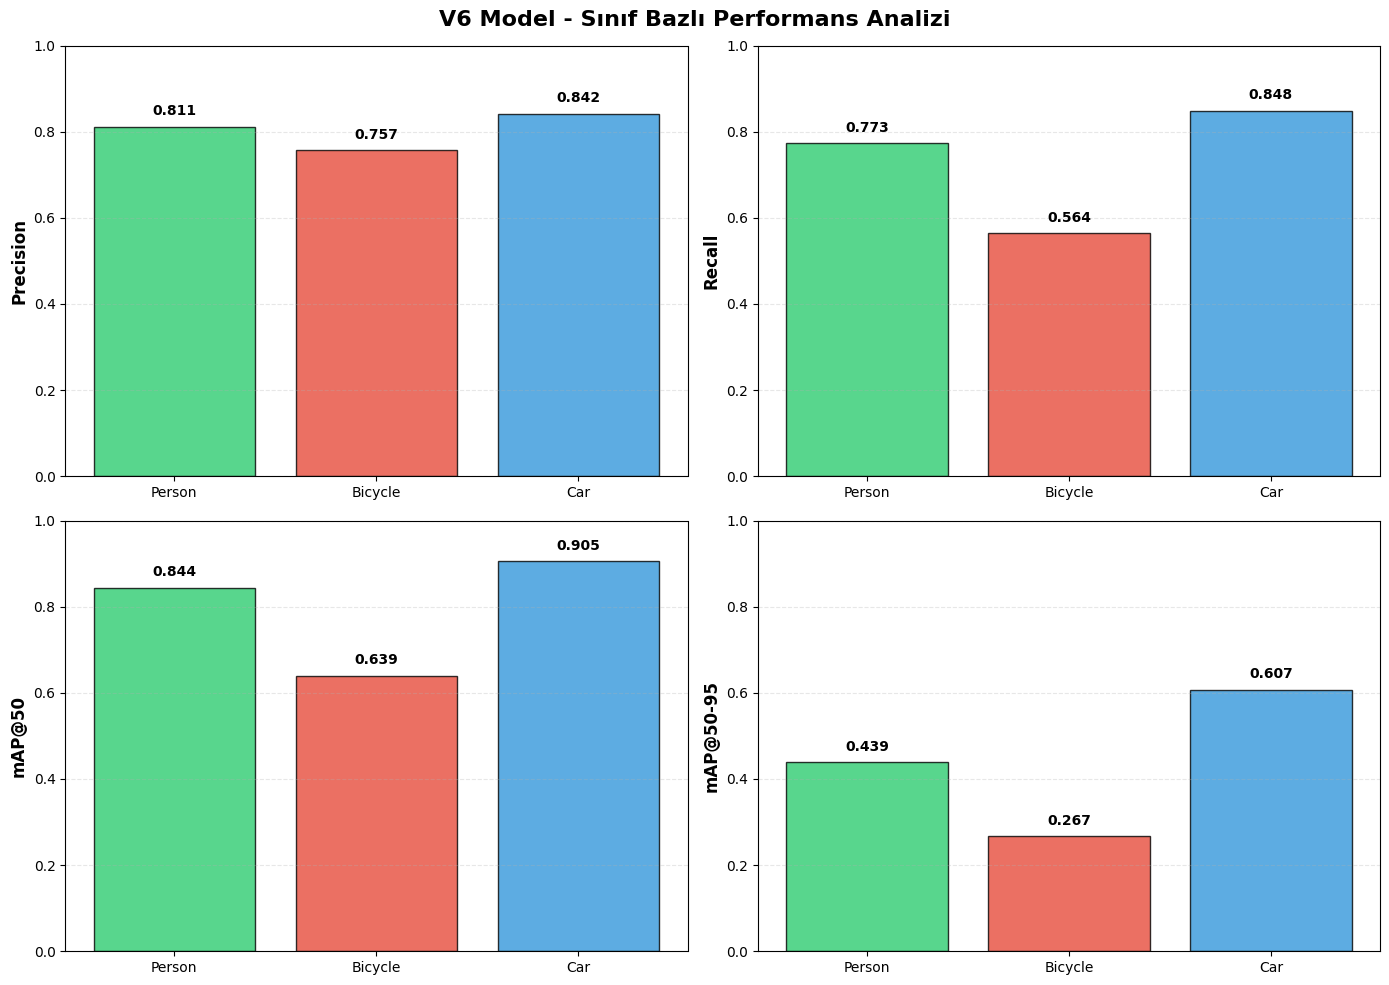

Grafik kaydedildi: /content/drive/MyDrive/tez/runs/v6_class_performance.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

v6_class_stats = {
    'Person': {'Precision': 0.811, 'Recall': 0.773, 'mAP@50': 0.844, 'mAP@50-95': 0.439, 'Count': 5778},
    'Bicycle': {'Precision': 0.757, 'Recall': 0.564, 'mAP@50': 0.639, 'mAP@50-95': 0.267, 'Count': 470},
    'Car': {'Precision': 0.842, 'Recall': 0.848, 'mAP@50': 0.905, 'mAP@50-95': 0.607, 'Count': 5431}
}

classes = list(v6_class_stats.keys())
metrics = ['Precision', 'Recall', 'mAP@50', 'mAP@50-95']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('V6 Model - Sınıf Bazlı Performans Analizi', fontsize=16, fontweight='bold')

for idx, metric in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    values = [v6_class_stats[c][metric] for c in classes]
    bars = ax.bar(classes, values, color=['#2ecc71', '#e74c3c', '#3498db'], alpha=0.8, edgecolor='black')

    ax.set_ylabel(metric, fontsize=12, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3, linestyle='--')

    for bar, val in zip(bars, values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(RUNS_DIR / 'v6_class_performance.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Grafik kaydedildi: {RUNS_DIR / 'v6_class_performance.png'}")

### 7.3 Tüm modeller (V1-V6)

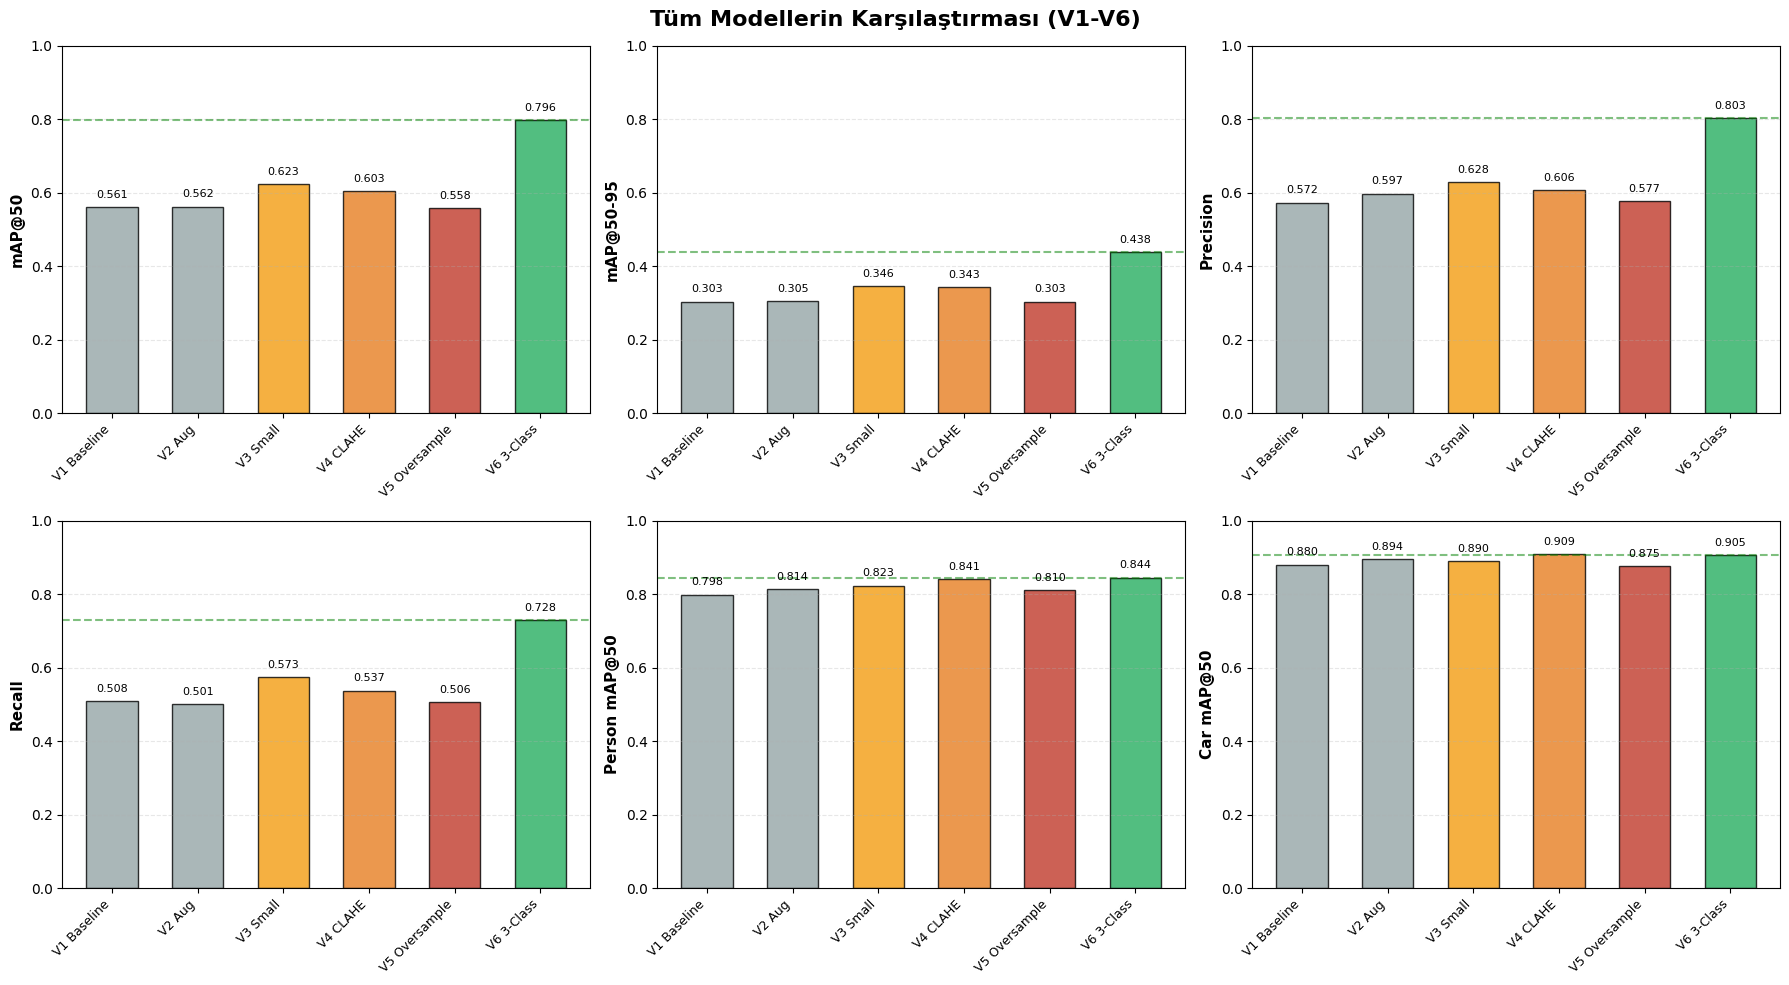

Grafik kaydedildi: /content/drive/MyDrive/tez/runs/all_models_comparison.png


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Tüm Modellerin Karşılaştırması (V1-V6)', fontsize=16, fontweight='bold')

models = df['Model'].tolist()
x = np.arange(len(models))
width = 0.6

metrics_to_plot = [
    ('mAP@50', 'mAP@50'),
    ('mAP@50-95', 'mAP@50-95'),
    ('Precision', 'Precision'),
    ('Recall', 'Recall'),
    ('Person', 'Person mAP@50'),
    ('Car', 'Car mAP@50')
]

for idx, (metric, title) in enumerate(metrics_to_plot):
    ax = axes[idx // 3, idx % 3]
    values = df[metric].tolist()

    colors = ['#95a5a6', '#95a5a6', '#f39c12', '#e67e22', '#c0392b', '#27ae60']
    bars = ax.bar(x, values, width, color=colors, alpha=0.8, edgecolor='black')

    ax.set_ylabel(title, fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right', fontsize=9)
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.axhline(y=values[-1], color='green', linestyle='--', linewidth=1.5, alpha=0.5, label='V6')

    for bar, val in zip(bars, values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(RUNS_DIR / 'all_models_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Grafik kaydedildi: {RUNS_DIR / 'all_models_comparison.png'}")

### 7.4 Adil karşılaştırma: sadece ortak üç sınıf

Yukarıdaki grafiklerde V6'nın mAP@50'si (0.796) diğerlerinden çok yüksek görünüyor. Ama bu kıyas adil değil. V1-V5'in mAP@50 değeri dört sınıfın ortalaması ve dog'un sıfıra yakın değerini de içeriyor. V6 ise sadece üç sınıfın ortalaması. Yani V6'daki sıçramanın önemli bir kısmı modelin daha iyi olmasından değil, ortalamadan sıfır bir değerin çıkarılmasından geliyor.

Validation görüntüleri tüm modellerde aynı olduğu için (6.9) person, bicycle ve car AP'leri doğrudan karşılaştırılabilir. Her model için bu üç sınıfın ortalamasını hesapladım. Dört sınıflı modellerde dog AP'sini de genel mAP'ten geri hesaplayabiliyorum (tablodaki değerler yuvarlanmış olduğu için yaklaşık).

        Model  mAP@50  3 Sınıf Ort.  Dog (hesaplanan)
  V1 Baseline   0.561         0.748             0.000
       V2 Aug   0.562         0.749             0.000
     V3 Small   0.623         0.769             0.185
     V4 CLAHE   0.603         0.799             0.014
V5 Oversample   0.558         0.755             0.000
   V6 3-Class   0.796         0.796               NaN


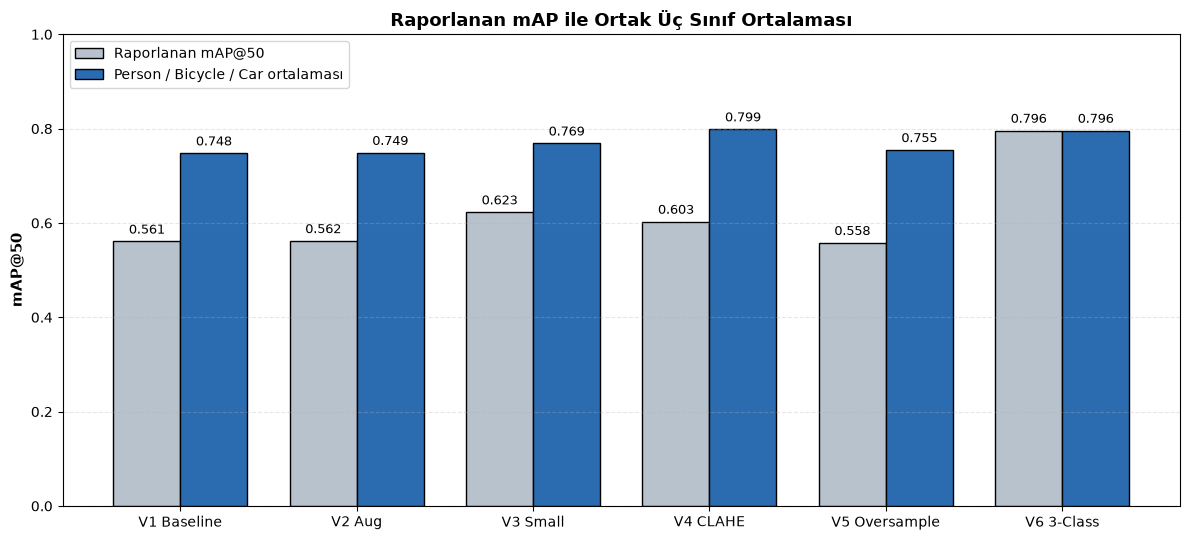

In [ ]:
# V1-V5'in mAP@50 degeri 4 sinifin (dog dahil), V6'ninki 3 sinifin ortalamasi.
# Adil kiyas icin her modelde ortak olan Person, Bicycle ve Car AP'lerinin ortalamasini aliyorum.
df['3 Sınıf Ort.'] = df[['Person', 'Bicycle', 'Car']].mean(axis=1).round(3)

# Dort sinifli modellerde dog AP'si genel ortalamadan geri hesaplanabiliyor: 4 * mAP - (Person + Bicycle + Car)
df['Dog (hesaplanan)'] = (4 * df['mAP@50'] - df[['Person', 'Bicycle', 'Car']].sum(axis=1)).clip(lower=0).round(3)
df.loc[df['Model'] == 'V6 3-Class', 'Dog (hesaplanan)'] = np.nan

print(df[['Model', 'mAP@50', '3 Sınıf Ort.', 'Dog (hesaplanan)']].to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(df))
w = 0.38

b1 = ax.bar(x - w/2, df['mAP@50'], w, label='Raporlanan mAP@50', color='#b8c2cc', edgecolor='black')
b2 = ax.bar(x + w/2, df['3 Sınıf Ort.'], w, label='Person / Bicycle / Car ortalaması', color='#2b6cb0', edgecolor='black')

for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(df['Model'], fontsize=10)
ax.set_ylim(0, 1)
ax.set_ylabel('mAP@50', fontsize=11, fontweight='bold')
ax.set_title('Raporlanan mAP ile Ortak Üç Sınıf Ortalaması', fontsize=13, fontweight='bold')
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(RUNS_DIR / 'fair_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

Ortak üç sınıfa bakınca tablo değişiyor:

- V6'nın asıl kazancı V3'e göre +0.027. Bu artış dog etiketlerinin kaldırılmasından (person ile karışıklığın azalması) ve daha uzun ve sağlıklı bir eğitimden geliyor.
- **V4 (CLAHE) ile V6 pratikte aynı seviyede** (0.799 ve 0.796). Hatta bicycle'da V4 daha iyi (0.648 ve 0.639).
- V5'in oversampling'i ortak sınıflarda da V3'ün gerisinde kalıyor. Ezberleme etkisi burada da görülüyor.
- V1 ile V2 arasında ortak sınıflarda da fark yok. Augmentation tek başına bir şey kazandırmamış.

Final model olarak yine de V6'yı seçtim:

1. **Çıkarım hattı daha basit.** V4'ü kullanmak için sahada her kareye CLAHE uygulamak gerekir. Bu, uç cihazda ek bir işlem adımı ve eğitim ile test arasında tutarlılık riski demek.
2. **Model doğrudan 3 sınıf için eğitildi.** Kullanılmayan dog sınıfı için ayrılmış bir çıkış yok.
3. **Eğitim daha kısa ve kararlı.** 1.85 saat, V4'te 3.5 saat.

V4'teki CLAHE kazancını 3 sınıflı veriyle birleştirmek (CLAHE + 3 sınıf) mantıklı bir sonraki deney olurdu.

### 7.5 V6 eğitim eğrileri

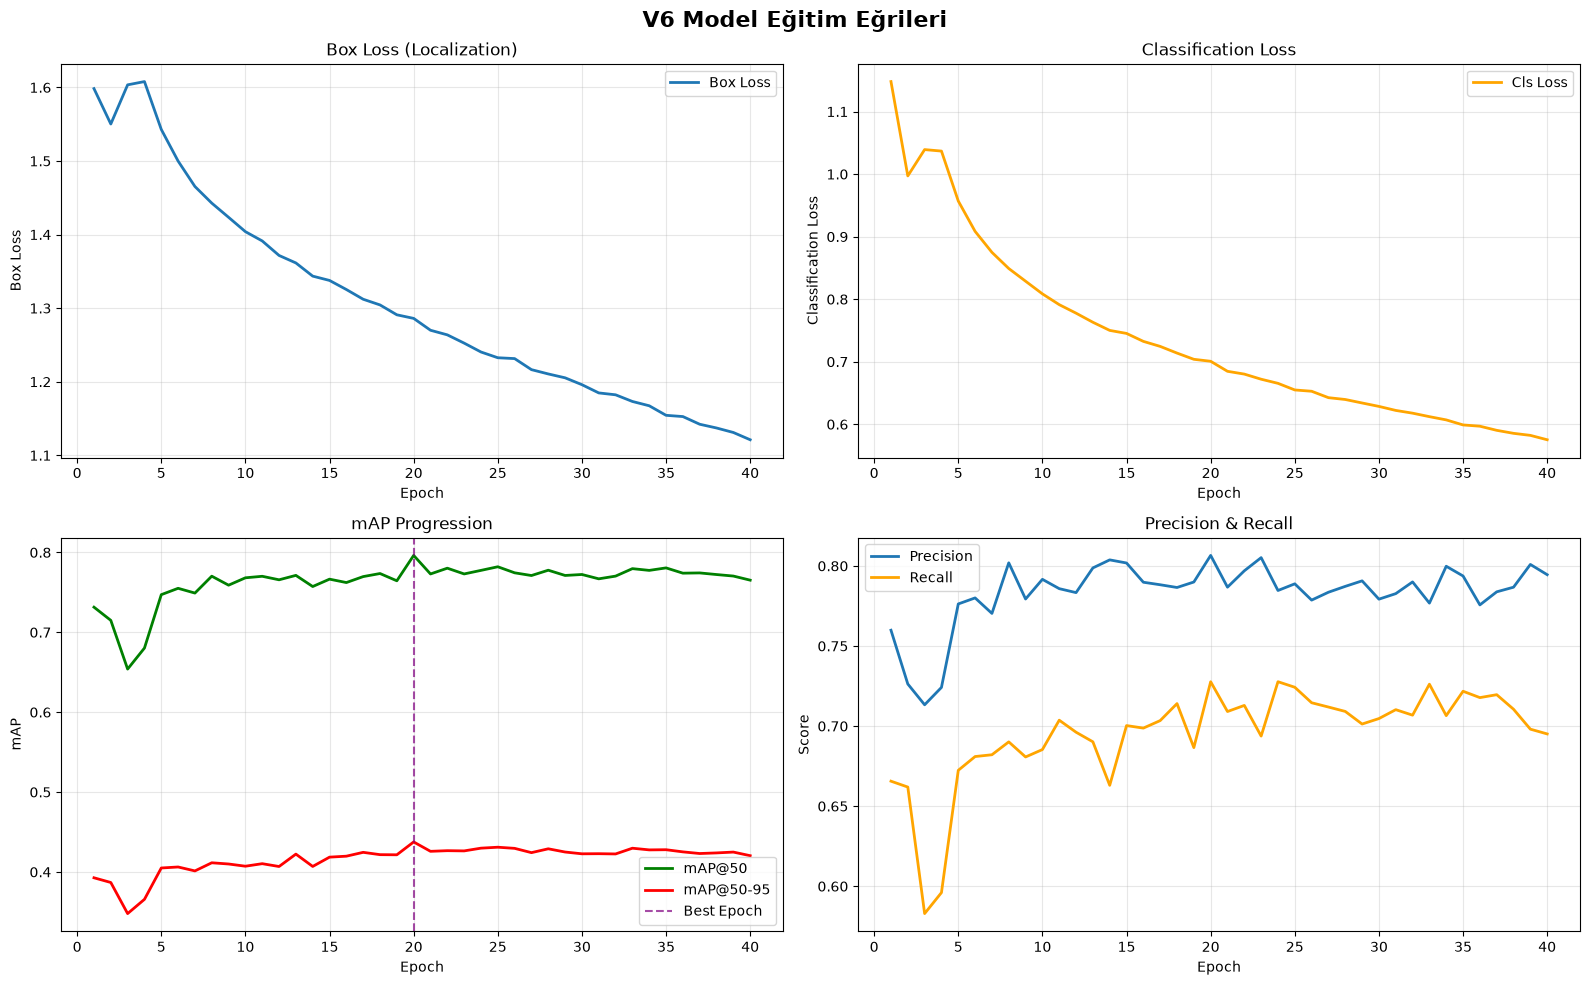

Grafik kaydedildi: /content/drive/MyDrive/tez/runs/v6_training_curves.png


In [ ]:
import pandas as pd

results_csv = RUNS_DIR / 'v6_3class_small' / 'results.csv'

if results_csv.exists():
    results = pd.read_csv(results_csv)
    results.columns = results.columns.str.strip()

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('V6 Model Eğitim Eğrileri', fontsize=16, fontweight='bold')

    epochs = results['epoch']

    ax1 = axes[0, 0]
    ax1.plot(epochs, results['train/box_loss'], label='Box Loss', linewidth=2)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Box Loss')
    ax1.set_title('Box Loss (Localization)')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2 = axes[0, 1]
    ax2.plot(epochs, results['train/cls_loss'], label='Cls Loss', color='orange', linewidth=2)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Classification Loss')
    ax2.set_title('Classification Loss')
    ax2.legend()
    ax2.grid(alpha=0.3)

    ax3 = axes[1, 0]
    ax3.plot(epochs, results['metrics/mAP50(B)'], label='mAP@50', linewidth=2, color='green')
    ax3.plot(epochs, results['metrics/mAP50-95(B)'], label='mAP@50-95', linewidth=2, color='red')
    ax3.axvline(x=20, color='purple', linestyle='--', linewidth=1.5, alpha=0.7, label='Best Epoch')
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('mAP')
    ax3.set_title('mAP Progression')
    ax3.legend()
    ax3.grid(alpha=0.3)

    ax4 = axes[1, 1]
    ax4.plot(epochs, results['metrics/precision(B)'], label='Precision', linewidth=2)
    ax4.plot(epochs, results['metrics/recall(B)'], label='Recall', linewidth=2, color='orange')
    ax4.set_xlabel('Epoch')
    ax4.set_ylabel('Score')
    ax4.set_title('Precision & Recall')
    ax4.legend()
    ax4.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(RUNS_DIR / 'v6_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Grafik kaydedildi: {RUNS_DIR / 'v6_training_curves.png'}")
else:
    print(f"results.csv bulunamadı: {results_csv}")

**Box loss:** 1.60'tan başlayıp 40. epoch'ta 1.12'ye iniyor. 3. ve 4. epoch'ta warmup'a bağlı küçük bir yükselme var, 5. epoch'tan sonra eğri düzgün şekilde azalıyor. V1'de 22 epoch sonunda 1.32'de kalmıştı.

**Classification loss:** 1.15'ten 0.58'e iniyor. Sınıf sayısı 4'ten 3'e düşünce ve en problemli sınıf çıkınca sınıflandırma görevi kolaylaşmış.

**mAP@50:** 1. epoch'ta 0.73 ile başlıyor, warmup sırasında 3. epoch'ta 0.65'e düşüyor ve sonra toparlanıyor. En iyi değer 20. epoch'ta 0.796. Sonrasında 0.77-0.78 bandında kalıyor. V1'e göre dalgalanma çok daha az.

**mAP@50-95:** Aynı desen: 0.39 ile başlıyor, 3. epoch'ta 0.35'e iniyor, 20. epoch'ta 0.438 ile zirve yapıyor.

**Precision ve Recall:** Precision 0.71 ile 0.81 arasında, recall 0.58 ile 0.73 arasında seyrediyor. En iyi epoch'ta precision 0.81, recall 0.73. Precision'ın recall'dan yüksek olması modelin temkinli davrandığını, emin olmadığı tahminleri vermek yerine atladığını gösteriyor.

**Genel değerlendirme:** Eğrilerde ezberleme belirtisi yok. Validation loss train loss ile birlikte iniyor ve mAP bir platoya oturuyor. 20. epoch'tan sonra belirgin bir iyileşme olmadığı için daha uzun eğitimin büyük bir kazanç getireceğini düşünmüyorum. Sıradaki adım bu modeli INT8'e indirip boyut ve hız kazancını ölçmek.

### 7.6 V6 confusion matrix

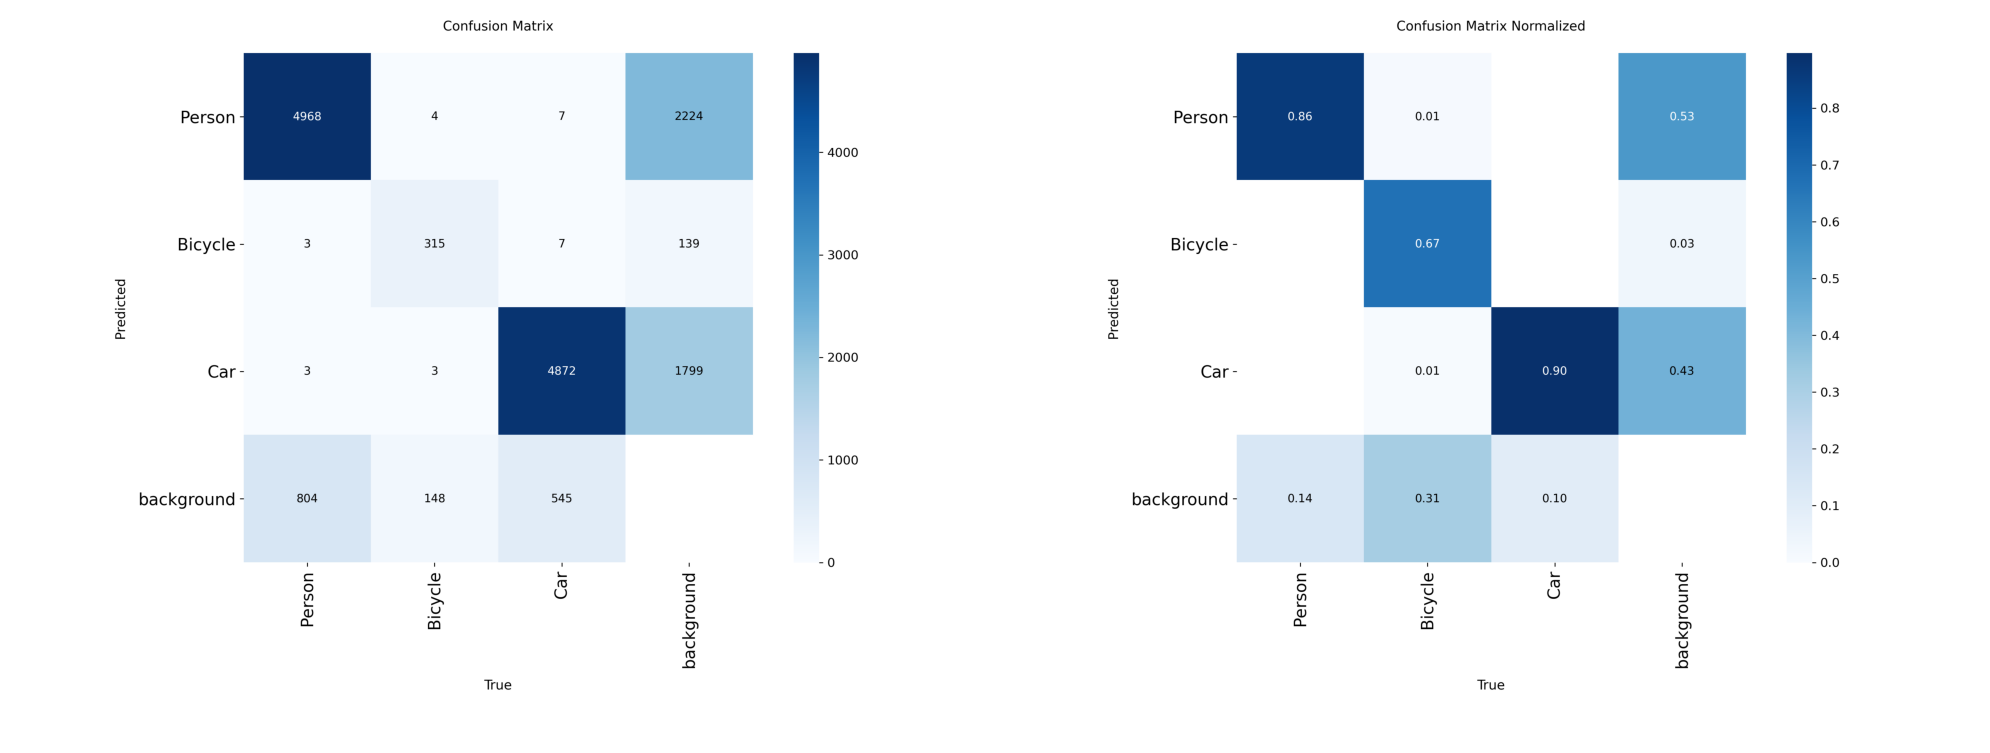

Kaydedildi: /content/drive/MyDrive/tez/runs/v6_3class_small/v6_confusion_matrix_combined.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

base = "/content/drive/MyDrive/tez/runs/v6_3class_small"

cm  = mpimg.imread(f"{base}/confusion_matrix.png")            # Mutlak sayılar
cmn = mpimg.imread(f"{base}/confusion_matrix_normalized.png") # Normalize

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
axes[0].imshow(cm)
axes[0].axis("off")
axes[1].imshow(cmn)
axes[1].axis("off")
plt.tight_layout()

out = f"{base}/v6_confusion_matrix_combined.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
print("Kaydedildi:", out)

V6'da person ve car'ın doğru tespit oranları V1'e göre belirgin şekilde yükseldi. Bicycle hâlâ en zayıf sınıf. Bisikletlerin önemli bir kısmı background'a kaçıyor ve az da olsa person ile karışıyor. Bu beklenen bir karışıklık, çünkü termal görüntüde bisikletli bir insanın en belirgin parçası insanın kendisi.

## 8. Quantization ve Uç Cihaz Optimizasyonu

Bu bölümde V6 modelini farklı formatlara çevirip boyut, doğruluk ve hız açısından karşılaştırdım. Amaç doğruluğu mümkün olduğunca koruyarak modeli küçültmek ve hızlandırmak.

**Formatlar:** PyTorch FP32 (referans), ONNX FP32, TensorRT INT8, ONNX INT8

**Metrikler:** Model boyutu, mAP@50, ortalama ve P95 latency, FPS

**Test ortamı:** Elimde fiziksel bir uç cihaz (örneğin Jetson) olmadığı için GPU testlerini Colab'ın T4 GPU'sunda, CPU testlerini Colab'ın CPU'sunda yaptım. T4, Jetson'a göre çok daha güçlü olduğu için mutlak FPS değerlerinden çok formatlar arasındaki oranlara bakmak daha anlamlı.

**Ölçüm yöntemi:** Her formatta 20 tur ısınmadan sonra 200 kez çıkarım yapıp ortalamasını aldım. P95 latency, en yavaş %5'lik dilimi gösterdiği için gerçek zamanlı bir sistemde ortalamadan daha önemli.

### 8.1 PyTorch FP32 (referans)

In [ ]:
!pip install ultralytics -q # oturum yenilendi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 59.4 MB/s eta 0:00:00


In [ ]:
import time
import torch
import numpy as np
from pathlib import Path
from ultralytics import YOLO

BASE_DIR = Path('/content/drive/MyDrive/tez')
MODEL_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best.pt'
DATA_YAML = BASE_DIR / 'data/thermal_3class.yaml'
IMGSZ = 640
WARMUP_RUNS = 20
BENCHMARK_RUNS = 200

model = YOLO(MODEL_PATH)
dummy_input = torch.zeros(1, 3, IMGSZ, IMGSZ).cuda()

for _ in range(WARMUP_RUNS):
    _ = model.predict(dummy_input, verbose=False)

latencies = []
for _ in range(BENCHMARK_RUNS):
    start = time.perf_counter()
    _ = model.predict(dummy_input, verbose=False)
    torch.cuda.synchronize()
    latencies.append((time.perf_counter() - start) * 1000)

latencies = np.array(latencies)
model_size = MODEL_PATH.stat().st_size / (1024 ** 2)

results = model.val(data=str(DATA_YAML), imgsz=IMGSZ, verbose=False)
map50 = results.box.map50

print(f"Format        : PyTorch FP32")
print(f"Model Boyutu  : {model_size:.1f} MB")
print(f"mAP@50        : {map50:.3f}")
print(f"Ort. Latency  : {latencies.mean():.2f} ms")
print(f"P95 Latency   : {np.percentile(latencies, 95):.2f} ms")
print(f"FPS           : {1000 / latencies.mean():.1f}")

Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 59.9±20.9 MB/s, size: 108.8 KB)
val: Scanning /content/drive/MyDrive/tez/data/val_3class/labels.cache... 1366 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1366/1366 409.2Mit/s 0.0s
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09042.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09055.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09653.jpeg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 86/86 5.2it/s 16.7s
                   all       1366      11679      0.809      0.727      0.796      0.437
Speed: 0.7ms preprocess, 7.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/runs/detect/val2
Format        : PyTorch FP32
Model Boyut

| Metrik | Değer |
|---|---:|
| Format | PyTorch FP32 |
| Dosya boyutu | 18.3 MB |
| mAP@50 | 0.796 |
| Ortalama latency | 9.69 ms |
| P95 latency | 10.05 ms |
| FPS | 103.2 |

Ortalama ile P95 arasındaki fark çok küçük, yani model tutarlı bir hızda çalışıyor.

Dosya boyutu hakkında bir not: Ultralytics `.pt` dosyalarını kaydederken ağırlıkları FP16 olarak saklıyor. Bu yüzden 18.3 MB aslında FP16 boyutu. Çıkarım FP32 ile yapılıyor ve modelin gerçek FP32 boyutu ONNX dosyasında görülüyor (36.2 MB).

### 8.2 ONNX FP32

ONNX, modeli çerçeveden bağımsız bir formata çeviriyor ve INT8 quantization için de başlangıç noktası. `best.onnx` dosyası Ultralytics'in varsayılan ayarlarıyla export edildi:

```python
YOLO('runs/v6_3class_small/weights/best.pt').export(format='onnx', imgsz=640)
```

İlk olarak ONNX Runtime'ı GPU ile çalıştırmaya çalıştım. Colab'daki CUDA sürümüyle uyumlu bir `onnxruntime-gpu` sürümü bulmak için birkaç deneme yaptım ama CUDA execution provider'ı çalıştıramadım.

In [ ]:
!pip uninstall onnxruntime onnxruntime-gpu -y
!pip install onnxruntime-gpu==1.16.3 -q

Found existing installation: onnxruntime-gpu 1.18.0
Uninstalling onnxruntime-gpu-1.18.0:
  Successfully uninstalled onnxruntime-gpu-1.18.0
ERROR: Could not find a version that satisfies the requirement onnxruntime-gpu==1.16.3 (from versions: 1.17.0, 1.17.1, 1.18.0, 1.18.1, 1.19.0, 1.19.2, 1.20.0, 1.20.1, 1.20.2, 1.21.0, 1.21.1, 1.22.0, 1.23.0, 1.23.2, 1.24.1, 1.24.2, 1.24.3, 1.24.4)
ERROR: No matching distribution found for onnxruntime-gpu==1.16.3


In [ ]:
!nvcc --version
import torch
print(torch.version.cuda)

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0
12.8


In [ ]:
import onnxruntime as ort

BASE_DIR = Path('/content/drive/MyDrive/tez')
MODEL_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best.pt'
ONNX_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best.onnx'
DATA_YAML = BASE_DIR / 'data/thermal_3class.yaml'
IMGSZ = 640
WARMUP_RUNS = 20
BENCHMARK_RUNS = 200

session = ort.InferenceSession(
    str(ONNX_PATH),
    providers=['CPUExecutionProvider']
)

input_name = session.get_inputs()[0].name
dummy_input = np.zeros((1, 3, IMGSZ, IMGSZ), dtype=np.float32)

for _ in range(WARMUP_RUNS):
    _ = session.run(None, {input_name: dummy_input})

latencies = []
for _ in range(BENCHMARK_RUNS):
    start = time.perf_counter()
    _ = session.run(None, {input_name: dummy_input})
    latencies.append((time.perf_counter() - start) * 1000)

latencies = np.array(latencies)
onnx_size = ONNX_PATH.stat().st_size / (1024 ** 2)

onnx_model = YOLO(str(ONNX_PATH))
results = onnx_model.val(data=str(DATA_YAML), imgsz=IMGSZ, verbose=False)
map50 = results.box.map50

print(f"Format        : ONNX FP32 (CPU)")
print(f"Model Boyutu  : {onnx_size:.1f} MB")
print(f"mAP@50        : {map50:.3f}")
print(f"Ort. Latency  : {latencies.mean():.2f} ms")
print(f"P95 Latency   : {np.percentile(latencies, 95):.2f} ms")
print(f"FPS           : {1000 / latencies.mean():.1f}")

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify','pose' or 'obb'.
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.onnx for ONNX Runtime inference...
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Using ONNX Runtime 1.24.4 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 70.5±20.3 MB/s, size: 125.0 KB)
val: Scanning /content/drive/MyDrive/tez/data/val_3class/labels.cache... 1366 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1366/1366 301.5Mit/s 0.0s
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09042.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09055.jpeg: 1 duplicate labels removed
val: /content/drive/My

CUDA provider'ı çalışmadığı için ONNX ölçümleri CPU üzerinde:

| Metrik | Değer |
|---|---:|
| Dosya boyutu | 36.2 MB |
| mAP@50 | 0.795 |
| Ortalama latency | 109.65 ms |
| P95 latency | 152.04 ms |
| FPS | 9.1 (CPU) |

mAP neredeyse aynı (0.796 ve 0.795), yani ONNX dönüşümü doğruluğu bozmamış. Bu değer, 8.4'te ONNX INT8'i karşılaştıracağım CPU referansı olacak.

### 8.3 TensorRT INT8

TensorRT, NVIDIA GPU'lar için katmanları birleştiren ve donanıma özel kernel seçen bir çıkarım motoru. INT8 için post-training quantization (PTQ) uyguluyor: bir kalibrasyon seti üzerinden her katmandaki aktivasyonların aralığını ölçüp 8-bit'e ölçekliyor. Ultralytics kalibrasyon için `data` parametresinde verilen yaml'daki görüntüleri kullanıyor.

Engine'i aşağıdaki hücreyle oluşturdum. Bu hücrenin çıktısı video aşamasında aynı ayarlarla yeniden export ettiğim zamana ait.

In [ ]:
!pip install tensorrt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 45.7 MB/s  0:00:00
  Created wheel for tensorrt: filename=tensorrt-10.16.0.72-py3-none-any.whl size=16566 sha256=2856a0646598b7f0b97ff5502bf719cd606ccad13b2cfd8373df3d9bb1978b0b
  Stored in directory: /root/.cache/pip/wheels/94/5f/04/7f93fac79967299afd72fc4feedfa60dbd27352e553e94582b
  Created wheel for tensorrt_cu13: filename=tensorrt_cu13-10.16.0.72-py3-none-any.whl size=23077 sha256=abb5d1a4d5032fcb54cf9470d3fd373878e3dd54a69c4814549cfd2156ed44d5
  Stored in directory: /root/.cache/pip/wheels/11/9d/13/e122974a313a392b70e1943fc72459

In [ ]:
from ultralytics import YOLO

# Ham modelini (PyTorch) yüklüyoruz
model = YOLO("/content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.pt")

# INT8 export. data parametresi kalibrasyon görüntülerinin alınacağı yaml dosyası,
# Ultralytics bu yaml'daki val görüntülerini kalibrasyon için kullanıyor.
model.export(format="engine", int8=True, simplify=True, data="/content/drive/MyDrive/tez/data/thermal_3class.yaml")

WARNING ⚠️ TensorRT requires GPU export, automatically assigning device=0
Ultralytics 8.4.47 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
YOLO11s summary (fused): 101 layers, 9,413,961 parameters, 0 gradients, 21.3 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (18.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime-gpu'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 159ms
Prepared 4 packages in 3.70s
Installed 4 packages in 283ms
 + colorama==0.4.6
 + onnx==1.21.0
 + onnxruntime-gpu==1.25.1
 + onnxslim==0.1.92

requirements: AutoUpdate success ✅ 4.4s
WARNING ⚠️ requirements: Restart runtime or rerun com

PosixPath('/content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.engine')

Engine'i yükleyip aynı benchmark'ı çalıştırıyorum.

In [ ]:
import time
import numpy as np
from pathlib import Path
from ultralytics import YOLO

BASE_DIR = Path('/content/drive/MyDrive/tez')
ENGINE_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best.engine'
DATA_YAML = BASE_DIR / 'data/thermal_3class.yaml'
IMGSZ = 640
WARMUP_RUNS = 20
BENCHMARK_RUNS = 200

trt_model = YOLO(str(ENGINE_PATH))

dummy_frame = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)

for _ in range(WARMUP_RUNS):
    _ = trt_model.predict(source=dummy_frame, verbose=False)

latencies = []
for _ in range(BENCHMARK_RUNS):
    start = time.perf_counter()
    _ = trt_model.predict(source=dummy_frame, verbose=False)
    latencies.append((time.perf_counter() - start) * 1000)

latencies = np.array(latencies)
engine_size = ENGINE_PATH.stat().st_size / (1024 ** 2)

results = trt_model.val(data=str(DATA_YAML), imgsz=IMGSZ, verbose=False)
map50 = results.box.map50

print(f"Format        : TensorRT INT8")
print(f"Model Boyutu  : {engine_size:.1f} MB")
print(f"mAP@50        : {map50:.3f}")
print(f"Ort. Latency  : {latencies.mean():.2f} ms")
print(f"P95 Latency   : {np.percentile(latencies, 95):.2f} ms")
print(f"FPS           : {1000 / latencies.mean():.1f}")

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify','pose' or 'obb'.
Loading /content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.engine for TensorRT inference...
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.engine for TensorRT inference...
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 61.6±20.1 MB/s, size: 133.4 KB)
val: Scanning /content/drive/MyDrive/tez/data/val_3class/labels.cache... 1366 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1366/1366 337.0Mit/s 0.0s
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09042.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09055.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images

| Metrik | PyTorch FP32 | TensorRT INT8 | Değişim |
|---|---:|---:|---:|
| Dosya boyutu | 18.3 MB (FP16 kayıt) | 12.2 MB | -%34 |
| mAP@50 | 0.796 | 0.760 | -0.036 |
| Ortalama latency | 9.69 ms | 4.37 ms | 2.2 kat hızlı |
| P95 latency | 10.05 ms | 5.33 ms | |
| FPS | 103.2 | 229.0 | 2.2 kat |

Latency 9.69 ms'den 4.37 ms'ye indi, FPS 2.2 katına çıktı. P95 de dar kalmış, yani hızlanma tutarlı. Dosya boyutu `.pt`'ye göre %34 küçüldü. Gerçek FP32 boyutuyla (36.2 MB) kıyaslarsak küçülme %66. Engine'in INT8'in teorik olarak sağlayacağı 4 kat küçülmeye ulaşmamasının sebebi, bazı katmanların FP16/FP32'de kalması ve dosyanın TensorRT'nin kendi meta verisini de içermesi.

Ölçüm yöntemiyle ilgili bir not: PyTorch benchmark'ında modele doğrudan GPU'daki bir tensör verdim. TensorRT'de ise numpy dizisi verdim, yani TensorRT'nin süresine ön işleme ve son işleme de dahil. Karşılaştırma TensorRT aleyhine. Validation sırasında Ultralytics'in raporladığı saf çıkarım süreleri de aynı tabloyu veriyor: PyTorch 7.1 ms, TensorRT 3.3 ms.

**mAP kaybı:** 0.796'dan 0.760'a, yani 0.036 puan (%4.5) düşüş. Kendime %3 hedefi koymuştum, biraz aşıldı. Sınıf bazlı kaybı 8.5'te inceliyorum.

### 8.4 ONNX INT8 (dynamic quantization)

ONNX tarafında `onnxruntime.quantization` içindeki `quantize_dynamic` fonksiyonunu kullandım. Dynamic quantization kalibrasyon seti istemiyor: ağırlıklar önceden INT8'e çevriliyor, aktivasyonların ölçeği ise her çıkarımda anlık olarak hesaplanıyor.

In [ ]:
!pip install onnxruntime onnx -q

In [ ]:

import onnx
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

BASE_DIR = Path('/content/drive/MyDrive/tez')
ONNX_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best.onnx'
ONNX_INT8_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best_int8.onnx'
DATA_YAML = BASE_DIR / 'data/thermal_3class.yaml'
IMGSZ = 640
WARMUP_RUNS = 20
BENCHMARK_RUNS = 200

quantize_dynamic(
    model_input=str(ONNX_PATH),
    model_output=str(ONNX_INT8_PATH),
    weight_type=QuantType.QInt8
)

session = ort.InferenceSession(
    str(ONNX_INT8_PATH),
    providers=['CPUExecutionProvider']
)

input_name = session.get_inputs()[0].name
dummy_input = np.zeros((1, 3, IMGSZ, IMGSZ), dtype=np.float32)

for _ in range(WARMUP_RUNS):
    _ = session.run(None, {input_name: dummy_input})

latencies = []
for _ in range(BENCHMARK_RUNS):
    start = time.perf_counter()
    _ = session.run(None, {input_name: dummy_input})
    latencies.append((time.perf_counter() - start) * 1000)

latencies = np.array(latencies)
int8_size = ONNX_INT8_PATH.stat().st_size / (1024 ** 2)

onnx_model = YOLO(str(ONNX_INT8_PATH))
results = onnx_model.val(data=str(DATA_YAML), imgsz=IMGSZ, verbose=False)
map50 = results.box.map50

print(f"Format        : ONNX INT8 (Dynamic)")
print(f"Model Boyutu  : {int8_size:.1f} MB")
print(f"mAP@50        : {map50:.3f}")
print(f"Ort. Latency  : {latencies.mean():.2f} ms")
print(f"P95 Latency   : {np.percentile(latencies, 95):.2f} ms")
print(f"FPS           : {1000 / latencies.mean():.1f}")

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify','pose' or 'obb'.
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/drive/MyDrive/tez/runs/v6_3class_small/weights/best_int8.onnx for ONNX Runtime inference...
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...
Using ONNX Runtime 1.24.4 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 68.6±22.3 MB/s, size: 130.5 KB)
val: Scanning /content/drive/MyDrive/tez/data/val_3class/labels.cache... 1366 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1366/1366 318.3Mit/s 0.0s
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09042.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09055.jpeg: 1 duplicate labels removed
val: /content/dri

| Metrik | ONNX FP32 (CPU) | ONNX INT8 (CPU) |
|---|---:|---:|
| Dosya boyutu | 36.2 MB | 9.4 MB |
| mAP@50 | 0.795 | 0.785 |
| Ortalama latency | 109.65 ms | 576.41 ms |
| P95 latency | 152.04 ms | 852.89 ms |
| FPS | 9.1 | 1.7 |

Doğruluk çok iyi korunmuş, sadece 0.010 puan kayıp. Boyut 36.2 MB'den 9.4 MB'ye indi, INT8'den beklenen yaklaşık 4 kat küçülme.

Ama hız tarafında beklenenin tam tersi oldu: INT8 model aynı CPU'da FP32'den **5 kat daha yavaş**. Bunun sebebi dynamic quantization'ın bu tür bir model için uygun olmaması. Dynamic quantization asıl olarak Transformer ve LSTM gibi matris çarpımı ağırlıklı modeller için tasarlanmış. Konvolüsyon katmanlarında ONNX Runtime `ConvInteger` operatörünü kullanıyor ve bu operatör CPU'da iyi optimize edilmemiş. Üstüne her katmanda aktivasyonları anlık olarak quantize edip geri çevirmenin ek maliyeti geliyor. Ayrıca ONNX Runtime quantization öncesinde ön işleme (`quant_pre_process`) önerdi, bunu atlamıştım.

Doğru yöntem kalibrasyon setiyle **static quantization** (QDQ formatı) olurdu. Bu yöntemde aktivasyon ölçekleri önceden hesaplanıyor ve konvolüsyonlar gerçekten INT8 olarak çalışıyor. Bunu sonraki çalışmalara bıraktım. Bu deneyden çıkardığım asıl sonuç: boyutu küçültmek hızlanma anlamına gelmiyor, quantization yöntemi hedef donanıma ve operatörlere göre seçilmeli.

### 8.5 TensorRT INT8 sınıf bazlı kayıp

In [ ]:
from pathlib import Path
from ultralytics import YOLO

BASE_DIR = Path('/content/drive/MyDrive/tez')
ENGINE_PATH = BASE_DIR / 'runs/v6_3class_small/weights/best.engine'
DATA_YAML = BASE_DIR / 'data/thermal_3class.yaml'

trt_model = YOLO(str(ENGINE_PATH))
results = trt_model.val(data=str(DATA_YAML), imgsz=640, verbose=True)

for i, name in enumerate(['person', 'bicycle', 'car']):
    print(f"{name:10} mAP@50: {results.box.ap50[i]:.3f}  mAP@50-95: {results.box.ap[i]:.3f}")

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify','pose' or 'obb'.
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Loading /content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.engine for TensorRT inference...
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 54.9±18.7 MB/s, size: 120.1 KB)
val: Scanning /content/drive/MyDrive/tez/data/val_3class/labels.cache... 1366 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1366/1366 260.4Mit/s 0.0s
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09042.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09055.jpeg: 1 duplicate labels removed
val: /content/drive/MyDrive/tez/data/val_3class/images/FLIR_09653.jpeg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P  

| Sınıf | FP32 mAP@50 | INT8 mAP@50 | Fark | FLIR baseline |
|---|---:|---:|---:|---:|
| Person | 0.844 | 0.798 | -0.046 | 0.794 |
| Bicycle | 0.639 | 0.598 | -0.041 | 0.580 |
| Car | 0.905 | 0.885 | -0.020 | 0.856 |
| Genel | 0.796 | 0.760 | -0.036 | |

En büyük kayıp person ve bicycle'da, car neredeyse korunmuş. Bu da veri analizindeki bulgularla uyumlu. Person ve bicycle kutularının çoğu küçük ve düşük kontrastlı. INT8'de aktivasyon değerleri 256 seviyeye sıkıştırılınca bu nesneleri arka plandan ayıran ince yoğunluk farkları kayboluyor. Car ise büyük ve belirgin olduğu için hassasiyet kaybından daha az etkileniyor.

Kayba rağmen INT8 model üç sınıfta da FLIR'ın RefineDet512 baseline'ının üzerinde kalıyor.

INT8 kaybını azaltmak için denenebilecekler:

- **TensorRT FP16:** INT8 kadar hızlı değil ama doğruluk kaybı genellikle ihmal edilebilir seviyede. İyi bir ara seçenek.
- **Kalibrasyon setini büyütmek ve train'den seçmek:** Şu an kalibrasyon val görüntüleriyle yapılıyor (aşağıda sınırlılıklarda tartıştım).
- **Hassas katmanları FP16'da bırakmak (mixed precision):** Özellikle detection head katmanları.
- **Quantization-aware training (QAT):** Modeli quantization etkisini görerek yeniden eğitmek.

### 8.6 Format karşılaştırmasının özeti

| Format | Donanım | Boyut | mAP@50 | Ort. latency | FPS |
|---|---|---:|---:|---:|---:|
| PyTorch FP32 | T4 GPU | 18.3 MB* | 0.796 | 9.69 ms | 103.2 |
| TensorRT INT8 | T4 GPU | 12.2 MB | 0.760 | 4.37 ms | 229.0 |
| ONNX FP32 | CPU | 36.2 MB | 0.795 | 109.65 ms | 9.1 |
| ONNX INT8 (dynamic) | CPU | 9.4 MB | 0.785 | 576.41 ms | 1.7 |

\* Ağırlıklar FP16 olarak saklanıyor.

GPU'lu bir uç cihaz için en uygun seçenek TensorRT INT8. 0.036 puanlık mAP kaybına karşılık 2.2 kat hızlanma sağlıyor. Car gibi ADAS açısından en kritik sınıflardan birinde kayıp çok düşük (0.020).

## 9. Test Videosu Üzerinde Çıkarım

FLIR veri setinde etiketli görüntülerin yanında 144 saniyelik kesintisiz bir video da var (4,224 kare). Bu kareler eğitimde hiç kullanılmadı. Modeli gerçek bir sürüş akışında görmek için kareleri 30 FPS'lik bir videoya çevirdim.

In [ ]:
import cv2
import glob
import os

# FLIR'in 144 saniyelik video karelerini tek bir videoya birlestiriyorum
image_folder = '/content/drive/MyDrive/tez/data/video/thermal_8_bit'
video_path = '/content/drive/MyDrive/tez/test_video.mp4'

# Tum jpg/jpeg uzantili kareleri topluyorum
images = []
for ext in ('*.jpeg', '*.jpg', '*.JPEG', '*.JPG'):
    images.extend(glob.glob(os.path.join(image_folder, ext)))

# Kare sirasi bozulmasin diye isme gore siraliyorum
images = sorted(images)

if not images:
    print(f"Klasörde kare bulunamadı: {image_folder}")
else:
    print(f"Toplam {len(images)} kare bulundu. Video oluşturuluyor...")

    # Video boyutunu ilk kareden aliyorum
    frame = cv2.imread(images[0])
    height, width, layers = frame.shape

    # Video oluşturucu (30 FPS)
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    video = cv2.VideoWriter(video_path, fourcc, 30.0, (width, height))

    for image in images:
        video.write(cv2.imread(image))

    video.release()
    print("İşlem tamam. test_video.mp4 dosyası tez klasörüne kaydedildi.")

Toplam 4224 kare bulundu. Video oluşturuluyor...
İşlem tamam. test_video.mp4 dosyası tez klasörüne kaydedildi.


Videoyu TensorRT INT8 engine ile işledim. Confidence eşiğini 0.5 tuttum, böylece sadece modelin emin olduğu tespitler çiziliyor. Tüm kare logunu kısalttım, sadece başı ve sonu duruyor.

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 64.4 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

# TensorRT INT8 engine'i yukluyorum
model = YOLO("/content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.engine")

# conf=0.5: sadece %50 ve uzeri emin olunan tespitler ciziliyor
# line_width=3: sunumda kutular daha rahat gorunsun diye
results = model.predict(
    source="/content/drive/MyDrive/tez/test_video.mp4",
    save=True,
    conf=0.5,
    imgsz=640,
    project="/content/drive/MyDrive/tez/inference_results",
    name="renkli_deneme",
    exist_ok=True,
    line_width=3
)

print("İşlem bitti! Şimdi .avi'yi .mp4'e çevirelim.")

WARNING ⚠️ Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify','pose' or 'obb'.
Loading /content/drive/MyDrive/tez/runs/v6_3class_small/weights/best.engine for TensorRT inference...

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs


... (4,224 karelik log kısaltıldı) ...

video 1/1 (frame 4221/4224) /content/drive/MyDrive/tez/test_video.mp4: 640x640 5 Cars, 4.1ms
video 1/1 (frame 4222/4224) /content/drive/MyDr

In [ ]:
!ffmpeg -i "/content/drive/MyDrive/tez/inference_results/renkli_deneme/test_video.avi" -c:v libx264 -crf 23 -preset medium "/content/drive/MyDrive/tez/v6_final_sunum.mp4" -y

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

Videodaki 4,224 kare kare başına ortalama 2.2 ms ön işleme, 4.0 ms çıkarım ve 1.3 ms son işleme ile işlendi. Yani toplamda kare başına yaklaşık 7.5 ms, bu da 130 FPS civarında bir uçtan uca hıza karşılık geliyor. Videonun kendisi 30 FPS olduğu için model gerçek zamanın yaklaşık 4 katı hızda çalışıyor.

Ultralytics çıktıyı `.avi` olarak kaydettiği için sunumda kullanabilmek amacıyla ffmpeg ile `.mp4`'e çevirdim.

## 10. Sonuç

### Neler yaptım

1. FLIR ADAS veri setini analiz ettim ve üç temel sorunu belirledim: ciddi sınıf dengesizliği (car/dog 182:1), küçük nesne baskınlığı (%58.3) ve bazı karelerde çok düşük kontrast.
2. YOLO11n ile bir baseline kurdum (mAP@50 0.561) ve hataların nereden geldiğini sınıf bazında, confusion matrix ve PR eğrileriyle inceledim.
3. Her seferinde tek bir değişkeni değiştirerek beş iyileştirme denemesi yaptım: offline augmentation, daha büyük model, CLAHE, oversampling ve 3 sınıfa geçiş.
4. Final modeli (V6) PyTorch, ONNX ve TensorRT formatlarına çevirip doğruluk-hız dengesini ölçtüm.

### Ana bulgular

- **Dog sınıfı bu veriyle öğrenilemiyor.** Ne augmentation ne oversampling ne de daha büyük model işe yaradı. Sınıfı çıkarmak, FLIR'ın kendi değerlendirmesiyle de uyumlu bir karar oldu.
- **Model büyüklüğü en tutarlı kazancı sağladı.** YOLO11n'den YOLO11s'e geçiş ortak üç sınıfta yaklaşık 2 puan kazandırdı.
- **CLAHE en iyi ön işleme oldu.** Person, bicycle ve car'da en yüksek değerleri V4 verdi, özellikle bicycle'da.
- **Oversampling zarar verdi.** Aynı görüntülerin tekrar tekrar gösterilmesi modelin ezberlemesine yol açtı.
- **Genel mAP tek başına yanıltıcı.** V6'nın 0.796'lık değeri ilk bakışta V3'e göre 17 puanlık bir sıçrama gibi görünüyor ama ortak sınıflarda gerçek kazanç yaklaşık 3 puan.
- **TensorRT INT8, 2.2 kat hızlanma ve 0.036 puanlık mAP kaybı** sağladı. INT8 model bile üç sınıfta FLIR baseline'ının üzerinde.
- **Quantization yöntemi donanıma göre seçilmeli.** ONNX dynamic INT8 boyutu 4 kat küçülttü ama CPU'da modeli 5 kat yavaşlattı.

### Sınırlılıklar

- **Validation seti hem model seçimi hem raporlama için kullanıldı.** FLIR'ın etiketli ayrı bir test seti yok. Erken durdurma ve en iyi epoch seçimi de val setine göre yapıldığı için raporlanan değerler hafif iyimser olabilir.
- **INT8 kalibrasyonu da val setiyle yapıldı.** mAP aynı set üzerinden ölçüldüğü için INT8 sonucu da hafif iyimser olabilir. Kalibrasyon için train setinden ayrı bir alt küme kullanmak daha doğru olurdu.
- **Augmented görüntüler orijinal train klasörüne yazıldı.** Bu yüzden V2 sonrası tüm modeller genişletilmiş set üzerinde eğitildi ve V1 ile karşılaştırmada veri miktarı da değişmiş oldu.
- **V4'te train CLAHE'li, val CLAHE'siz.** CLAHE'nin etkisi tam olarak ölçülmüş değil.
- **Her deney tek seed ile koşuldu.** Modeller arasındaki 1-2 puanlık farkların ne kadarının rastlantısal olduğunu bilmiyorum. Birkaç farklı seed ile tekrar etmek gerekir.
- **Gerçek bir uç cihazda test yapılmadı.** Tüm ölçümler Colab T4 GPU ve Colab CPU üzerinde.

### Sonraki adımlar

1. CLAHE ile 3 sınıflı veriyi birleştirmek (V4 + V6) ve val setine de CLAHE uygulamak
2. TensorRT FP16 ve mixed precision INT8 denemek
3. ONNX için kalibrasyonlu static quantization (QDQ) uygulamak
4. Modeli Jetson Orin Nano gibi gerçek bir cihazda test etmek
5. Küçük nesneler için daha yüksek çözünürlük (imgsz 800-960) veya P2 katmanlı bir mimari denemek